In [1]:
import fitz  # PyMuPDF
import pandas as pd
import numpy as np
import re
import os
from PIL import Image
import io
import matplotlib.pyplot as plt

In [2]:
pdf_file = '/Users/rodrigocarrillo/Library/CloudStorage/OneDrive-EmoryUniversity/Natural Language Processing Projects/Examen Residentado Peru/CONAREME/Year2022/Ginecología y Obstetricia.pdf'

In [3]:
def extract_questions(pdf_path):
    doc = fitz.open(pdf_path)
    questions_data = []  # List to store questions

    # Updated regular expression: handle questions with or without a '?'
    #question_pattern = re.compile(r"(\d+)\.\s(.*?)(?:\?)?\s*(?=A\.)", re.DOTALL)
    question_pattern = re.compile(r"(\d+)\.\s(.*?\??)\s*(?=A\.)", re.DOTALL)

    for page in doc:
        text = page.get_text("text")  # Extract full page text
        
        # Find all questions in the text using findall()
        questions = question_pattern.findall(text)
        
        # Append all the questions to the questions_data list
        for _, question in questions:
            questions_data.append(question.strip())  # Store the cleaned question text

    # Convert extracted questions to DataFrame
    questions_df = pd.DataFrame(questions_data, columns=["question"])
    return questions_df

In [4]:
def extract_answers(pdf_path):
    doc = fitz.open(pdf_path)
    answers_data = []  # List to store answers for each question

    # Regular expression for extracting answers
    answer_pattern = re.compile(r"^(A|B|C|D|E)\.\s(.+)", re.MULTILINE)

    for page in doc:
        text = page.get_text("text")  # Extract full page text
        lines = text.split("\n")  # Split into lines for structured parsing

        current_answers = []  # List to store answers for a given question
        for line in lines:
            answer_match = answer_pattern.match(line)
            if answer_match:
                opt, ans_text = answer_match.groups()
                current_answers.append(ans_text.strip())

            # After four options are found, store them as one row in answers_data
            if len(current_answers) == 5:
                answers_data.append(current_answers)
                current_answers = []  # Reset for next question

    # Convert extracted answers to DataFrame with four columns
    answers_df = pd.DataFrame(answers_data, columns = ["option_A", "option_B", "option_C", "option_D", "option_E"])
    return answers_df

In [5]:
def get_largest_rectangle(rects):
    """Return the largest rectangle from a list of rectangles."""
    if not rects:
        return None
    
    # Calculate area for each rectangle and store with index
    areas = [(abs((rect.br.x - rect.tl.x) * (rect.br.y - rect.tl.y)), idx) 
             for idx, rect in enumerate(rects)]
    
    # Sort by area (first element of tuple)
    areas.sort(key=lambda x: x[0], reverse=True)
    
    # Return the rectangle with largest area
    return rects[areas[0][1]]

def extract_correct_answers(pdf_path):
    doc = fitz.open(pdf_path)
    correct_answers = []
    missing_questions = []  # Track questions that were skipped
    
    # Flexible regex for answer choices (handles missing spaces like "A." and "A. ")
    answer_pattern = re.compile(r"^(A|B|C|D|E)\.\s(.+)", re.MULTILINE)
    
    for page_num, page in enumerate(doc, start=1):
        text = page.get_text("text")  # Extract full page text
        lines = text.split("\n")  # Split into lines
        
        # Extract valid answer positions using regex
        answer_positions = {key: [] for key in ["A", "B", "C", "D", "E"]}
        
        for line in lines:
            match = answer_pattern.match(line)
            if match:
                answer_letter, answer_text = match.groups()
                
                # Try different search variations to find the best match
                search_texts = [
                    match.group(0),  # Original matched text
                    match.group(0).strip(),  # Stripped version
                    answer_letter + '.' + answer_text,  # Without space after period
                    answer_letter.upper() + '. ' + answer_text,  # Different case
                ]
                
                rects = None
                used_search_text = ""
                
                # Find the first successful search
                for search_text in search_texts:
                    rects = page.search_for(search_text)
                    if rects:
                        used_search_text = search_text
                        break
                
                if rects:
                    # Select the largest rectangle
                    largest_rect = get_largest_rectangle(rects)
                    if largest_rect:
                        answer_positions[answer_letter].append(largest_rect)
        
        # Find the maximum number of questions on the page
        num_questions = max(len(answer_positions["A"]), len(answer_positions["B"]), len(answer_positions["C"]),
                          len(answer_positions["D"]), len(answer_positions["E"]))
        
        # Debugging: Show how many answers were found
        print(f"\nPage {page_num}: Found {num_questions} questions")
        
        for idx in range(num_questions):
            best_answer = None
            best_yellow_pixels = 0  # Track the highest number of yellow pixels
            has_all_options = True  # Flag to check if we have all 4 options
            
            for answer_letter in ["A", "B", "C", "D", "E"]:
                rects = answer_positions[answer_letter]
                if idx >= len(rects):
                    has_all_options = False  # Missing one or more options
                    continue
                
                rect = rects[idx]
                
                # Debugging: Print detected answer positions
                print(f"Page {page_num}, Q{idx+1} - {answer_letter}: Detected box: "
                      f"x0={rect.x0:.1f}, y0={rect.y0:.1f}, x1={rect.x1:.1f}, y1={rect.y1:.1f}")
                
                # Expand bounding box only to the right
                expanded_rect = fitz.Rect(rect.x0, rect.y0, rect.x1 + 50, rect.y1)
                
                # Extract pixels from the expanded region
                pixmap = page.get_pixmap(clip=expanded_rect)
                img = np.frombuffer(pixmap.samples, dtype=np.uint8).reshape(pixmap.h, pixmap.w, pixmap.n)
                
                # Count yellow pixels (pixels with high red and green, low blue)
                yellow_mask = (
                    (img[:, :, 0] > 200) &  # High red
                    (img[:, :, 1] > 200) &  # High green
                    (img[:, :, 2] < 150)    # Low blue
                )
                yellow_pixels = np.sum(yellow_mask)
                
                # Count total non-white pixels
                nonwhite_mask = ~np.all(img > 250, axis=2)
                total_pixels = np.sum(nonwhite_mask)
                
                # Debug information
                print(f"Page {page_num}, Q{idx+1}, {answer_letter}: Yellow pixels: {yellow_pixels}")
                print(f"Page {page_num}, Q{idx+1}, {answer_letter}: Total non-white pixels: {total_pixels}")
                
                if total_pixels > 0:
                    yellow_percentage = (yellow_pixels / total_pixels) * 100
                    print(f"Page {page_num}, Q{idx+1}, {answer_letter}: Yellow percentage: {yellow_percentage:.1f}%")
                
                # Display the box in the notebook
                plt.figure(figsize=(8, 4))
                plt.imshow(img)
                plt.gca().add_patch(plt.Rectangle((0, 0), expanded_rect.width, expanded_rect.height,
                                                fill=False, color='red', linewidth=2))
                plt.title(f'Page {page_num}, Q{idx+1}, Answer {answer_letter}\nYellow pixels: {yellow_pixels}')
                plt.axis('off')
                plt.show()
                
                # Store the best answer based on the highest number of yellow pixels
                if yellow_pixels > best_yellow_pixels:
                    best_yellow_pixels = yellow_pixels
                    best_answer = answer_letter
            
            # If missing options, log missing questions
            if not has_all_options:
                missing_questions.append(f"Page {page_num}, Q{idx+1}")
            
            if best_answer:
                correct_answers.append(best_answer)
                print(f"\nPage {page_num}, Q{idx+1} - Selected Answer: {best_answer} (based on yellow pixel count)")
                print("====================================================================================================")
                print("\n")
                print("\n")
            else:
                correct_answers.append("DK")
    
    # Debugging: Print missing questions
    if missing_questions:
        print("\n⚠️ The following questions were skipped due to missing options:")
        for q in missing_questions:
            print(q)
    
    return pd.DataFrame(correct_answers, columns=["correct_answer"])


Page 1: Found 9 questions
Page 1, Q1 - A: Detected box: x0=68.3, y0=102.0, x1=211.8, y1=114.7
Page 1, Q1, A: Yellow pixels: 0
Page 1, Q1, A: Total non-white pixels: 786
Page 1, Q1, A: Yellow percentage: 0.0%


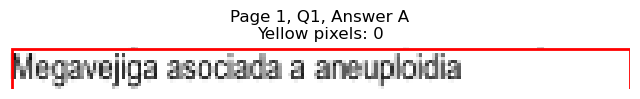

Page 1, Q1 - B: Detected box: x0=68.3, y0=114.6, x1=141.5, y1=127.3
Page 1, Q1, B: Yellow pixels: 124
Page 1, Q1, B: Total non-white pixels: 506
Page 1, Q1, B: Yellow percentage: 24.5%


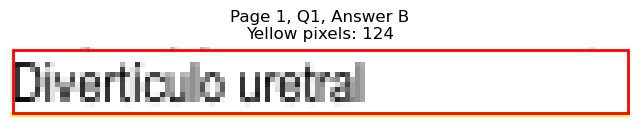

Page 1, Q1 - C: Detected box: x0=68.8, y0=127.2, x1=190.1, y1=139.9
Page 1, Q1, C: Yellow pixels: 1762
Page 1, Q1, C: Total non-white pixels: 2249
Page 1, Q1, C: Yellow percentage: 78.3%


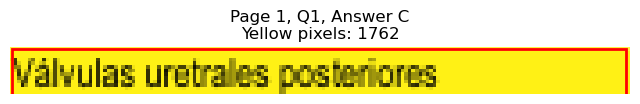

Page 1, Q1 - D: Detected box: x0=327.5, y0=102.0, x1=395.7, y1=114.7
Page 1, Q1, D: Yellow pixels: 0
Page 1, Q1, D: Total non-white pixels: 352
Page 1, Q1, D: Yellow percentage: 0.0%


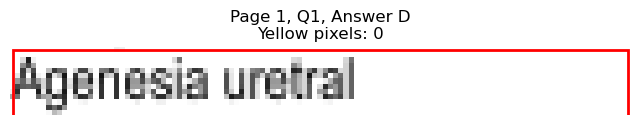

Page 1, Q1 - E: Detected box: x0=327.0, y0=114.6, x1=438.9, y1=127.3
Page 1, Q1, E: Yellow pixels: 0
Page 1, Q1, E: Total non-white pixels: 569
Page 1, Q1, E: Yellow percentage: 0.0%


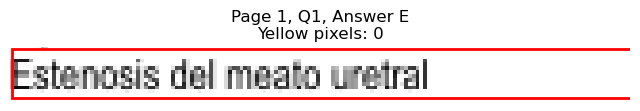


Page 1, Q1 - Selected Answer: C (based on yellow pixel count)




Page 1, Q2 - A: Detected box: x0=68.3, y0=177.7, x1=265.0, y1=190.4
Page 1, Q2, A: Yellow pixels: 2
Page 1, Q2, A: Total non-white pixels: 975
Page 1, Q2, A: Yellow percentage: 0.2%


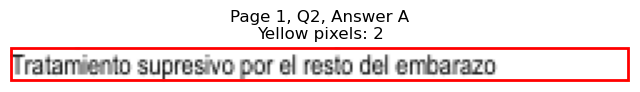

Page 1, Q2 - B: Detected box: x0=68.3, y0=190.3, x1=121.5, y1=203.0
Page 1, Q2, B: Yellow pixels: 0
Page 1, Q2, B: Total non-white pixels: 278
Page 1, Q2, B: Yellow percentage: 0.0%


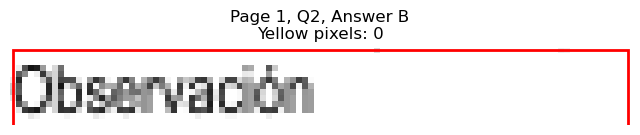

Page 1, Q2 - C: Detected box: x0=68.8, y0=202.9, x1=239.3, y1=215.6
Page 1, Q2, C: Yellow pixels: 0
Page 1, Q2, C: Total non-white pixels: 875
Page 1, Q2, C: Yellow percentage: 0.0%


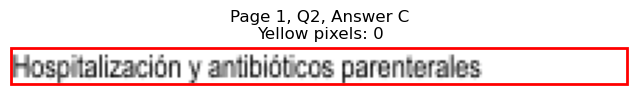

Page 1, Q2 - D: Detected box: x0=327.5, y0=177.7, x1=391.3, y1=190.4
Page 1, Q2, D: Yellow pixels: 115
Page 1, Q2, D: Total non-white pixels: 443
Page 1, Q2, D: Yellow percentage: 26.0%


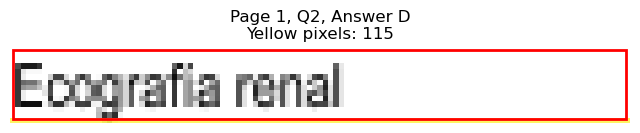

Page 1, Q2 - E: Detected box: x0=327.0, y0=190.3, x1=436.4, y1=203.0
Page 1, Q2, E: Yellow pixels: 1660
Page 1, Q2, E: Total non-white pixels: 2080
Page 1, Q2, E: Yellow percentage: 79.8%


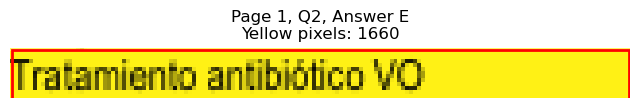


Page 1, Q2 - Selected Answer: E (based on yellow pixel count)




Page 1, Q3 - A: Detected box: x0=68.3, y0=240.9, x1=154.1, y1=253.5
Page 1, Q3, A: Yellow pixels: 137
Page 1, Q3, A: Total non-white pixels: 586
Page 1, Q3, A: Yellow percentage: 23.4%


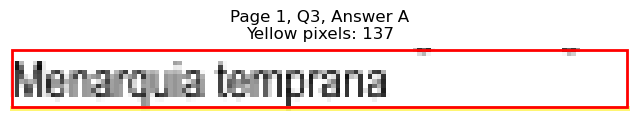

Page 1, Q3 - B: Detected box: x0=68.3, y0=253.5, x1=109.5, y1=266.1
Page 1, Q3, B: Yellow pixels: 1013
Page 1, Q3, B: Total non-white pixels: 1288
Page 1, Q3, B: Yellow percentage: 78.6%


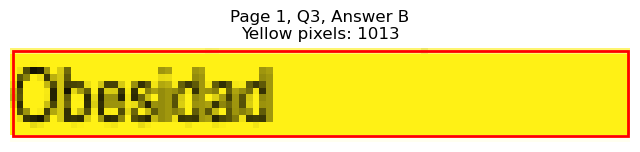

Page 1, Q3 - C: Detected box: x0=68.8, y0=266.1, x1=146.1, y1=278.7
Page 1, Q3, C: Yellow pixels: 0
Page 1, Q3, C: Total non-white pixels: 533
Page 1, Q3, C: Yellow percentage: 0.0%


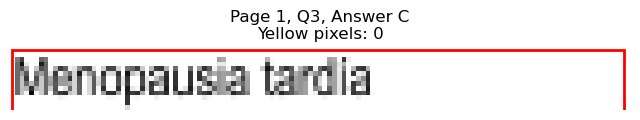

Page 1, Q3 - D: Detected box: x0=327.5, y0=240.9, x1=375.7, y1=253.5
Page 1, Q3, D: Yellow pixels: 0
Page 1, Q3, D: Total non-white pixels: 273
Page 1, Q3, D: Yellow percentage: 0.0%


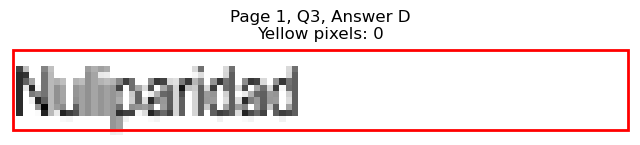

Page 1, Q3 - E: Detected box: x0=327.0, y0=253.5, x1=436.4, y1=266.1
Page 1, Q3, E: Yellow pixels: 0
Page 1, Q3, E: Total non-white pixels: 595
Page 1, Q3, E: Yellow percentage: 0.0%


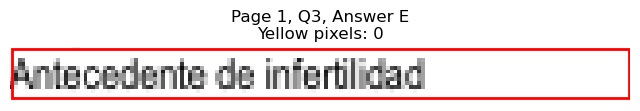


Page 1, Q3 - Selected Answer: B (based on yellow pixel count)




Page 1, Q4 - A: Detected box: x0=68.3, y0=329.2, x1=143.1, y1=341.9
Page 1, Q4, A: Yellow pixels: 0
Page 1, Q4, A: Total non-white pixels: 362
Page 1, Q4, A: Yellow percentage: 0.0%


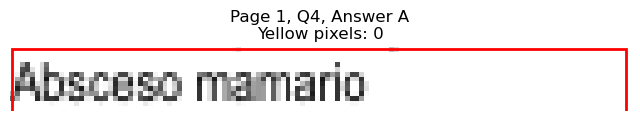

Page 1, Q4 - B: Detected box: x0=68.3, y0=341.9, x1=186.1, y1=354.6
Page 1, Q4, B: Yellow pixels: 0
Page 1, Q4, B: Total non-white pixels: 608
Page 1, Q4, B: Yellow percentage: 0.0%


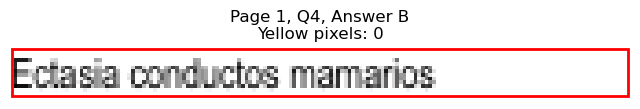

Page 1, Q4 - C: Detected box: x0=68.8, y0=354.5, x1=114.9, y1=367.2
Page 1, Q4, C: Yellow pixels: 0
Page 1, Q4, C: Total non-white pixels: 226
Page 1, Q4, C: Yellow percentage: 0.0%


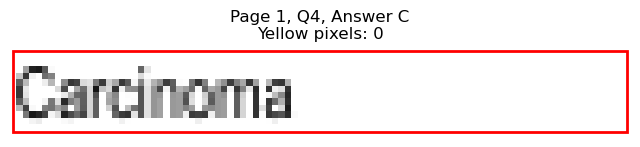

Page 1, Q4 - D: Detected box: x0=327.5, y0=329.2, x1=390.2, y1=341.9
Page 1, Q4, D: Yellow pixels: 0
Page 1, Q4, D: Total non-white pixels: 320
Page 1, Q4, D: Yellow percentage: 0.0%


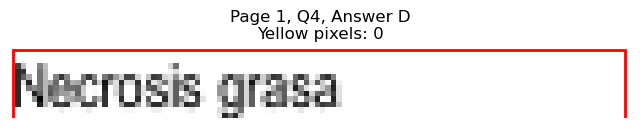

Page 1, Q4 - E: Detected box: x0=327.0, y0=341.9, x1=387.9, y1=354.6
Page 1, Q4, E: Yellow pixels: 1221
Page 1, Q4, E: Total non-white pixels: 1554
Page 1, Q4, E: Yellow percentage: 78.6%


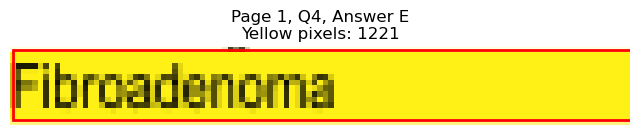


Page 1, Q4 - Selected Answer: E (based on yellow pixel count)




Page 1, Q5 - A: Detected box: x0=68.3, y0=430.2, x1=157.6, y1=442.9
Page 1, Q5, A: Yellow pixels: 1449
Page 1, Q5, A: Total non-white pixels: 1820
Page 1, Q5, A: Yellow percentage: 79.6%


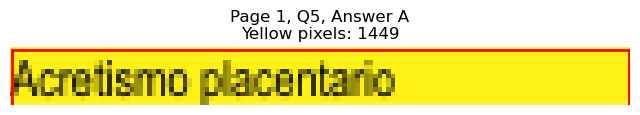

Page 1, Q5 - B: Detected box: x0=68.3, y0=442.8, x1=231.8, y1=455.5
Page 1, Q5, B: Yellow pixels: 211
Page 1, Q5, B: Total non-white pixels: 1043
Page 1, Q5, B: Yellow percentage: 20.2%


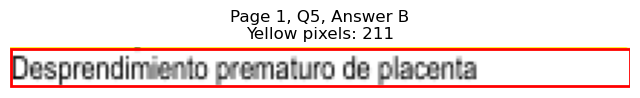

Page 1, Q5 - C: Detected box: x0=68.8, y0=455.5, x1=152.5, y1=468.1
Page 1, Q5, C: Yellow pixels: 0
Page 1, Q5, C: Total non-white pixels: 424
Page 1, Q5, C: Yellow percentage: 0.0%


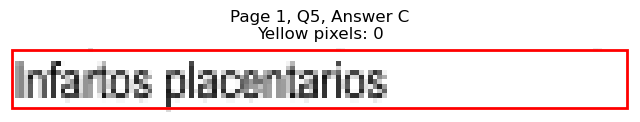

Page 1, Q5 - D: Detected box: x0=327.5, y0=430.2, x1=377.7, y1=442.9
Page 1, Q5, D: Yellow pixels: 0
Page 1, Q5, D: Total non-white pixels: 244
Page 1, Q5, D: Yellow percentage: 0.0%


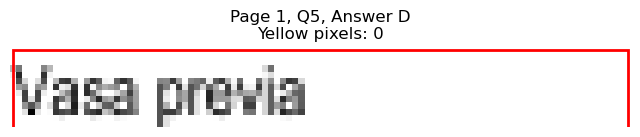

Page 1, Q5 - E: Detected box: x0=327.0, y0=442.8, x1=429.4, y1=455.5
Page 1, Q5, E: Yellow pixels: 0
Page 1, Q5, E: Total non-white pixels: 531
Page 1, Q5, E: Yellow percentage: 0.0%


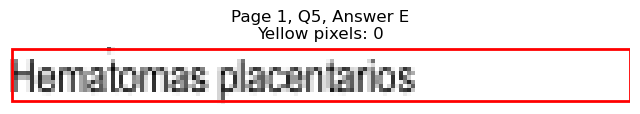


Page 1, Q5 - Selected Answer: A (based on yellow pixel count)




Page 1, Q6 - A: Detected box: x0=68.3, y0=493.4, x1=101.4, y1=506.0
Page 1, Q6, A: Yellow pixels: 0
Page 1, Q6, A: Total non-white pixels: 169
Page 1, Q6, A: Yellow percentage: 0.0%


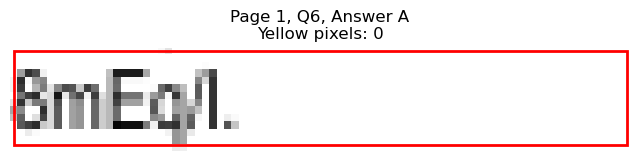

Page 1, Q6 - B: Detected box: x0=68.3, y0=506.0, x1=106.5, y1=518.6
Page 1, Q6, B: Yellow pixels: 89
Page 1, Q6, B: Total non-white pixels: 278
Page 1, Q6, B: Yellow percentage: 32.0%


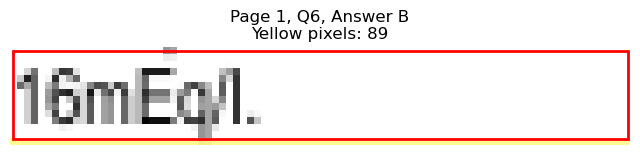

Page 1, Q6 - C: Detected box: x0=68.8, y0=518.6, x1=109.5, y1=531.2
Page 1, Q6, C: Yellow pixels: 1058
Page 1, Q6, C: Total non-white pixels: 1288
Page 1, Q6, C: Yellow percentage: 82.1%


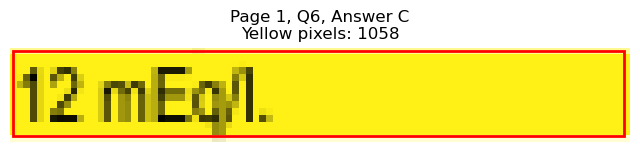

Page 1, Q6 - D: Detected box: x0=327.5, y0=493.4, x1=368.2, y1=506.0
Page 1, Q6, D: Yellow pixels: 0
Page 1, Q6, D: Total non-white pixels: 171
Page 1, Q6, D: Yellow percentage: 0.0%


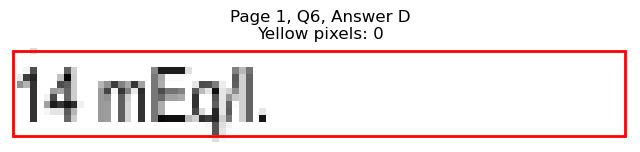

Page 1, Q6 - E: Detected box: x0=327.0, y0=506.0, x1=367.7, y1=518.6
Page 1, Q6, E: Yellow pixels: 0
Page 1, Q6, E: Total non-white pixels: 189
Page 1, Q6, E: Yellow percentage: 0.0%


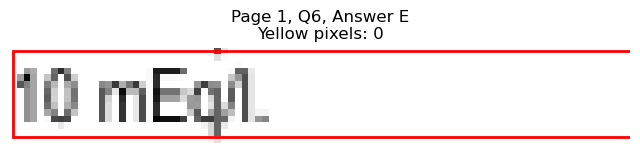


Page 1, Q6 - Selected Answer: C (based on yellow pixel count)




Page 1, Q7 - A: Detected box: x0=68.3, y0=569.1, x1=112.0, y1=581.8
Page 1, Q7, A: Yellow pixels: 1060
Page 1, Q7, A: Total non-white pixels: 1222
Page 1, Q7, A: Yellow percentage: 86.7%


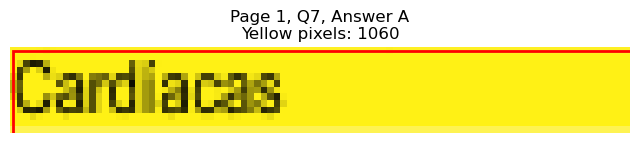

Page 1, Q7 - B: Detected box: x0=68.3, y0=581.7, x1=141.0, y1=594.4
Page 1, Q7, B: Yellow pixels: 124
Page 1, Q7, B: Total non-white pixels: 511
Page 1, Q7, B: Yellow percentage: 24.3%


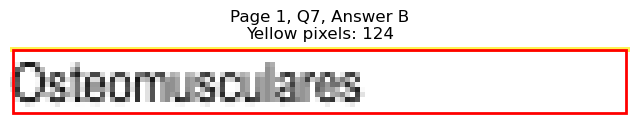

Page 1, Q7 - C: Detected box: x0=68.8, y0=594.3, x1=107.4, y1=607.0
Page 1, Q7, C: Yellow pixels: 0
Page 1, Q7, C: Total non-white pixels: 194
Page 1, Q7, C: Yellow percentage: 0.0%


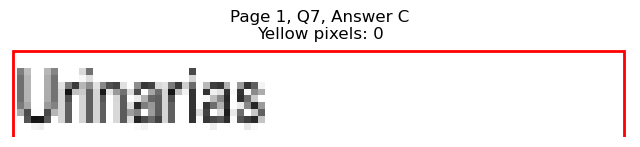

Page 1, Q7 - D: Detected box: x0=327.5, y0=569.1, x1=402.3, y1=581.8
Page 1, Q7, D: Yellow pixels: 0
Page 1, Q7, D: Total non-white pixels: 413
Page 1, Q7, D: Yellow percentage: 0.0%


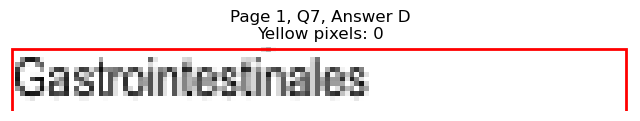

Page 1, Q7 - E: Detected box: x0=327.0, y0=581.7, x1=442.9, y1=594.4
Page 1, Q7, E: Yellow pixels: 0
Page 1, Q7, E: Total non-white pixels: 561
Page 1, Q7, E: Yellow percentage: 0.0%


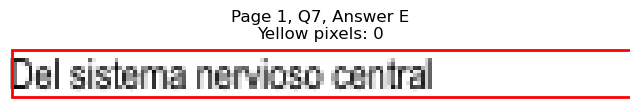


Page 1, Q7 - Selected Answer: A (based on yellow pixel count)




Page 1, Q8 - A: Detected box: x0=68.3, y0=632.2, x1=121.0, y1=644.9
Page 1, Q8, A: Yellow pixels: 1140
Page 1, Q8, A: Total non-white pixels: 1339
Page 1, Q8, A: Yellow percentage: 85.1%


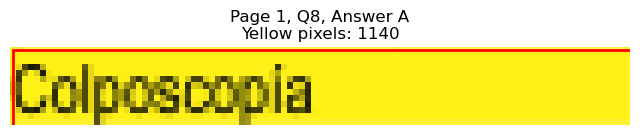

Page 1, Q8 - B: Detected box: x0=68.3, y0=644.9, x1=149.5, y1=657.5
Page 1, Q8, B: Yellow pixels: 0
Page 1, Q8, B: Total non-white pixels: 401
Page 1, Q8, B: Yellow percentage: 0.0%


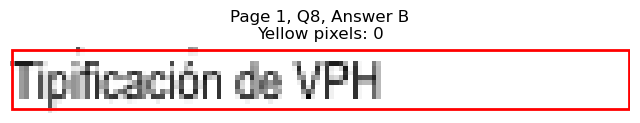

Page 1, Q8 - C: Detected box: x0=68.8, y0=657.5, x1=170.1, y1=670.1
Page 1, Q8, C: Yellow pixels: 0
Page 1, Q8, C: Total non-white pixels: 495
Page 1, Q8, C: Yellow percentage: 0.0%


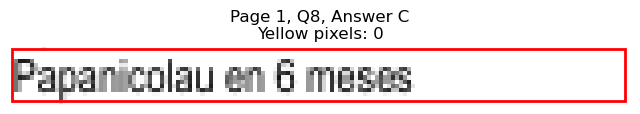

Page 1, Q8 - D: Detected box: x0=327.5, y0=632.2, x1=449.9, y1=644.9
Page 1, Q8, D: Yellow pixels: 0
Page 1, Q8, D: Total non-white pixels: 604
Page 1, Q8, D: Yellow percentage: 0.0%


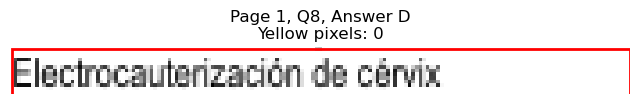

Page 1, Q8 - E: Detected box: x0=327.0, y0=644.9, x1=374.2, y1=657.5
Page 1, Q8, E: Yellow pixels: 0
Page 1, Q8, E: Total non-white pixels: 223
Page 1, Q8, E: Yellow percentage: 0.0%


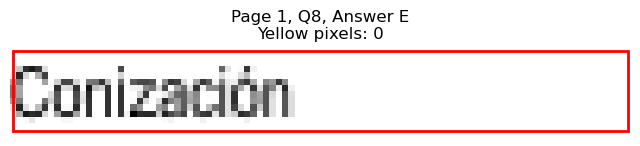


Page 1, Q8 - Selected Answer: A (based on yellow pixel count)




Page 1, Q9 - A: Detected box: x0=68.3, y0=720.6, x1=210.3, y1=733.2
Page 1, Q9, A: Yellow pixels: 1931
Page 1, Q9, A: Total non-white pixels: 2702
Page 1, Q9, A: Yellow percentage: 71.5%


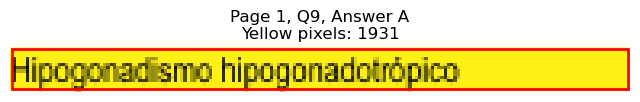

Page 1, Q9 - B: Detected box: x0=68.3, y0=733.2, x1=197.2, y1=745.8
Page 1, Q9, B: Yellow pixels: 0
Page 1, Q9, B: Total non-white pixels: 824
Page 1, Q9, B: Yellow percentage: 0.0%


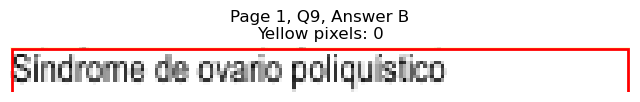

Page 1, Q9 - C: Detected box: x0=68.8, y0=745.8, x1=148.0, y1=758.4
Page 1, Q9, C: Yellow pixels: 0
Page 1, Q9, C: Total non-white pixels: 397
Page 1, Q9, C: Yellow percentage: 0.0%


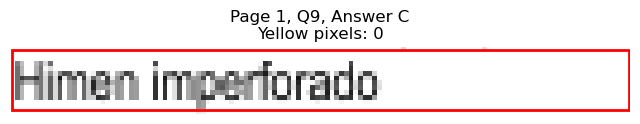

Page 1, Q9 - D: Detected box: x0=327.5, y0=720.6, x1=409.3, y1=733.2
Page 1, Q9, D: Yellow pixels: 0
Page 1, Q9, D: Total non-white pixels: 445
Page 1, Q9, D: Yellow percentage: 0.0%


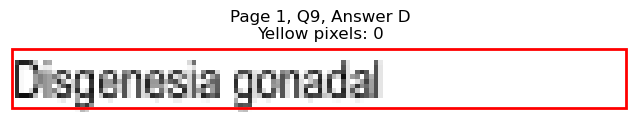

Page 1, Q9 - E: Detected box: x0=327.0, y0=733.2, x1=424.4, y1=745.8
Page 1, Q9, E: Yellow pixels: 0
Page 1, Q9, E: Total non-white pixels: 473
Page 1, Q9, E: Yellow percentage: 0.0%


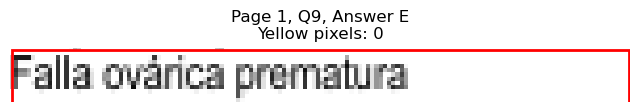


Page 1, Q9 - Selected Answer: A (based on yellow pixel count)





Page 2: Found 8 questions
Page 2, Q1 - A: Detected box: x0=68.3, y0=102.0, x1=81.9, y1=114.7
Page 2, Q1, A: Yellow pixels: 0
Page 2, Q1, A: Total non-white pixels: 58
Page 2, Q1, A: Yellow percentage: 0.0%


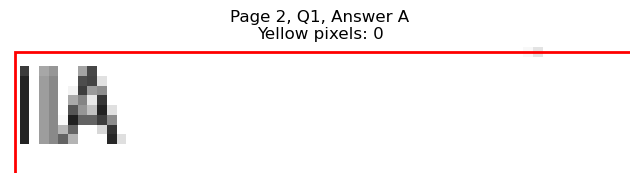

Page 2, Q1 - B: Detected box: x0=68.3, y0=114.6, x1=81.9, y1=127.3
Page 2, Q1, B: Yellow pixels: 0
Page 2, Q1, B: Total non-white pixels: 65
Page 2, Q1, B: Yellow percentage: 0.0%


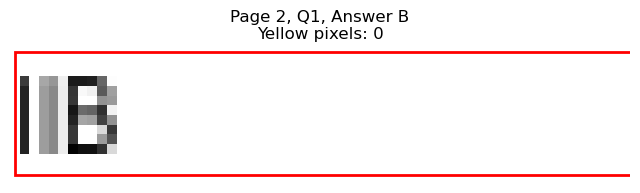

Page 2, Q1 - C: Detected box: x0=68.8, y0=127.2, x1=85.8, y1=139.9
Page 2, Q1, C: Yellow pixels: 0
Page 2, Q1, C: Total non-white pixels: 84
Page 2, Q1, C: Yellow percentage: 0.0%


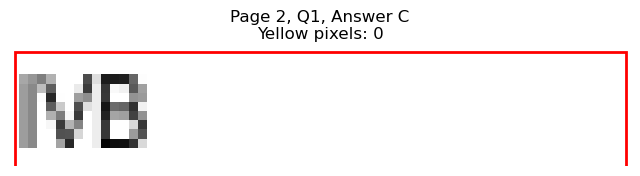

Page 2, Q1 - D: Detected box: x0=327.5, y0=102.0, x1=343.6, y1=114.7
Page 2, Q1, D: Yellow pixels: 796
Page 2, Q1, D: Total non-white pixels: 871
Page 2, Q1, D: Yellow percentage: 91.4%


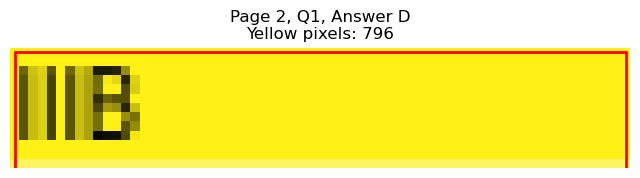

Page 2, Q1 - E: Detected box: x0=327.0, y0=114.6, x1=344.1, y1=127.3
Page 2, Q1, E: Yellow pixels: 68
Page 2, Q1, E: Total non-white pixels: 144
Page 2, Q1, E: Yellow percentage: 47.2%


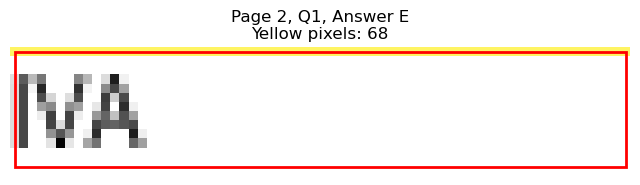


Page 2, Q1 - Selected Answer: D (based on yellow pixel count)




Page 2, Q2 - A: Detected box: x0=68.3, y0=177.7, x1=121.5, y1=190.4
Page 2, Q2, A: Yellow pixels: 1029
Page 2, Q2, A: Total non-white pixels: 1456
Page 2, Q2, A: Yellow percentage: 70.7%


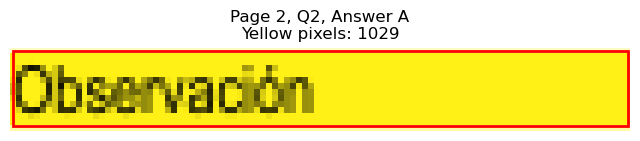

Page 2, Q2 - B: Detected box: x0=68.3, y0=190.3, x1=154.1, y1=203.0
Page 2, Q2, B: Yellow pixels: 0
Page 2, Q2, B: Total non-white pixels: 563
Page 2, Q2, B: Yellow percentage: 0.0%


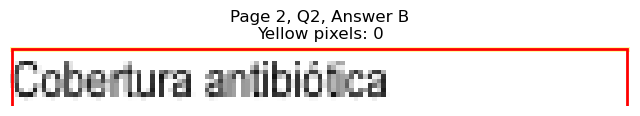

Page 2, Q2 - C: Detected box: x0=68.8, y0=202.9, x1=163.6, y1=215.6
Page 2, Q2, C: Yellow pixels: 0
Page 2, Q2, C: Total non-white pixels: 507
Page 2, Q2, C: Yellow percentage: 0.0%


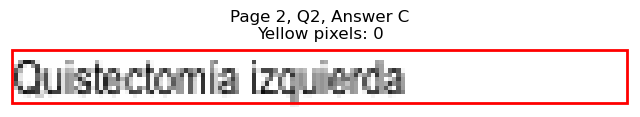

Page 2, Q2 - D: Detected box: x0=327.5, y0=177.7, x1=452.0, y1=190.4
Page 2, Q2, D: Yellow pixels: 0
Page 2, Q2, D: Total non-white pixels: 650
Page 2, Q2, D: Yellow percentage: 0.0%


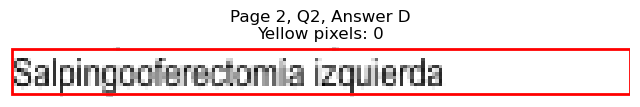

Page 2, Q2 - E: Detected box: x0=327.0, y0=190.3, x1=446.0, y1=203.0
Page 2, Q2, E: Yellow pixels: 0
Page 2, Q2, E: Total non-white pixels: 575
Page 2, Q2, E: Yellow percentage: 0.0%


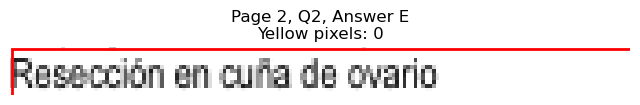


Page 2, Q2 - Selected Answer: A (based on yellow pixel count)




Page 2, Q3 - A: Detected box: x0=68.3, y0=266.1, x1=163.6, y1=278.7
Page 2, Q3, A: Yellow pixels: 1555
Page 2, Q3, A: Total non-white pixels: 1898
Page 2, Q3, A: Yellow percentage: 81.9%


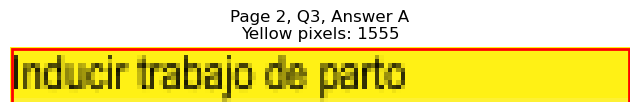

Page 2, Q3 - B: Detected box: x0=68.3, y0=278.8, x1=222.3, y1=291.5
Page 2, Q3, B: Yellow pixels: 204
Page 2, Q3, B: Total non-white pixels: 961
Page 2, Q3, B: Yellow percentage: 21.2%


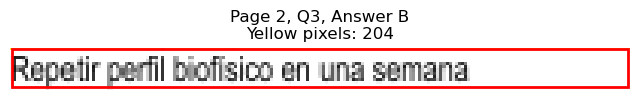

Page 2, Q3 - C: Detected box: x0=68.8, y0=291.4, x1=178.6, y1=304.1
Page 2, Q3, C: Yellow pixels: 0
Page 2, Q3, C: Total non-white pixels: 593
Page 2, Q3, C: Yellow percentage: 0.0%


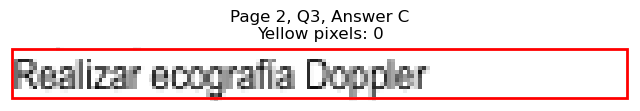

Page 2, Q3 - D: Detected box: x0=327.5, y0=266.1, x1=464.6, y1=278.7
Page 2, Q3, D: Yellow pixels: 0
Page 2, Q3, D: Total non-white pixels: 668
Page 2, Q3, D: Yellow percentage: 0.0%


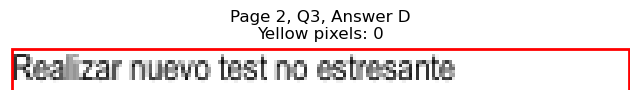

Page 2, Q3 - E: Detected box: x0=327.0, y0=278.8, x1=471.1, y1=291.5
Page 2, Q3, E: Yellow pixels: 0
Page 2, Q3, E: Total non-white pixels: 776
Page 2, Q3, E: Yellow percentage: 0.0%


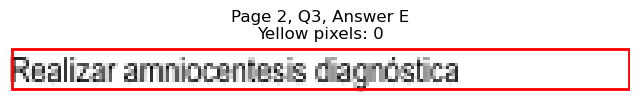


Page 2, Q3 - Selected Answer: A (based on yellow pixel count)




Page 2, Q4 - A: Detected box: x0=56.6, y0=354.5, x1=65.2, y1=367.2
Page 2, Q4, A: Yellow pixels: 0
Page 2, Q4, A: Total non-white pixels: 59
Page 2, Q4, A: Yellow percentage: 0.0%


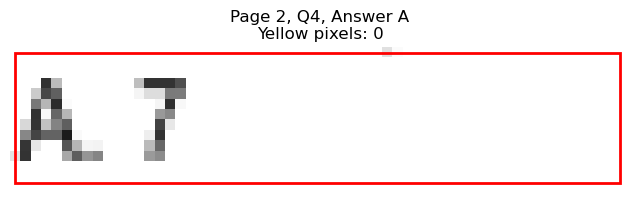

Page 2, Q4 - B: Detected box: x0=56.6, y0=367.1, x1=65.2, y1=379.8
Page 2, Q4, B: Yellow pixels: 0
Page 2, Q4, B: Total non-white pixels: 73
Page 2, Q4, B: Yellow percentage: 0.0%


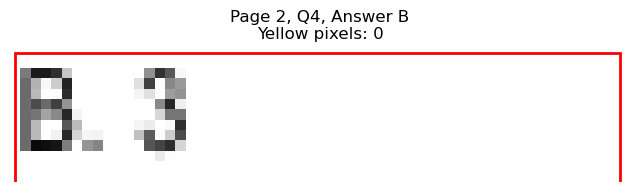

Page 2, Q4 - C: Detected box: x0=56.6, y0=379.7, x1=65.6, y1=392.4
Page 2, Q4, C: Yellow pixels: 0
Page 2, Q4, C: Total non-white pixels: 66
Page 2, Q4, C: Yellow percentage: 0.0%


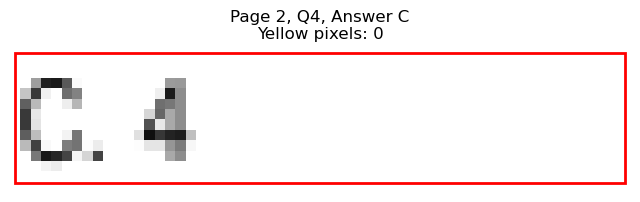

Page 2, Q4 - D: Detected box: x0=315.4, y0=354.5, x1=324.4, y1=367.2
Page 2, Q4, D: Yellow pixels: 730
Page 2, Q4, D: Total non-white pixels: 840
Page 2, Q4, D: Yellow percentage: 86.9%


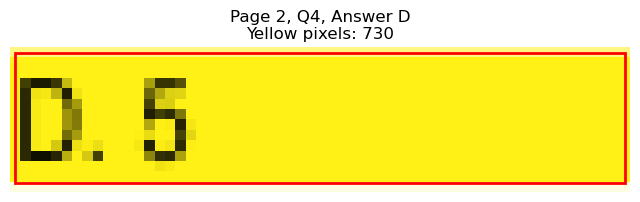

Page 2, Q4 - E: Detected box: x0=315.4, y0=367.1, x1=323.9, y1=379.8
Page 2, Q4, E: Yellow pixels: 0
Page 2, Q4, E: Total non-white pixels: 130
Page 2, Q4, E: Yellow percentage: 0.0%


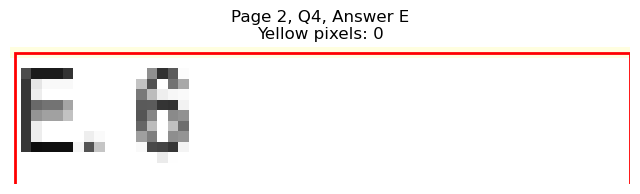


Page 2, Q4 - Selected Answer: D (based on yellow pixel count)




Page 2, Q5 - A: Detected box: x0=68.3, y0=455.5, x1=175.7, y1=468.1
Page 2, Q5, A: Yellow pixels: 0
Page 2, Q5, A: Total non-white pixels: 543
Page 2, Q5, A: Yellow percentage: 0.0%


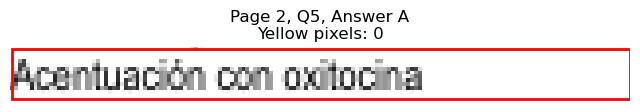

Page 2, Q5 - B: Detected box: x0=68.3, y0=468.1, x1=159.6, y1=480.7
Page 2, Q5, B: Yellow pixels: 0
Page 2, Q5, B: Total non-white pixels: 450
Page 2, Q5, B: Yellow percentage: 0.0%


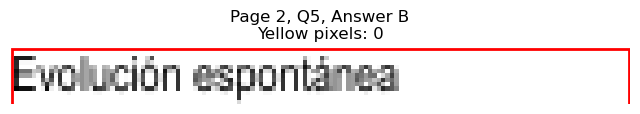

Page 2, Q5 - C: Detected box: x0=68.8, y0=480.8, x1=144.5, y1=493.4
Page 2, Q5, C: Yellow pixels: 0
Page 2, Q5, C: Total non-white pixels: 399
Page 2, Q5, C: Yellow percentage: 0.0%


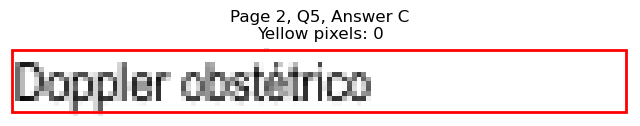

Page 2, Q5 - D: Detected box: x0=327.5, y0=455.5, x1=386.2, y1=468.1
Page 2, Q5, D: Yellow pixels: 110
Page 2, Q5, D: Total non-white pixels: 413
Page 2, Q5, D: Yellow percentage: 26.6%


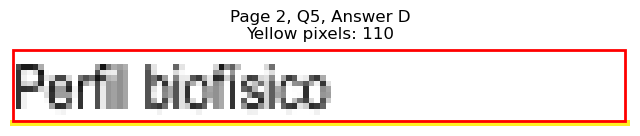

Page 2, Q5 - E: Detected box: x0=327.0, y0=468.1, x1=425.8, y1=480.7
Page 2, Q5, E: Yellow pixels: 1554
Page 2, Q5, E: Total non-white pixels: 1937
Page 2, Q5, E: Yellow percentage: 80.2%


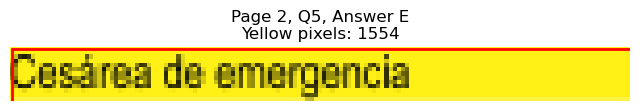


Page 2, Q5 - Selected Answer: E (based on yellow pixel count)




Page 2, Q6 - A: Detected box: x0=68.3, y0=543.8, x1=282.2, y1=556.4
Page 2, Q6, A: Yellow pixels: 0
Page 2, Q6, A: Total non-white pixels: 1173
Page 2, Q6, A: Yellow percentage: 0.0%


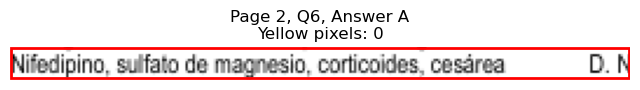

Page 2, Q6 - B: Detected box: x0=68.3, y0=569.1, x1=282.4, y1=581.8
Page 2, Q6, B: Yellow pixels: 1943
Page 2, Q6, B: Total non-white pixels: 2782
Page 2, Q6, B: Yellow percentage: 69.8%


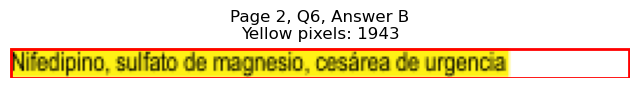

Page 2, Q6 - C: Detected box: x0=68.8, y0=581.7, x1=258.9, y1=594.4
Page 2, Q6, C: Yellow pixels: 210
Page 2, Q6, C: Total non-white pixels: 1175
Page 2, Q6, C: Yellow percentage: 17.9%


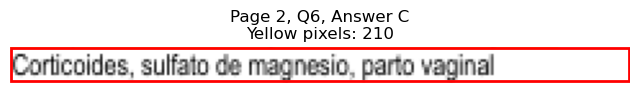

Page 2, Q6 - D: Detected box: x0=327.5, y0=543.8, x1=505.2, y1=556.4
Page 2, Q6, D: Yellow pixels: 0
Page 2, Q6, D: Total non-white pixels: 918
Page 2, Q6, D: Yellow percentage: 0.0%


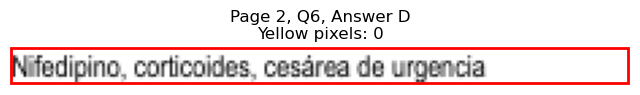

Page 2, Q6 - E: Detected box: x0=327.0, y0=556.5, x1=512.1, y1=569.2
Page 2, Q6, E: Yellow pixels: 0
Page 2, Q6, E: Total non-white pixels: 938
Page 2, Q6, E: Yellow percentage: 0.0%


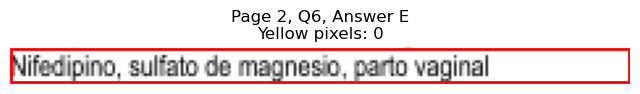


Page 2, Q6 - Selected Answer: B (based on yellow pixel count)




Page 2, Q7 - A: Detected box: x0=68.3, y0=644.9, x1=98.9, y1=657.5
Page 2, Q7, A: Yellow pixels: 0
Page 2, Q7, A: Total non-white pixels: 157
Page 2, Q7, A: Yellow percentage: 0.0%


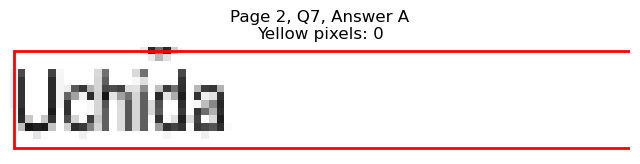

Page 2, Q7 - B: Detected box: x0=68.3, y0=657.5, x1=106.9, y1=670.1
Page 2, Q7, B: Yellow pixels: 0
Page 2, Q7, B: Total non-white pixels: 193
Page 2, Q7, B: Yellow percentage: 0.0%


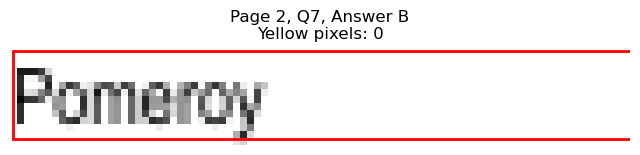

Page 2, Q7 - C: Detected box: x0=68.8, y0=670.1, x1=153.5, y1=682.7
Page 2, Q7, C: Yellow pixels: 0
Page 2, Q7, C: Total non-white pixels: 430
Page 2, Q7, C: Yellow percentage: 0.0%


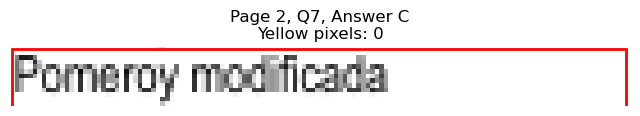

Page 2, Q7 - D: Detected box: x0=327.5, y0=644.9, x1=352.1, y1=657.5
Page 2, Q7, D: Yellow pixels: 895
Page 2, Q7, D: Total non-white pixels: 1064
Page 2, Q7, D: Yellow percentage: 84.1%


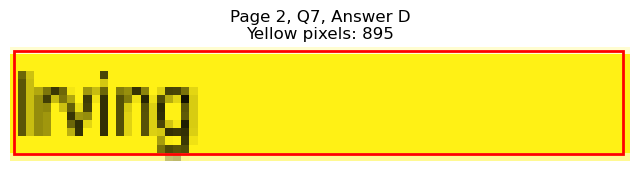

Page 2, Q7 - E: Detected box: x0=327.0, y0=657.5, x1=365.2, y1=670.1
Page 2, Q7, E: Yellow pixels: 87
Page 2, Q7, E: Total non-white pixels: 283
Page 2, Q7, E: Yellow percentage: 30.7%


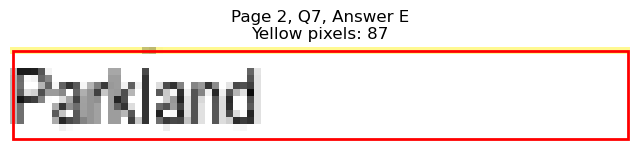


Page 2, Q7 - Selected Answer: D (based on yellow pixel count)




Page 2, Q8 - A: Detected box: x0=56.6, y0=733.2, x1=65.2, y1=745.8
Page 2, Q8, A: Yellow pixels: 0
Page 2, Q8, A: Total non-white pixels: 130
Page 2, Q8, A: Yellow percentage: 0.0%


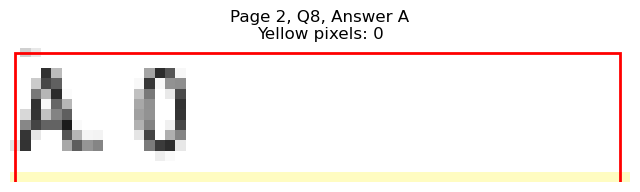

Page 2, Q8 - B: Detected box: x0=56.6, y0=745.8, x1=65.2, y1=758.4
Page 2, Q8, B: Yellow pixels: 719
Page 2, Q8, B: Total non-white pixels: 840
Page 2, Q8, B: Yellow percentage: 85.6%


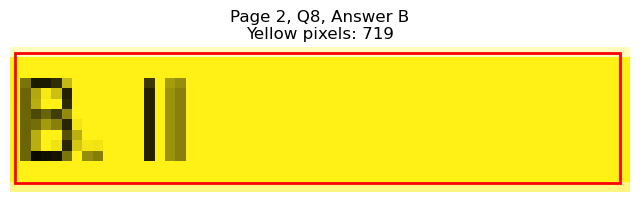

Page 2, Q8 - C: Detected box: x0=56.6, y0=758.5, x1=65.6, y1=771.2
Page 2, Q8, C: Yellow pixels: 60
Page 2, Q8, C: Total non-white pixels: 113
Page 2, Q8, C: Yellow percentage: 53.1%


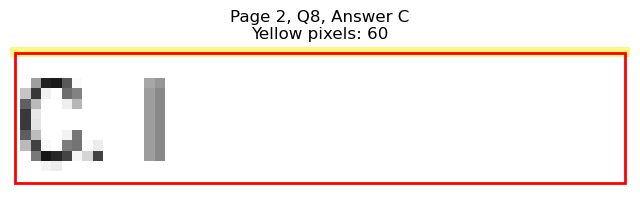

Page 2, Q8 - D: Detected box: x0=327.5, y0=733.2, x1=337.6, y1=745.8
Page 2, Q8, D: Yellow pixels: 0
Page 2, Q8, D: Total non-white pixels: 48
Page 2, Q8, D: Yellow percentage: 0.0%


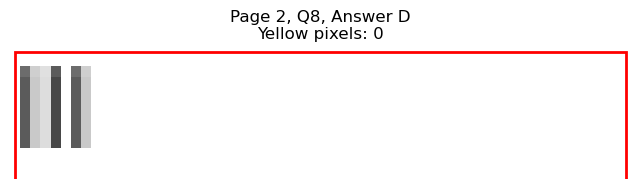

Page 2, Q8 - E: Detected box: x0=327.0, y0=745.8, x1=335.6, y1=758.4
Page 2, Q8, E: Yellow pixels: 0
Page 2, Q8, E: Total non-white pixels: 45
Page 2, Q8, E: Yellow percentage: 0.0%


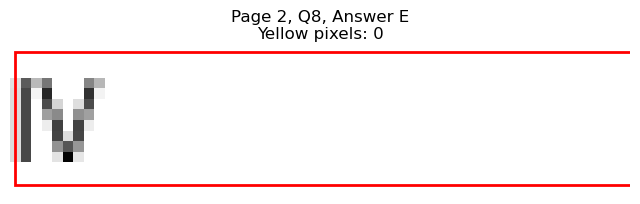


Page 2, Q8 - Selected Answer: B (based on yellow pixel count)





Page 3: Found 9 questions
Page 3, Q1 - A: Detected box: x0=68.3, y0=89.4, x1=151.1, y1=102.1
Page 3, Q1, A: Yellow pixels: 134
Page 3, Q1, A: Total non-white pixels: 545
Page 3, Q1, A: Yellow percentage: 24.6%


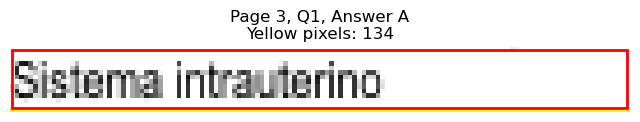

Page 3, Q1 - B: Detected box: x0=68.3, y0=102.0, x1=181.7, y1=114.7
Page 3, Q1, B: Yellow pixels: 1679
Page 3, Q1, B: Total non-white pixels: 2132
Page 3, Q1, B: Yellow percentage: 78.8%


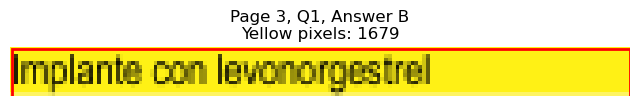

Page 3, Q1 - C: Detected box: x0=68.8, y0=114.6, x1=196.7, y1=127.3
Page 3, Q1, C: Yellow pixels: 178
Page 3, Q1, C: Total non-white pixels: 824
Page 3, Q1, C: Yellow percentage: 21.6%


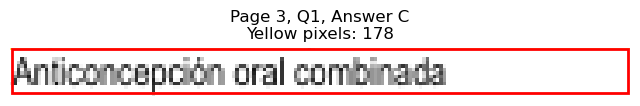

Page 3, Q1 - D: Detected box: x0=327.5, y0=89.4, x1=448.0, y1=102.1
Page 3, Q1, D: Yellow pixels: 0
Page 3, Q1, D: Total non-white pixels: 632
Page 3, Q1, D: Yellow percentage: 0.0%


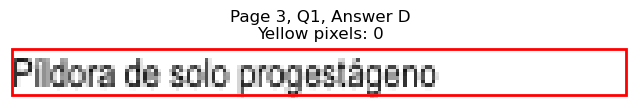

Page 3, Q1 - E: Detected box: x0=327.0, y0=102.0, x1=382.7, y1=114.7
Page 3, Q1, E: Yellow pixels: 0
Page 3, Q1, E: Total non-white pixels: 273
Page 3, Q1, E: Yellow percentage: 0.0%


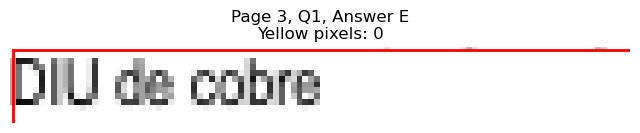


Page 3, Q1 - Selected Answer: B (based on yellow pixel count)




Page 3, Q2 - A: Detected box: x0=56.6, y0=152.5, x1=65.2, y1=165.2
Page 3, Q2, A: Yellow pixels: 0
Page 3, Q2, A: Total non-white pixels: 60
Page 3, Q2, A: Yellow percentage: 0.0%


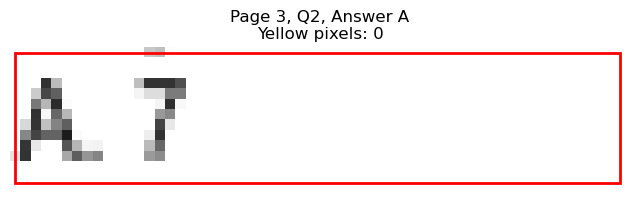

Page 3, Q2 - B: Detected box: x0=56.6, y0=165.1, x1=65.2, y1=177.8
Page 3, Q2, B: Yellow pixels: 0
Page 3, Q2, B: Total non-white pixels: 78
Page 3, Q2, B: Yellow percentage: 0.0%


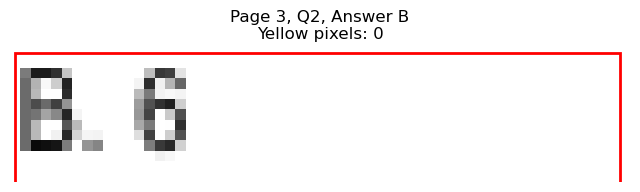

Page 3, Q2 - C: Detected box: x0=56.6, y0=177.7, x1=65.6, y1=190.4
Page 3, Q2, C: Yellow pixels: 0
Page 3, Q2, C: Total non-white pixels: 56
Page 3, Q2, C: Yellow percentage: 0.0%


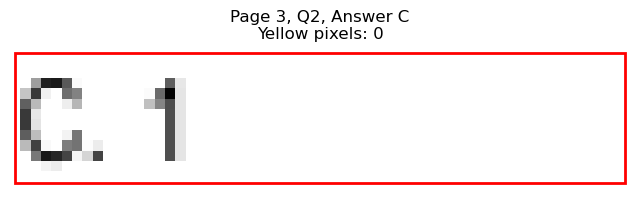

Page 3, Q2 - D: Detected box: x0=315.4, y0=152.5, x1=324.4, y1=165.2
Page 3, Q2, D: Yellow pixels: 60
Page 3, Q2, D: Total non-white pixels: 132
Page 3, Q2, D: Yellow percentage: 45.5%


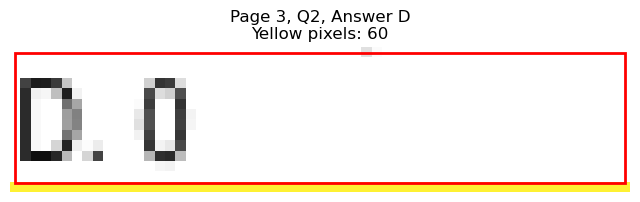

Page 3, Q2 - E: Detected box: x0=315.4, y0=165.1, x1=323.9, y1=177.8
Page 3, Q2, E: Yellow pixels: 711
Page 3, Q2, E: Total non-white pixels: 767
Page 3, Q2, E: Yellow percentage: 92.7%


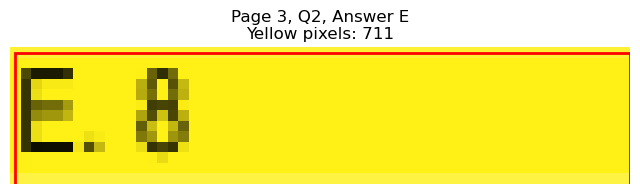


Page 3, Q2 - Selected Answer: E (based on yellow pixel count)




Page 3, Q3 - A: Detected box: x0=68.3, y0=240.9, x1=212.8, y1=253.5
Page 3, Q3, A: Yellow pixels: 0
Page 3, Q3, A: Total non-white pixels: 722
Page 3, Q3, A: Yellow percentage: 0.0%


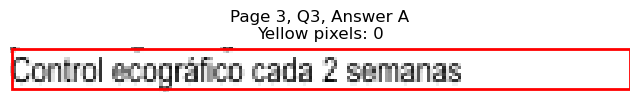

Page 3, Q3 - B: Detected box: x0=68.3, y0=253.5, x1=195.7, y1=266.1
Page 3, Q3, B: Yellow pixels: 0
Page 3, Q3, B: Total non-white pixels: 615
Page 3, Q3, B: Yellow percentage: 0.0%


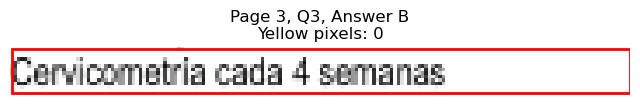

Page 3, Q3 - C: Detected box: x0=68.8, y0=266.1, x1=210.6, y1=278.7
Page 3, Q3, C: Yellow pixels: 0
Page 3, Q3, C: Total non-white pixels: 708
Page 3, Q3, C: Yellow percentage: 0.0%


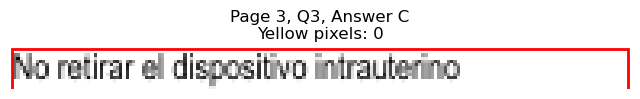

Page 3, Q3 - D: Detected box: x0=327.5, y0=240.9, x1=501.0, y1=253.5
Page 3, Q3, D: Yellow pixels: 213
Page 3, Q3, D: Total non-white pixels: 1064
Page 3, Q3, D: Yellow percentage: 20.0%


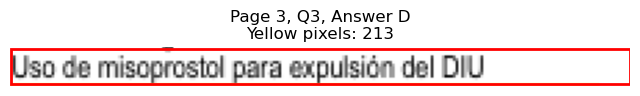

Page 3, Q3 - E: Detected box: x0=327.0, y0=253.5, x1=484.5, y1=266.1
Page 3, Q3, E: Yellow pixels: 2119
Page 3, Q3, E: Total non-white pixels: 2912
Page 3, Q3, E: Yellow percentage: 72.8%


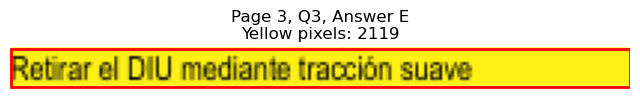


Page 3, Q3 - Selected Answer: E (based on yellow pixel count)




Page 3, Q4 - A: Detected box: x0=68.3, y0=316.6, x1=100.5, y1=329.3
Page 3, Q4, A: Yellow pixels: 0
Page 3, Q4, A: Total non-white pixels: 142
Page 3, Q4, A: Yellow percentage: 0.0%


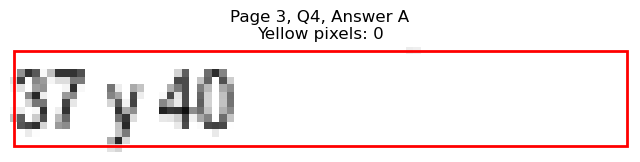

Page 3, Q4 - B: Detected box: x0=68.3, y0=329.2, x1=95.4, y1=341.9
Page 3, Q4, B: Yellow pixels: 0
Page 3, Q4, B: Total non-white pixels: 99
Page 3, Q4, B: Yellow percentage: 0.0%


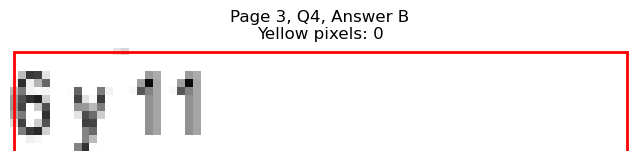

Page 3, Q4 - C: Detected box: x0=68.8, y0=341.9, x1=100.9, y1=354.6
Page 3, Q4, C: Yellow pixels: 0
Page 3, Q4, C: Total non-white pixels: 132
Page 3, Q4, C: Yellow percentage: 0.0%


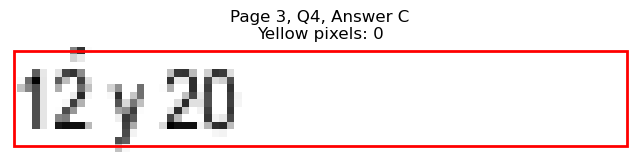

Page 3, Q4 - D: Detected box: x0=327.5, y0=316.6, x1=360.2, y1=329.3
Page 3, Q4, D: Yellow pixels: 84
Page 3, Q4, D: Total non-white pixels: 209
Page 3, Q4, D: Yellow percentage: 40.2%


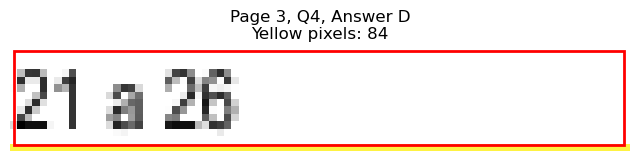

Page 3, Q4 - E: Detected box: x0=327.0, y0=329.2, x1=359.3, y1=341.9
Page 3, Q4, E: Yellow pixels: 974
Page 3, Q4, E: Total non-white pixels: 1079
Page 3, Q4, E: Yellow percentage: 90.3%


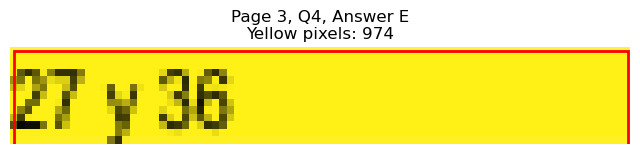


Page 3, Q4 - Selected Answer: E (based on yellow pixel count)




Page 3, Q5 - A: Detected box: x0=68.3, y0=392.3, x1=115.5, y1=405.0
Page 3, Q5, A: Yellow pixels: 0
Page 3, Q5, A: Total non-white pixels: 218
Page 3, Q5, A: Yellow percentage: 0.0%


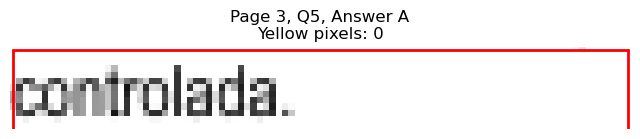

Page 3, Q5 - B: Detected box: x0=68.3, y0=404.9, x1=127.9, y1=417.6
Page 3, Q5, B: Yellow pixels: 0
Page 3, Q5, B: Total non-white pixels: 281
Page 3, Q5, B: Yellow percentage: 0.0%


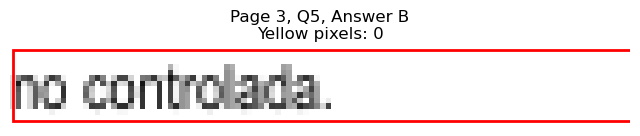

Page 3, Q5 - C: Detected box: x0=68.8, y0=417.6, x1=110.4, y1=430.3
Page 3, Q5, C: Yellow pixels: 0
Page 3, Q5, C: Total non-white pixels: 180
Page 3, Q5, C: Yellow percentage: 0.0%


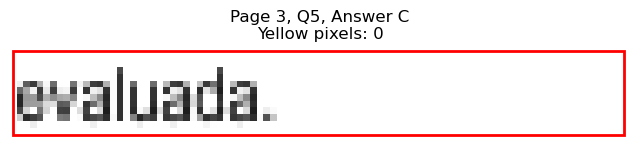

Page 3, Q5 - D: Detected box: x0=327.5, y0=392.3, x1=379.7, y1=405.0
Page 3, Q5, D: Yellow pixels: 0
Page 3, Q5, D: Total non-white pixels: 361
Page 3, Q5, D: Yellow percentage: 0.0%


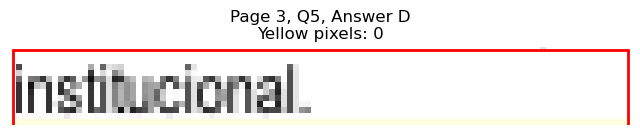

Page 3, Q5 - E: Detected box: x0=327.0, y0=404.9, x1=366.7, y1=417.6
Page 3, Q5, E: Yellow pixels: 1031
Page 3, Q5, E: Total non-white pixels: 1260
Page 3, Q5, E: Yellow percentage: 81.8%


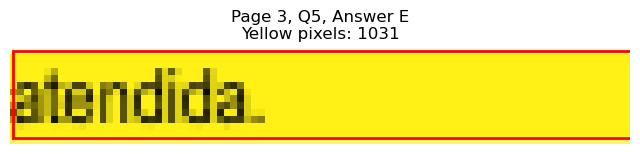


Page 3, Q5 - Selected Answer: E (based on yellow pixel count)




Page 3, Q6 - A: Detected box: x0=68.3, y0=468.1, x1=281.9, y1=480.7
Page 3, Q6, A: Yellow pixels: 0
Page 3, Q6, A: Total non-white pixels: 1136
Page 3, Q6, A: Yellow percentage: 0.0%


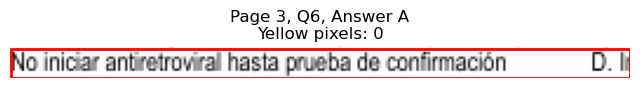

Page 3, Q6 - B: Detected box: x0=68.3, y0=480.8, x1=238.4, y1=493.4
Page 3, Q6, B: Yellow pixels: 213
Page 3, Q6, B: Total non-white pixels: 1039
Page 3, Q6, B: Yellow percentage: 20.5%


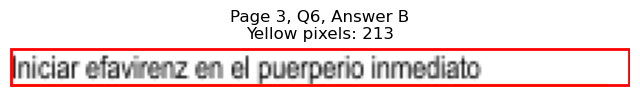

Page 3, Q6 - C: Detected box: x0=68.8, y0=493.4, x1=190.1, y1=506.0
Page 3, Q6, C: Yellow pixels: 1765
Page 3, Q6, C: Total non-white pixels: 2249
Page 3, Q6, C: Yellow percentage: 78.5%


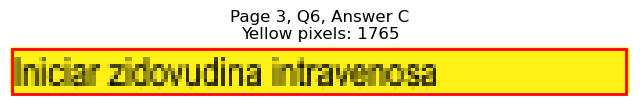

Page 3, Q6 - D: Detected box: x0=327.5, y0=468.1, x1=502.7, y1=480.7
Page 3, Q6, D: Yellow pixels: 0
Page 3, Q6, D: Total non-white pixels: 851
Page 3, Q6, D: Yellow percentage: 0.0%


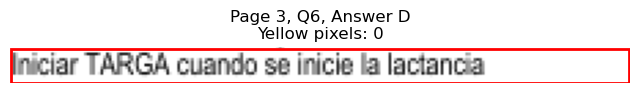

Page 3, Q6 - E: Detected box: x0=327.0, y0=480.8, x1=476.6, y1=493.4
Page 3, Q6, E: Yellow pixels: 0
Page 3, Q6, E: Total non-white pixels: 775
Page 3, Q6, E: Yellow percentage: 0.0%


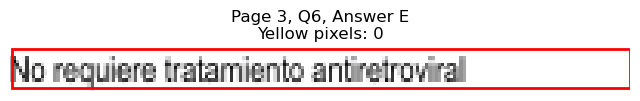


Page 3, Q6 - Selected Answer: C (based on yellow pixel count)




Page 3, Q7 - A: Detected box: x0=68.3, y0=556.5, x1=169.1, y1=569.2
Page 3, Q7, A: Yellow pixels: 0
Page 3, Q7, A: Total non-white pixels: 473
Page 3, Q7, A: Yellow percentage: 0.0%


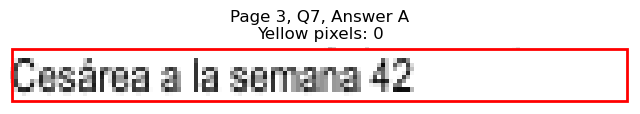

Page 3, Q7 - B: Detected box: x0=68.3, y0=569.1, x1=211.2, y1=581.8
Page 3, Q7, B: Yellow pixels: 0
Page 3, Q7, B: Total non-white pixels: 677
Page 3, Q7, B: Yellow percentage: 0.0%


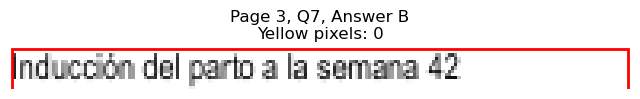

Page 3, Q7 - C: Detected box: x0=68.8, y0=581.7, x1=210.6, y1=594.4
Page 3, Q7, C: Yellow pixels: 0
Page 3, Q7, C: Total non-white pixels: 703
Page 3, Q7, C: Yellow percentage: 0.0%


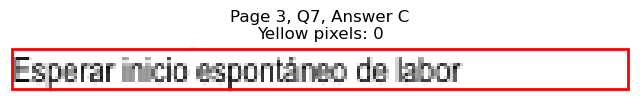

Page 3, Q7 - D: Detected box: x0=327.5, y0=556.5, x1=397.3, y1=569.2
Page 3, Q7, D: Yellow pixels: 121
Page 3, Q7, D: Total non-white pixels: 478
Page 3, Q7, D: Yellow percentage: 25.3%


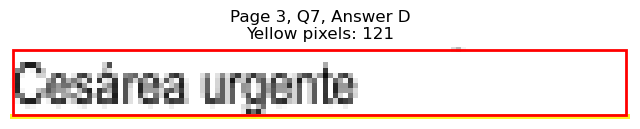

Page 3, Q7 - E: Detected box: x0=327.0, y0=569.1, x1=476.0, y1=581.8
Page 3, Q7, E: Yellow pixels: 2044
Page 3, Q7, E: Total non-white pixels: 2600
Page 3, Q7, E: Yellow percentage: 78.6%


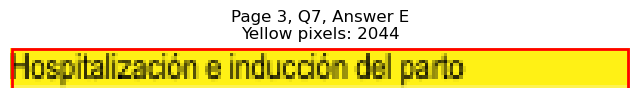


Page 3, Q7 - Selected Answer: E (based on yellow pixel count)




Page 3, Q8 - A: Detected box: x0=68.3, y0=644.9, x1=127.9, y1=657.5
Page 3, Q8, A: Yellow pixels: 110
Page 3, Q8, A: Total non-white pixels: 395
Page 3, Q8, A: Yellow percentage: 27.8%


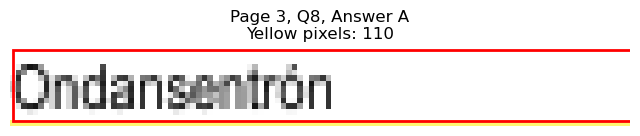

Page 3, Q8 - B: Detected box: x0=68.3, y0=657.5, x1=163.1, y1=670.1
Page 3, Q8, B: Yellow pixels: 1520
Page 3, Q8, B: Total non-white pixels: 2044
Page 3, Q8, B: Yellow percentage: 74.4%


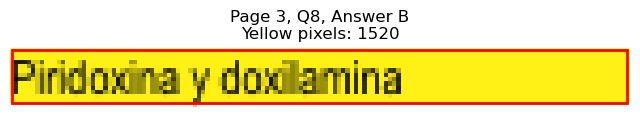

Page 3, Q8 - C: Detected box: x0=68.8, y0=670.1, x1=204.3, y1=682.7
Page 3, Q8, C: Yellow pixels: 0
Page 3, Q8, C: Total non-white pixels: 885
Page 3, Q8, C: Yellow percentage: 0.0%


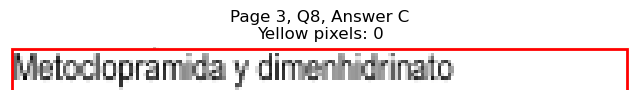

Page 3, Q8 - D: Detected box: x0=327.5, y0=644.9, x1=380.7, y1=657.5
Page 3, Q8, D: Yellow pixels: 0
Page 3, Q8, D: Total non-white pixels: 259
Page 3, Q8, D: Yellow percentage: 0.0%


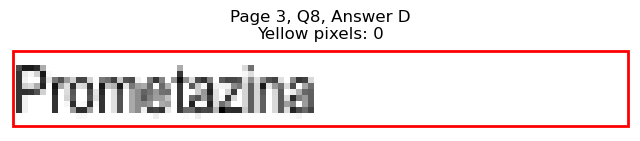

Page 3, Q8 - E: Detected box: x0=327.0, y0=657.5, x1=461.9, y1=670.1
Page 3, Q8, E: Yellow pixels: 0
Page 3, Q8, E: Total non-white pixels: 677
Page 3, Q8, E: Yellow percentage: 0.0%


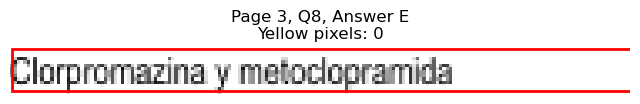


Page 3, Q8 - Selected Answer: B (based on yellow pixel count)




Page 3, Q9 - A: Detected box: x0=68.3, y0=733.2, x1=157.6, y1=745.8
Page 3, Q9, A: Yellow pixels: 0
Page 3, Q9, A: Total non-white pixels: 424
Page 3, Q9, A: Yellow percentage: 0.0%


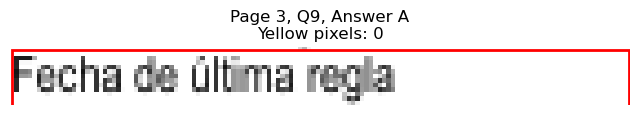

Page 3, Q9 - B: Detected box: x0=68.3, y0=745.8, x1=139.6, y1=758.4
Page 3, Q9, B: Yellow pixels: 0
Page 3, Q9, B: Total non-white pixels: 383
Page 3, Q9, B: Yellow percentage: 0.0%


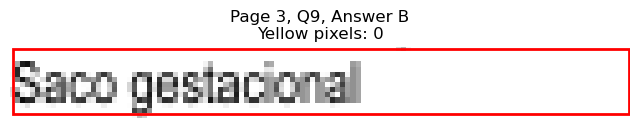

Page 3, Q9 - C: Detected box: x0=68.8, y0=758.5, x1=138.5, y1=771.2
Page 3, Q9, C: Yellow pixels: 0
Page 3, Q9, C: Total non-white pixels: 369
Page 3, Q9, C: Yellow percentage: 0.0%


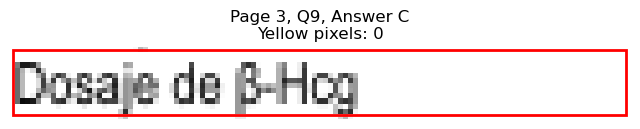

Page 3, Q9 - D: Detected box: x0=327.5, y0=733.2, x1=393.3, y1=745.8
Page 3, Q9, D: Yellow pixels: 0
Page 3, Q9, D: Total non-white pixels: 430
Page 3, Q9, D: Yellow percentage: 0.0%


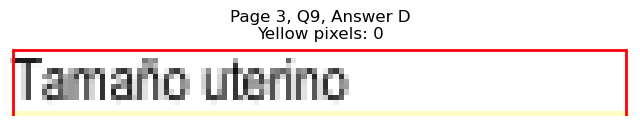

Page 3, Q9 - E: Detected box: x0=327.0, y0=745.8, x1=419.3, y1=758.4
Page 3, Q9, E: Yellow pixels: 1503
Page 3, Q9, E: Total non-white pixels: 2002
Page 3, Q9, E: Yellow percentage: 75.1%


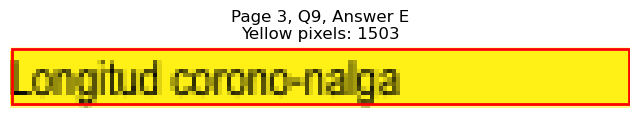


Page 3, Q9 - Selected Answer: E (based on yellow pixel count)





Page 4: Found 8 questions
Page 4, Q1 - A: Detected box: x0=68.3, y0=102.0, x1=104.4, y1=114.7
Page 4, Q1, A: Yellow pixels: 0
Page 4, Q1, A: Total non-white pixels: 182
Page 4, Q1, A: Yellow percentage: 0.0%


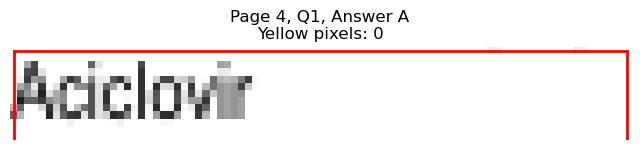

Page 4, Q1 - B: Detected box: x0=68.3, y0=114.6, x1=116.4, y1=127.3
Page 4, Q1, B: Yellow pixels: 0
Page 4, Q1, B: Total non-white pixels: 256
Page 4, Q1, B: Yellow percentage: 0.0%


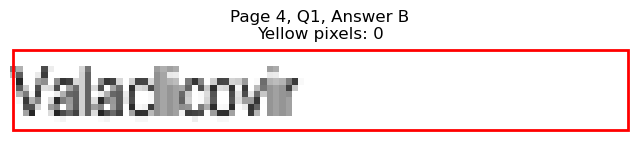

Page 4, Q1 - C: Detected box: x0=68.8, y0=127.2, x1=110.9, y1=139.9
Page 4, Q1, C: Yellow pixels: 0
Page 4, Q1, C: Total non-white pixels: 194
Page 4, Q1, C: Yellow percentage: 0.0%


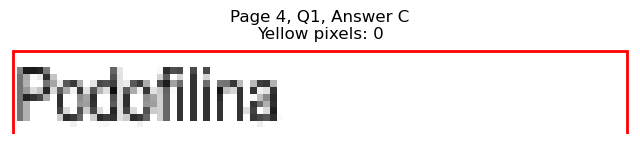

Page 4, Q1 - D: Detected box: x0=327.5, y0=102.0, x1=426.3, y1=114.7
Page 4, Q1, D: Yellow pixels: 1557
Page 4, Q1, D: Total non-white pixels: 1950
Page 4, Q1, D: Yellow percentage: 79.8%


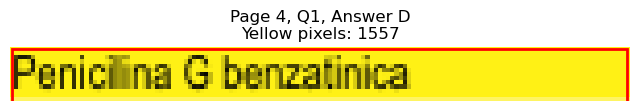

Page 4, Q1 - E: Detected box: x0=327.0, y0=114.6, x1=386.7, y1=127.3
Page 4, Q1, E: Yellow pixels: 110
Page 4, Q1, E: Total non-white pixels: 406
Page 4, Q1, E: Yellow percentage: 27.1%


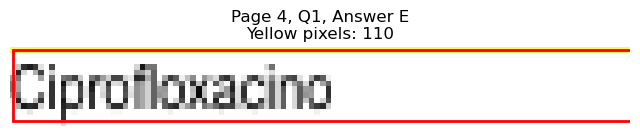


Page 4, Q1 - Selected Answer: D (based on yellow pixel count)




Page 4, Q2 - A: Detected box: x0=68.3, y0=190.3, x1=183.1, y1=203.0
Page 4, Q2, A: Yellow pixels: 0
Page 4, Q2, A: Total non-white pixels: 710
Page 4, Q2, A: Yellow percentage: 0.0%


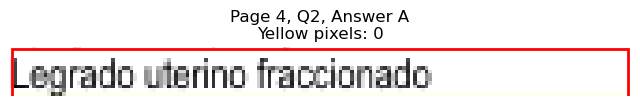

Page 4, Q2 - B: Detected box: x0=68.3, y0=202.9, x1=146.2, y1=215.6
Page 4, Q2, B: Yellow pixels: 1366
Page 4, Q2, B: Total non-white pixels: 1806
Page 4, Q2, B: Yellow percentage: 75.6%


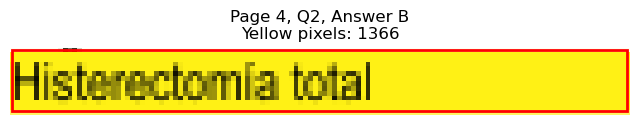

Page 4, Q2 - C: Detected box: x0=68.8, y0=215.7, x1=174.1, y1=228.3
Page 4, Q2, C: Yellow pixels: 157
Page 4, Q2, C: Total non-white pixels: 735
Page 4, Q2, C: Yellow percentage: 21.4%


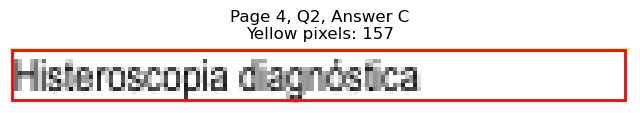

Page 4, Q2 - D: Detected box: x0=327.5, y0=190.3, x1=419.8, y1=203.0
Page 4, Q2, D: Yellow pixels: 0
Page 4, Q2, D: Total non-white pixels: 466
Page 4, Q2, D: Yellow percentage: 0.0%


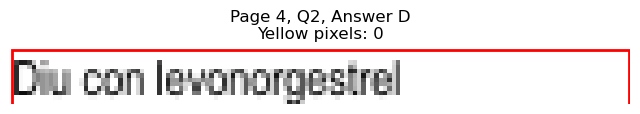

Page 4, Q2 - E: Detected box: x0=327.0, y0=202.9, x1=413.8, y1=215.6
Page 4, Q2, E: Yellow pixels: 0
Page 4, Q2, E: Total non-white pixels: 466
Page 4, Q2, E: Yellow percentage: 0.0%


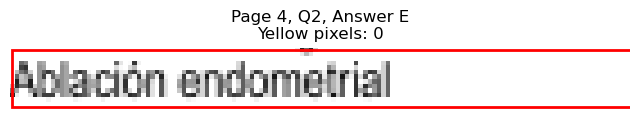


Page 4, Q2 - Selected Answer: B (based on yellow pixel count)




Page 4, Q3 - A: Detected box: x0=68.3, y0=278.8, x1=112.9, y1=291.5
Page 4, Q3, A: Yellow pixels: 0
Page 4, Q3, A: Total non-white pixels: 233
Page 4, Q3, A: Yellow percentage: 0.0%


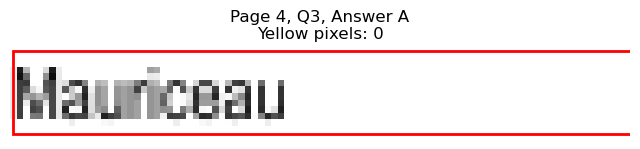

Page 4, Q3 - B: Detected box: x0=68.3, y0=291.4, x1=106.9, y1=304.1
Page 4, Q3, B: Yellow pixels: 0
Page 4, Q3, B: Total non-white pixels: 172
Page 4, Q3, B: Yellow percentage: 0.0%


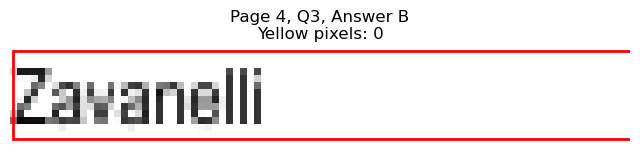

Page 4, Q3 - C: Detected box: x0=68.8, y0=304.0, x1=97.3, y1=316.7
Page 4, Q3, C: Yellow pixels: 0
Page 4, Q3, C: Total non-white pixels: 147
Page 4, Q3, C: Yellow percentage: 0.0%


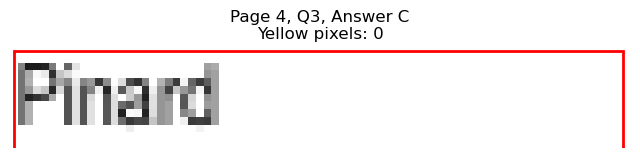

Page 4, Q3 - D: Detected box: x0=327.5, y0=278.8, x1=400.3, y1=291.5
Page 4, Q3, D: Yellow pixels: 1337
Page 4, Q3, D: Total non-white pixels: 1736
Page 4, Q3, D: Yellow percentage: 77.0%


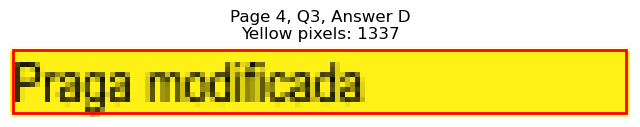

Page 4, Q3 - E: Detected box: x0=327.0, y0=291.4, x1=368.2, y1=304.1
Page 4, Q3, E: Yellow pixels: 91
Page 4, Q3, E: Total non-white pixels: 285
Page 4, Q3, E: Yellow percentage: 31.9%


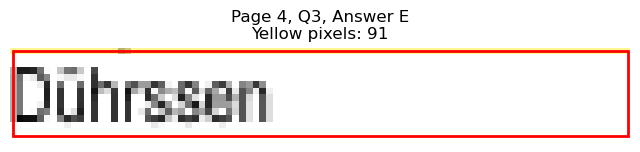


Page 4, Q3 - Selected Answer: D (based on yellow pixel count)




Page 4, Q4 - A: Detected box: x0=68.3, y0=354.5, x1=166.6, y1=367.2
Page 4, Q4, A: Yellow pixels: 0
Page 4, Q4, A: Total non-white pixels: 466
Page 4, Q4, A: Yellow percentage: 0.0%


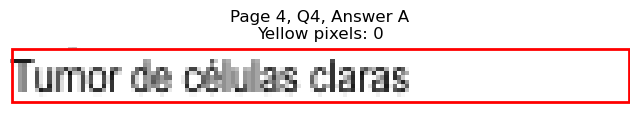

Page 4, Q4 - B: Detected box: x0=68.3, y0=367.1, x1=151.1, y1=379.8
Page 4, Q4, B: Yellow pixels: 0
Page 4, Q4, B: Total non-white pixels: 548
Page 4, Q4, B: Yellow percentage: 0.0%


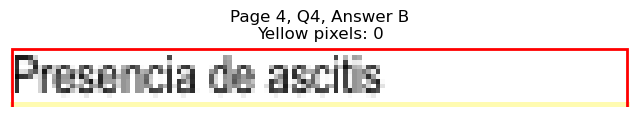

Page 4, Q4 - C: Detected box: x0=68.8, y0=379.7, x1=168.6, y1=392.4
Page 4, Q4, C: Yellow pixels: 1434
Page 4, Q4, C: Total non-white pixels: 2114
Page 4, Q4, C: Yellow percentage: 67.8%


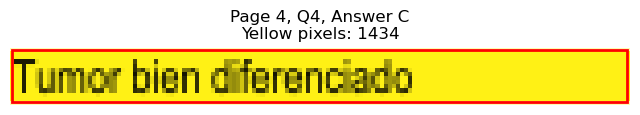

Page 4, Q4 - D: Detected box: x0=327.5, y0=354.5, x1=392.8, y1=367.2
Page 4, Q4, D: Yellow pixels: 0
Page 4, Q4, D: Total non-white pixels: 314
Page 4, Q4, D: Yellow percentage: 0.0%


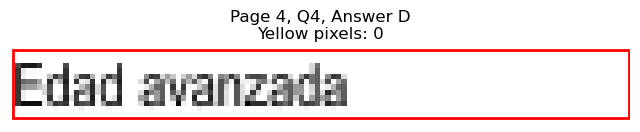

Page 4, Q4 - E: Detected box: x0=327.0, y0=367.1, x1=433.4, y1=379.8
Page 4, Q4, E: Yellow pixels: 0
Page 4, Q4, E: Total non-white pixels: 537
Page 4, Q4, E: Yellow percentage: 0.0%


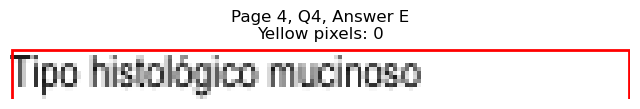


Page 4, Q4 - Selected Answer: C (based on yellow pixel count)




Page 4, Q5 - A: Detected box: x0=68.3, y0=442.8, x1=80.9, y1=455.5
Page 4, Q5, A: Yellow pixels: 779
Page 4, Q5, A: Total non-white pixels: 882
Page 4, Q5, A: Yellow percentage: 88.3%


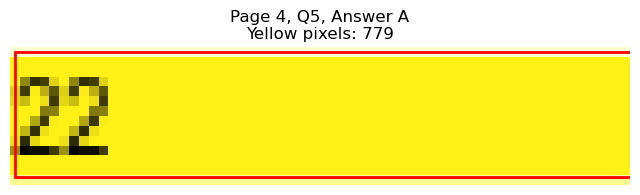

Page 4, Q5 - B: Detected box: x0=68.3, y0=455.5, x1=80.9, y1=468.1
Page 4, Q5, B: Yellow pixels: 0
Page 4, Q5, B: Total non-white pixels: 51
Page 4, Q5, B: Yellow percentage: 0.0%


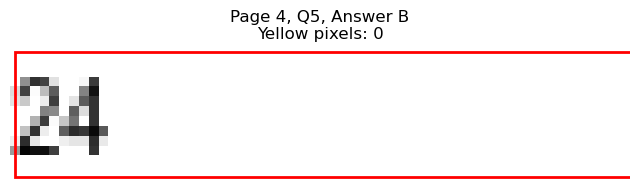

Page 4, Q5 - C: Detected box: x0=68.8, y0=468.1, x1=81.4, y1=480.7
Page 4, Q5, C: Yellow pixels: 0
Page 4, Q5, C: Total non-white pixels: 56
Page 4, Q5, C: Yellow percentage: 0.0%


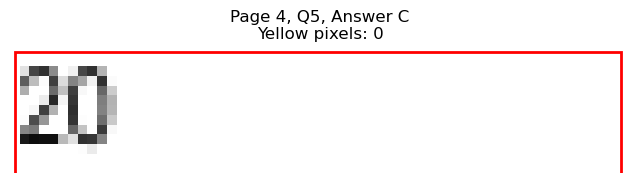

Page 4, Q5 - D: Detected box: x0=327.5, y0=442.8, x1=340.1, y1=455.5
Page 4, Q5, D: Yellow pixels: 0
Page 4, Q5, D: Total non-white pixels: 50
Page 4, Q5, D: Yellow percentage: 0.0%


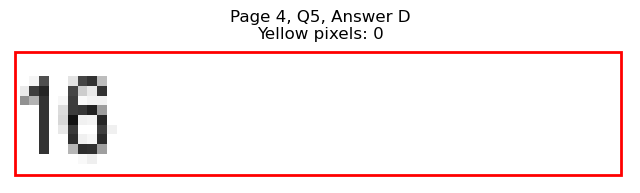

Page 4, Q5 - E: Detected box: x0=327.0, y0=455.5, x1=339.7, y1=468.1
Page 4, Q5, E: Yellow pixels: 0
Page 4, Q5, E: Total non-white pixels: 44
Page 4, Q5, E: Yellow percentage: 0.0%


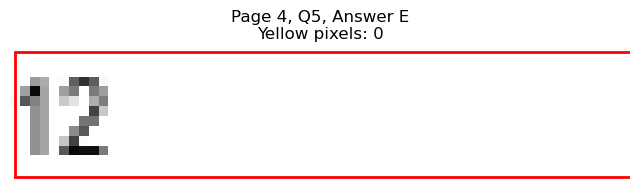


Page 4, Q5 - Selected Answer: A (based on yellow pixel count)




Page 4, Q6 - A: Detected box: x0=68.3, y0=518.6, x1=167.7, y1=531.2
Page 4, Q6, A: Yellow pixels: 1569
Page 4, Q6, A: Total non-white pixels: 2100
Page 4, Q6, A: Yellow percentage: 74.7%


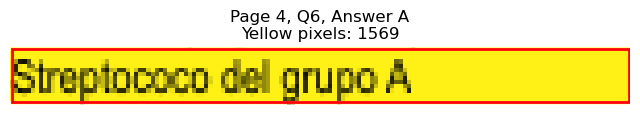

Page 4, Q6 - B: Detected box: x0=68.3, y0=531.2, x1=131.5, y1=543.8
Page 4, Q6, B: Yellow pixels: 0
Page 4, Q6, B: Total non-white pixels: 418
Page 4, Q6, B: Yellow percentage: 0.0%


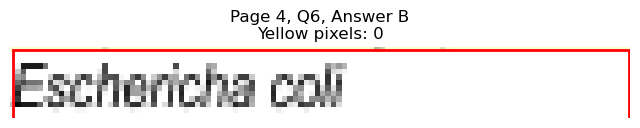

Page 4, Q6 - C: Detected box: x0=68.8, y0=543.8, x1=118.9, y1=556.4
Page 4, Q6, C: Yellow pixels: 0
Page 4, Q6, C: Total non-white pixels: 268
Page 4, Q6, C: Yellow percentage: 0.0%


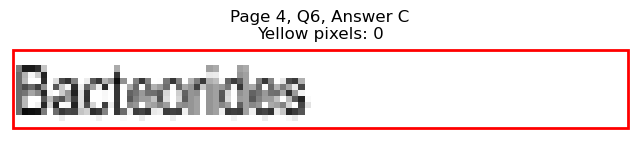

Page 4, Q6 - D: Detected box: x0=327.5, y0=518.6, x1=380.7, y1=531.2
Page 4, Q6, D: Yellow pixels: 0
Page 4, Q6, D: Total non-white pixels: 285
Page 4, Q6, D: Yellow percentage: 0.0%


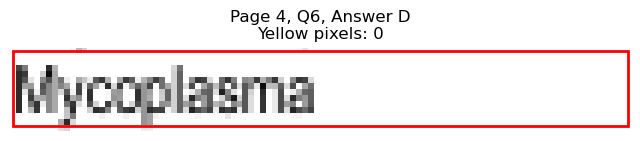

Page 4, Q6 - E: Detected box: x0=327.0, y0=531.2, x1=420.9, y1=543.8
Page 4, Q6, E: Yellow pixels: 0
Page 4, Q6, E: Total non-white pixels: 468
Page 4, Q6, E: Yellow percentage: 0.0%


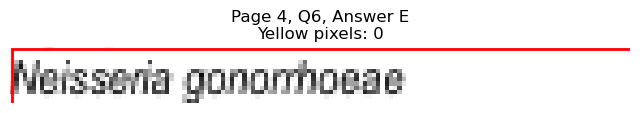


Page 4, Q6 - Selected Answer: A (based on yellow pixel count)




Page 4, Q7 - A: Detected box: x0=68.3, y0=606.9, x1=175.6, y1=619.6
Page 4, Q7, A: Yellow pixels: 0
Page 4, Q7, A: Total non-white pixels: 498
Page 4, Q7, A: Yellow percentage: 0.0%


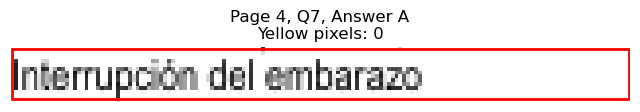

Page 4, Q7 - B: Detected box: x0=68.3, y0=619.6, x1=151.6, y1=632.3
Page 4, Q7, B: Yellow pixels: 0
Page 4, Q7, B: Total non-white pixels: 423
Page 4, Q7, B: Yellow percentage: 0.0%


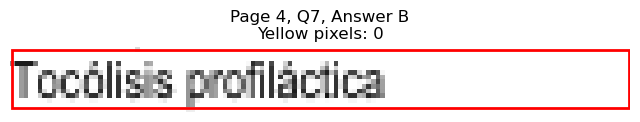

Page 4, Q7 - C: Detected box: x0=68.8, y0=632.2, x1=154.6, y1=644.9
Page 4, Q7, C: Yellow pixels: 0
Page 4, Q7, C: Total non-white pixels: 451
Page 4, Q7, C: Yellow percentage: 0.0%


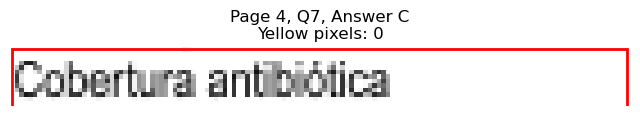

Page 4, Q7 - D: Detected box: x0=327.5, y0=606.9, x1=483.6, y1=619.6
Page 4, Q7, D: Yellow pixels: 0
Page 4, Q7, D: Total non-white pixels: 826
Page 4, Q7, D: Yellow percentage: 0.0%


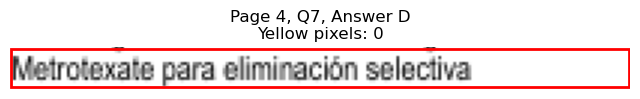

Page 4, Q7 - E: Detected box: x0=327.0, y0=619.6, x1=433.4, y1=632.3
Page 4, Q7, E: Yellow pixels: 1479
Page 4, Q7, E: Total non-white pixels: 2198
Page 4, Q7, E: Yellow percentage: 67.3%


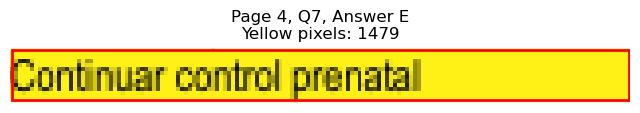


Page 4, Q7 - Selected Answer: E (based on yellow pixel count)




Page 4, Q8 - A: Detected box: x0=56.6, y0=682.7, x1=65.2, y1=695.3
Page 4, Q8, A: Yellow pixels: 0
Page 4, Q8, A: Total non-white pixels: 71
Page 4, Q8, A: Yellow percentage: 0.0%


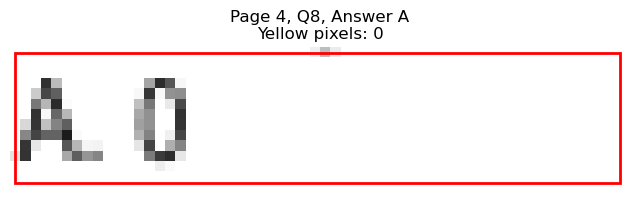

Page 4, Q8 - B: Detected box: x0=56.6, y0=695.4, x1=65.2, y1=708.0
Page 4, Q8, B: Yellow pixels: 719
Page 4, Q8, B: Total non-white pixels: 780
Page 4, Q8, B: Yellow percentage: 92.2%


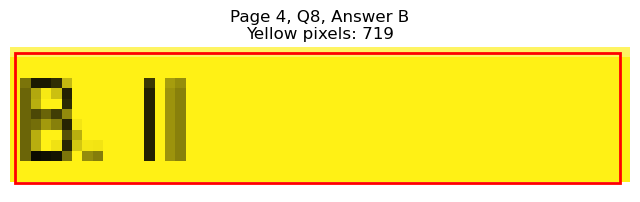

Page 4, Q8 - C: Detected box: x0=56.6, y0=708.0, x1=65.6, y1=720.6
Page 4, Q8, C: Yellow pixels: 60
Page 4, Q8, C: Total non-white pixels: 113
Page 4, Q8, C: Yellow percentage: 53.1%


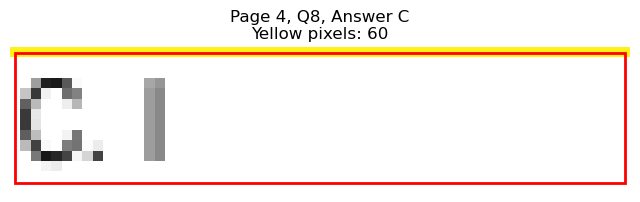

Page 4, Q8 - D: Detected box: x0=327.5, y0=682.7, x1=337.6, y1=695.3
Page 4, Q8, D: Yellow pixels: 0
Page 4, Q8, D: Total non-white pixels: 48
Page 4, Q8, D: Yellow percentage: 0.0%


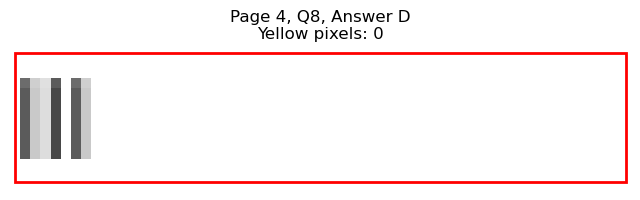

Page 4, Q8 - E: Detected box: x0=327.0, y0=695.4, x1=338.1, y1=708.0
Page 4, Q8, E: Yellow pixels: 0
Page 4, Q8, E: Total non-white pixels: 45
Page 4, Q8, E: Yellow percentage: 0.0%


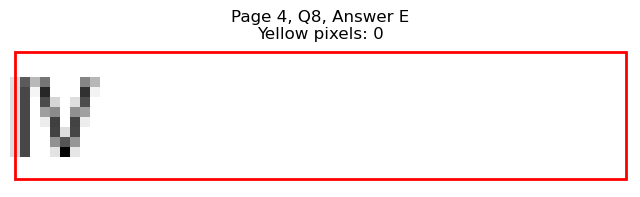


Page 4, Q8 - Selected Answer: B (based on yellow pixel count)





Page 5: Found 8 questions
Page 5, Q1 - A: Detected box: x0=68.3, y0=102.0, x1=120.5, y1=114.7
Page 5, Q1, A: Yellow pixels: 0
Page 5, Q1, A: Total non-white pixels: 282
Page 5, Q1, A: Yellow percentage: 0.0%


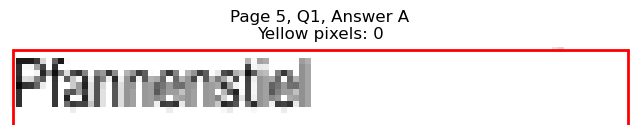

Page 5, Q1 - B: Detected box: x0=68.3, y0=114.6, x1=131.5, y1=127.3
Page 5, Q1, B: Yellow pixels: 0
Page 5, Q1, B: Total non-white pixels: 315
Page 5, Q1, B: Yellow percentage: 0.0%


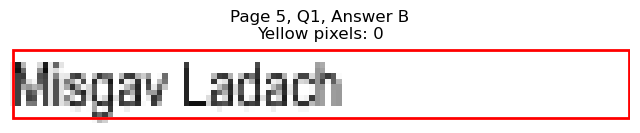

Page 5, Q1 - C: Detected box: x0=68.8, y0=127.2, x1=116.9, y1=139.9
Page 5, Q1, C: Yellow pixels: 0
Page 5, Q1, C: Total non-white pixels: 209
Page 5, Q1, C: Yellow percentage: 0.0%


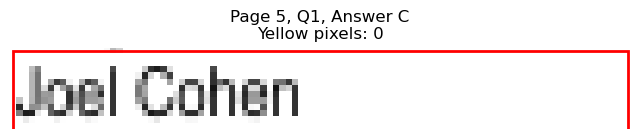

Page 5, Q1 - D: Detected box: x0=327.5, y0=102.0, x1=354.7, y1=114.7
Page 5, Q1, D: Yellow pixels: 0
Page 5, Q1, D: Total non-white pixels: 218
Page 5, Q1, D: Yellow percentage: 0.0%


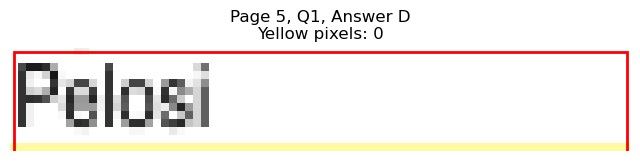

Page 5, Q1 - E: Detected box: x0=327.0, y0=114.6, x1=361.6, y1=127.3
Page 5, Q1, E: Yellow pixels: 864
Page 5, Q1, E: Total non-white pixels: 1190
Page 5, Q1, E: Yellow percentage: 72.6%


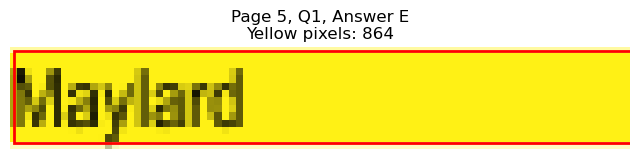


Page 5, Q1 - Selected Answer: E (based on yellow pixel count)




Page 5, Q2 - A: Detected box: x0=68.3, y0=165.1, x1=164.1, y1=177.8
Page 5, Q2, A: Yellow pixels: 0
Page 5, Q2, A: Total non-white pixels: 607
Page 5, Q2, A: Yellow percentage: 0.0%


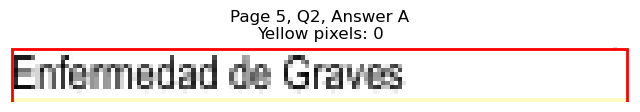

Page 5, Q2 - B: Detected box: x0=68.3, y0=177.7, x1=162.6, y1=190.4
Page 5, Q2, B: Yellow pixels: 1357
Page 5, Q2, B: Total non-white pixels: 2030
Page 5, Q2, B: Yellow percentage: 66.8%


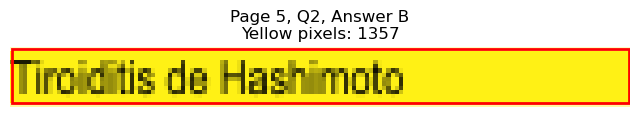

Page 5, Q2 - C: Detected box: x0=68.8, y0=190.3, x1=163.1, y1=203.0
Page 5, Q2, C: Yellow pixels: 0
Page 5, Q2, C: Total non-white pixels: 632
Page 5, Q2, C: Yellow percentage: 0.0%


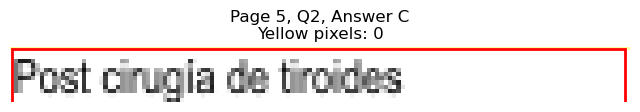

Page 5, Q2 - D: Detected box: x0=327.5, y0=165.1, x1=410.3, y1=177.8
Page 5, Q2, D: Yellow pixels: 0
Page 5, Q2, D: Total non-white pixels: 414
Page 5, Q2, D: Yellow percentage: 0.0%


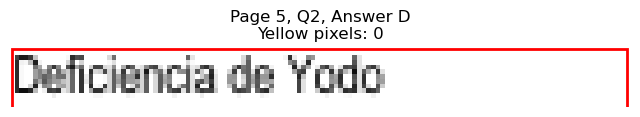

Page 5, Q2 - E: Detected box: x0=327.0, y0=177.7, x1=384.8, y1=190.4
Page 5, Q2, E: Yellow pixels: 0
Page 5, Q2, E: Total non-white pixels: 293
Page 5, Q2, E: Yellow percentage: 0.0%


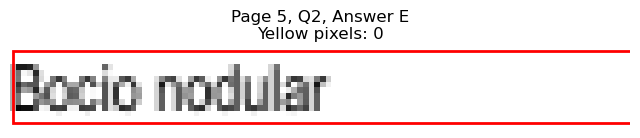


Page 5, Q2 - Selected Answer: B (based on yellow pixel count)




Page 5, Q3 - A: Detected box: x0=68.3, y0=253.5, x1=90.9, y1=266.1
Page 5, Q3, A: Yellow pixels: 0
Page 5, Q3, A: Total non-white pixels: 92
Page 5, Q3, A: Yellow percentage: 0.0%


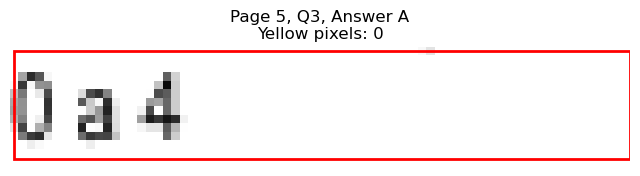

Page 5, Q3 - B: Detected box: x0=68.3, y0=266.1, x1=93.4, y1=278.7
Page 5, Q3, B: Yellow pixels: 0
Page 5, Q3, B: Total non-white pixels: 106
Page 5, Q3, B: Yellow percentage: 0.0%


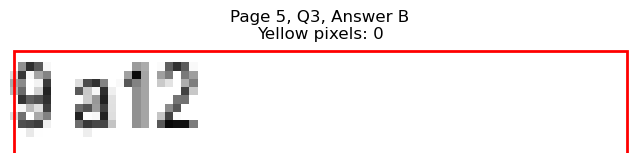

Page 5, Q3 - C: Detected box: x0=68.8, y0=278.8, x1=101.4, y1=291.5
Page 5, Q3, C: Yellow pixels: 0
Page 5, Q3, C: Total non-white pixels: 110
Page 5, Q3, C: Yellow percentage: 0.0%


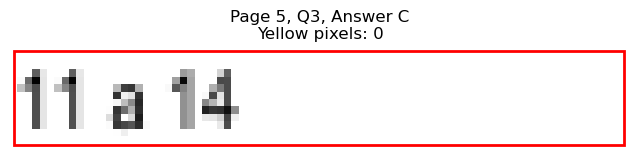

Page 5, Q3 - D: Detected box: x0=327.5, y0=253.5, x1=350.1, y1=266.1
Page 5, Q3, D: Yellow pixels: 891
Page 5, Q3, D: Total non-white pixels: 1036
Page 5, Q3, D: Yellow percentage: 86.0%


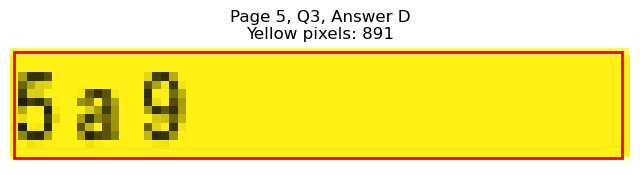

Page 5, Q3 - E: Detected box: x0=327.0, y0=266.1, x1=349.6, y1=278.7
Page 5, Q3, E: Yellow pixels: 0
Page 5, Q3, E: Total non-white pixels: 158
Page 5, Q3, E: Yellow percentage: 0.0%


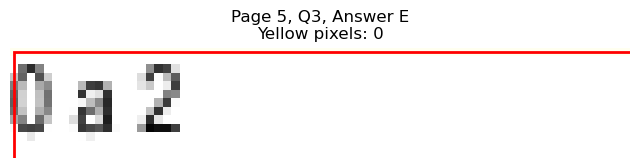


Page 5, Q3 - Selected Answer: D (based on yellow pixel count)




Page 5, Q4 - A: Detected box: x0=56.6, y0=341.9, x1=65.2, y1=354.6
Page 5, Q4, A: Yellow pixels: 0
Page 5, Q4, A: Total non-white pixels: 62
Page 5, Q4, A: Yellow percentage: 0.0%


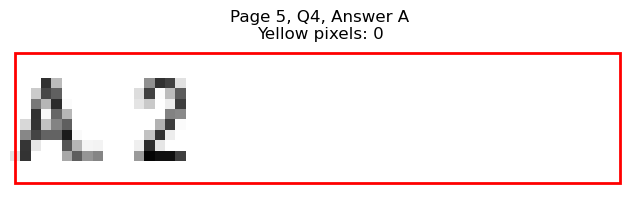

Page 5, Q4 - B: Detected box: x0=56.6, y0=354.5, x1=65.2, y1=367.2
Page 5, Q4, B: Yellow pixels: 0
Page 5, Q4, B: Total non-white pixels: 60
Page 5, Q4, B: Yellow percentage: 0.0%


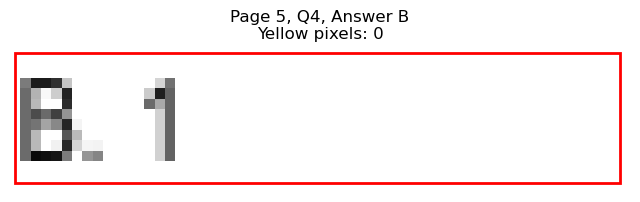

Page 5, Q4 - C: Detected box: x0=68.8, y0=367.1, x1=83.9, y1=379.8
Page 5, Q4, C: Yellow pixels: 0
Page 5, Q4, C: Total non-white pixels: 68
Page 5, Q4, C: Yellow percentage: 0.0%


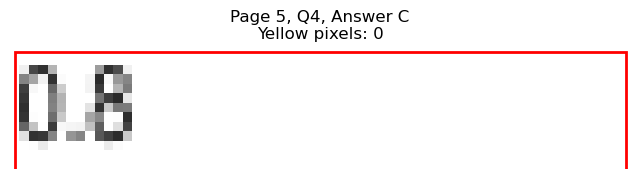

Page 5, Q4 - D: Detected box: x0=327.5, y0=341.9, x1=342.7, y1=354.6
Page 5, Q4, D: Yellow pixels: 66
Page 5, Q4, D: Total non-white pixels: 128
Page 5, Q4, D: Yellow percentage: 51.6%


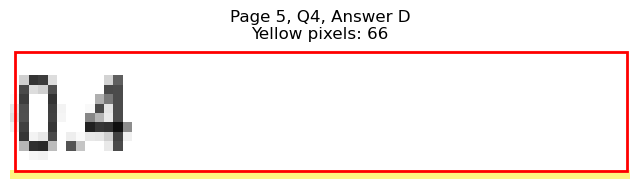

Page 5, Q4 - E: Detected box: x0=315.4, y0=354.5, x1=323.9, y1=367.2
Page 5, Q4, E: Yellow pixels: 721
Page 5, Q4, E: Total non-white pixels: 826
Page 5, Q4, E: Yellow percentage: 87.3%


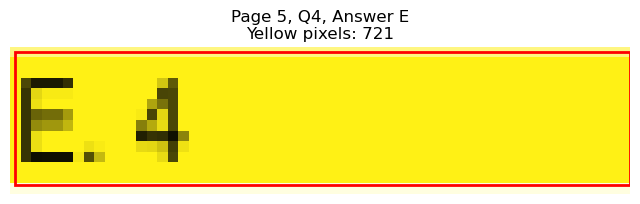


Page 5, Q4 - Selected Answer: E (based on yellow pixel count)




Page 5, Q5 - A: Detected box: x0=68.3, y0=430.2, x1=164.1, y1=442.9
Page 5, Q5, A: Yellow pixels: 0
Page 5, Q5, A: Total non-white pixels: 600
Page 5, Q5, A: Yellow percentage: 0.0%


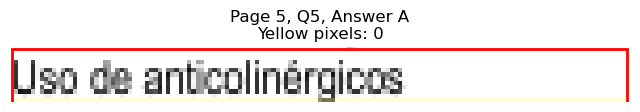

Page 5, Q5 - B: Detected box: x0=68.3, y0=442.8, x1=152.5, y1=455.5
Page 5, Q5, B: Yellow pixels: 1410
Page 5, Q5, B: Total non-white pixels: 1890
Page 5, Q5, B: Yellow percentage: 74.6%


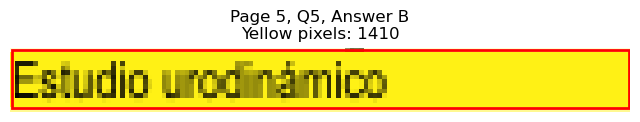

Page 5, Q5 - C: Detected box: x0=68.8, y0=455.5, x1=136.5, y1=468.1
Page 5, Q5, C: Yellow pixels: 0
Page 5, Q5, C: Total non-white pixels: 325
Page 5, Q5, C: Yellow percentage: 0.0%


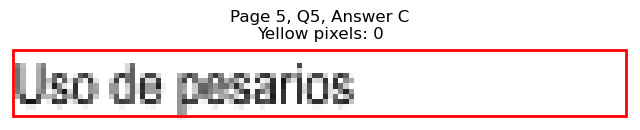

Page 5, Q5 - D: Detected box: x0=327.5, y0=430.2, x1=406.7, y1=442.9
Page 5, Q5, D: Yellow pixels: 0
Page 5, Q5, D: Total non-white pixels: 403
Page 5, Q5, D: Yellow percentage: 0.0%


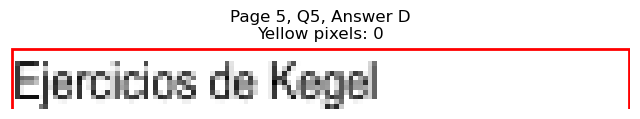

Page 5, Q5 - E: Detected box: x0=327.0, y0=442.8, x1=467.0, y1=455.5
Page 5, Q5, E: Yellow pixels: 0
Page 5, Q5, E: Total non-white pixels: 747
Page 5, Q5, E: Yellow percentage: 0.0%


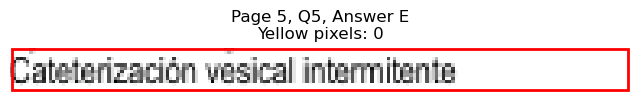


Page 5, Q5 - Selected Answer: B (based on yellow pixel count)




Page 5, Q6 - A: Detected box: x0=68.3, y0=506.0, x1=79.3, y1=518.6
Page 5, Q6, A: Yellow pixels: 62
Page 5, Q6, A: Total non-white pixels: 104
Page 5, Q6, A: Yellow percentage: 59.6%


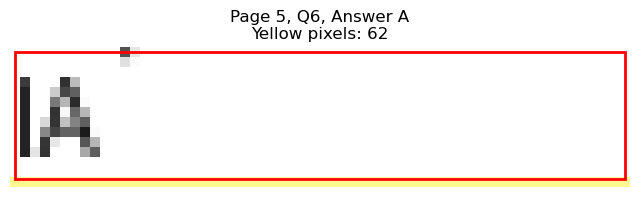

Page 5, Q6 - B: Detected box: x0=56.6, y0=518.6, x1=65.2, y1=531.2
Page 5, Q6, B: Yellow pixels: 719
Page 5, Q6, B: Total non-white pixels: 840
Page 5, Q6, B: Yellow percentage: 85.6%


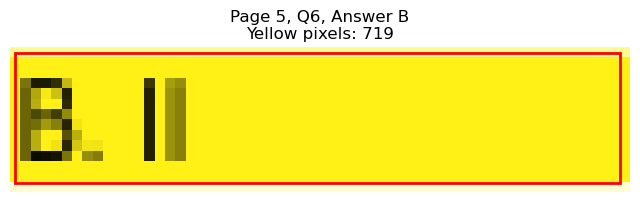

Page 5, Q6 - C: Detected box: x0=68.8, y0=531.2, x1=79.8, y1=543.8
Page 5, Q6, C: Yellow pixels: 0
Page 5, Q6, C: Total non-white pixels: 119
Page 5, Q6, C: Yellow percentage: 0.0%


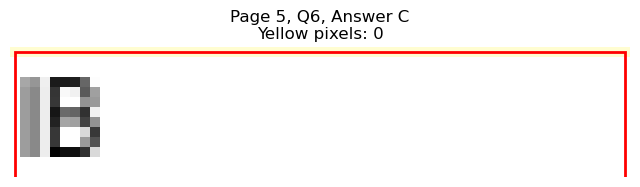

Page 5, Q6 - D: Detected box: x0=327.5, y0=506.0, x1=337.6, y1=518.6
Page 5, Q6, D: Yellow pixels: 0
Page 5, Q6, D: Total non-white pixels: 48
Page 5, Q6, D: Yellow percentage: 0.0%


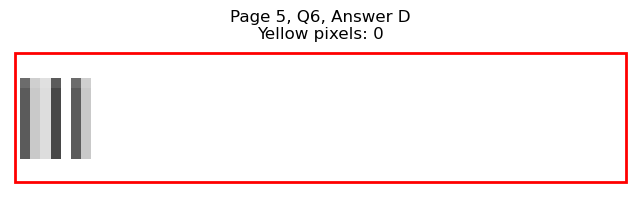

Page 5, Q6 - E: Detected box: x0=327.0, y0=518.6, x1=338.1, y1=531.2
Page 5, Q6, E: Yellow pixels: 0
Page 5, Q6, E: Total non-white pixels: 45
Page 5, Q6, E: Yellow percentage: 0.0%


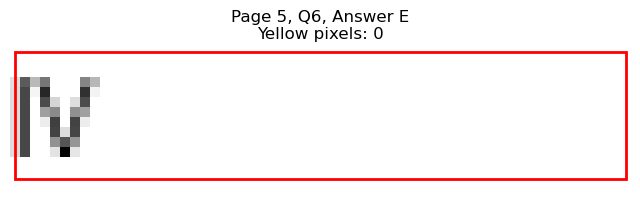


Page 5, Q6 - Selected Answer: B (based on yellow pixel count)




Page 5, Q7 - A: Detected box: x0=68.3, y0=581.7, x1=116.9, y1=594.4
Page 5, Q7, A: Yellow pixels: 99
Page 5, Q7, A: Total non-white pixels: 350
Page 5, Q7, A: Yellow percentage: 28.3%


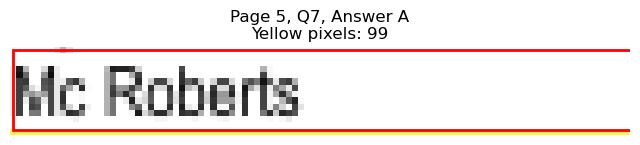

Page 5, Q7 - B: Detected box: x0=68.3, y0=594.3, x1=98.9, y1=607.0
Page 5, Q7, B: Yellow pixels: 930
Page 5, Q7, B: Total non-white pixels: 1053
Page 5, Q7, B: Yellow percentage: 88.3%


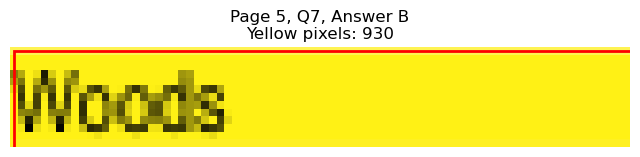

Page 5, Q7 - C: Detected box: x0=68.8, y0=606.9, x1=99.4, y1=619.6
Page 5, Q7, C: Yellow pixels: 82
Page 5, Q7, C: Total non-white pixels: 239
Page 5, Q7, C: Yellow percentage: 34.3%


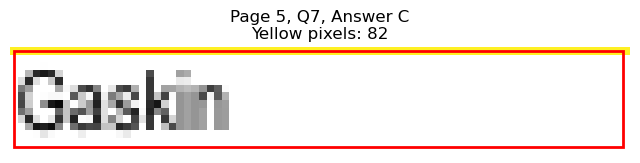

Page 5, Q7 - D: Detected box: x0=327.5, y0=581.7, x1=353.6, y1=594.4
Page 5, Q7, D: Yellow pixels: 0
Page 5, Q7, D: Total non-white pixels: 126
Page 5, Q7, D: Yellow percentage: 0.0%


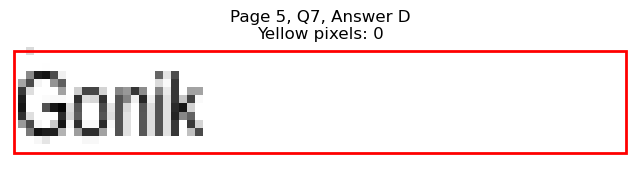

Page 5, Q7 - E: Detected box: x0=327.0, y0=594.3, x1=362.2, y1=607.0
Page 5, Q7, E: Yellow pixels: 0
Page 5, Q7, E: Total non-white pixels: 188
Page 5, Q7, E: Yellow percentage: 0.0%


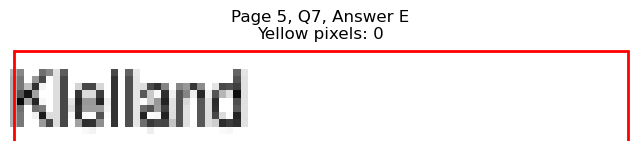


Page 5, Q7 - Selected Answer: B (based on yellow pixel count)




Page 5, Q8 - A: Detected box: x0=68.3, y0=682.7, x1=170.7, y1=695.3
Page 5, Q8, A: Yellow pixels: 0
Page 5, Q8, A: Total non-white pixels: 507
Page 5, Q8, A: Yellow percentage: 0.0%


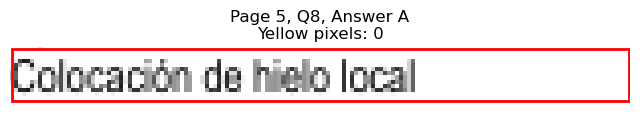

Page 5, Q8 - B: Detected box: x0=68.3, y0=695.4, x1=175.1, y1=708.0
Page 5, Q8, B: Yellow pixels: 0
Page 5, Q8, B: Total non-white pixels: 530
Page 5, Q8, B: Yellow percentage: 0.0%


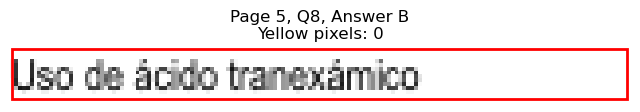

Page 5, Q8 - C: Detected box: x0=68.8, y0=708.0, x1=160.1, y1=720.6
Page 5, Q8, C: Yellow pixels: 0
Page 5, Q8, C: Total non-white pixels: 433
Page 5, Q8, C: Yellow percentage: 0.0%


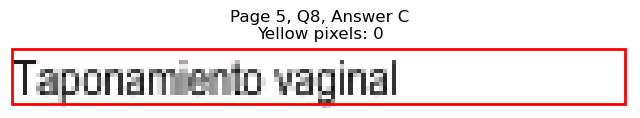

Page 5, Q8 - D: Detected box: x0=327.5, y0=682.7, x1=406.3, y1=695.3
Page 5, Q8, D: Yellow pixels: 0
Page 5, Q8, D: Total non-white pixels: 418
Page 5, Q8, D: Yellow percentage: 0.0%


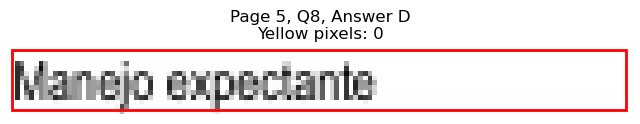

Page 5, Q8 - E: Detected box: x0=327.0, y0=695.4, x1=475.5, y1=708.0
Page 5, Q8, E: Yellow pixels: 2019
Page 5, Q8, E: Total non-white pixels: 2592
Page 5, Q8, E: Yellow percentage: 77.9%


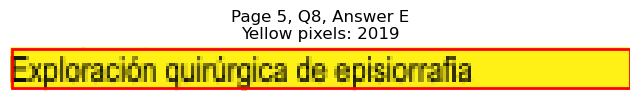


Page 5, Q8 - Selected Answer: E (based on yellow pixel count)





Page 6: Found 9 questions
Page 6, Q1 - A: Detected box: x0=68.3, y0=89.4, x1=97.3, y1=102.1
Page 6, Q1, A: Yellow pixels: 80
Page 6, Q1, A: Total non-white pixels: 226
Page 6, Q1, A: Yellow percentage: 35.4%


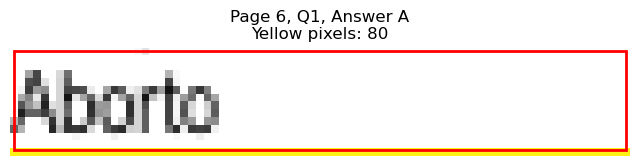

Page 6, Q1 - B: Detected box: x0=68.3, y0=102.0, x1=152.1, y1=114.7
Page 6, Q1, B: Yellow pixels: 1440
Page 6, Q1, B: Total non-white pixels: 1755
Page 6, Q1, B: Yellow percentage: 82.1%


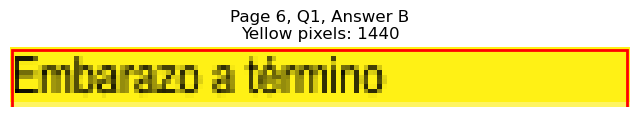

Page 6, Q1 - C: Detected box: x0=68.8, y0=114.6, x1=148.6, y1=127.3
Page 6, Q1, C: Yellow pixels: 131
Page 6, Q1, C: Total non-white pixels: 525
Page 6, Q1, C: Yellow percentage: 25.0%


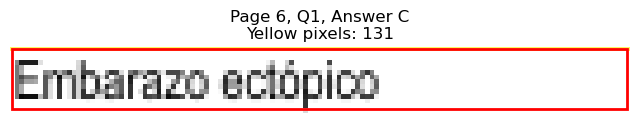

Page 6, Q1 - D: Detected box: x0=327.5, y0=89.4, x1=369.2, y1=102.1
Page 6, Q1, D: Yellow pixels: 0
Page 6, Q1, D: Total non-white pixels: 219
Page 6, Q1, D: Yellow percentage: 0.0%


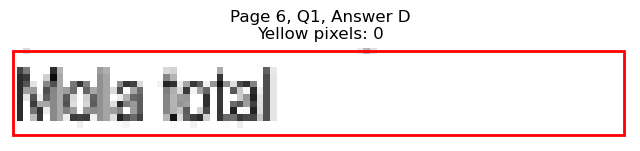

Page 6, Q1 - E: Detected box: x0=327.0, y0=102.0, x1=378.2, y1=114.7
Page 6, Q1, E: Yellow pixels: 0
Page 6, Q1, E: Total non-white pixels: 267
Page 6, Q1, E: Yellow percentage: 0.0%


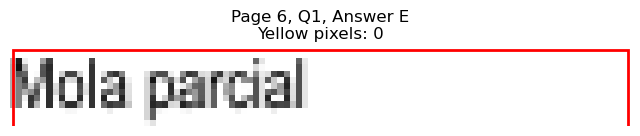


Page 6, Q1 - Selected Answer: B (based on yellow pixel count)




Page 6, Q2 - A: Detected box: x0=68.3, y0=152.5, x1=115.5, y1=165.2
Page 6, Q2, A: Yellow pixels: 0
Page 6, Q2, A: Total non-white pixels: 227
Page 6, Q2, A: Yellow percentage: 0.0%


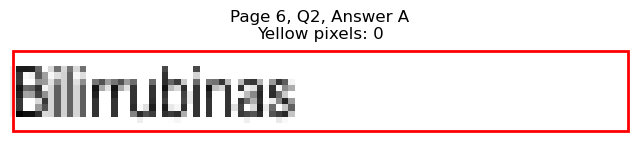

Page 6, Q2 - B: Detected box: x0=68.3, y0=165.1, x1=90.4, y1=177.8
Page 6, Q2, B: Yellow pixels: 0
Page 6, Q2, B: Total non-white pixels: 174
Page 6, Q2, B: Yellow percentage: 0.0%


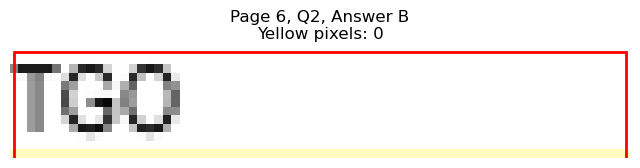

Page 6, Q2 - C: Detected box: x0=68.8, y0=177.7, x1=118.9, y1=190.4
Page 6, Q2, C: Yellow pixels: 1012
Page 6, Q2, C: Total non-white pixels: 1414
Page 6, Q2, C: Yellow percentage: 71.6%


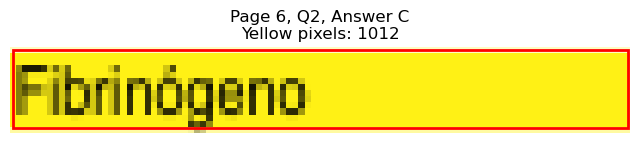

Page 6, Q2 - D: Detected box: x0=327.5, y0=152.5, x1=348.7, y1=165.2
Page 6, Q2, D: Yellow pixels: 0
Page 6, Q2, D: Total non-white pixels: 98
Page 6, Q2, D: Yellow percentage: 0.0%


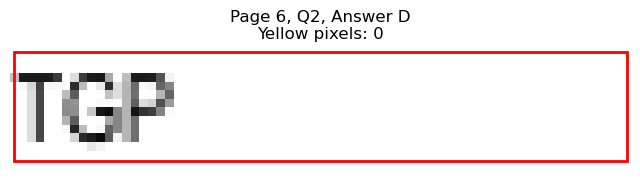

Page 6, Q2 - E: Detected box: x0=327.0, y0=165.1, x1=423.3, y1=177.8
Page 6, Q2, E: Yellow pixels: 0
Page 6, Q2, E: Total non-white pixels: 532
Page 6, Q2, E: Yellow percentage: 0.0%


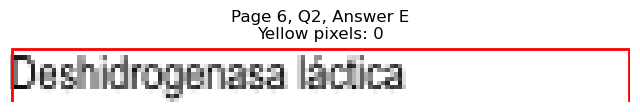


Page 6, Q2 - Selected Answer: C (based on yellow pixel count)




Page 6, Q3 - A: Detected box: x0=68.3, y0=240.9, x1=157.6, y1=253.5
Page 6, Q3, A: Yellow pixels: 1469
Page 6, Q3, A: Total non-white pixels: 1960
Page 6, Q3, A: Yellow percentage: 74.9%


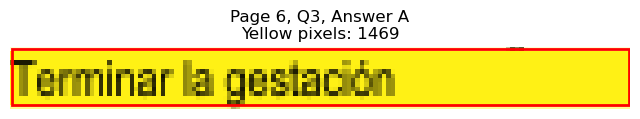

Page 6, Q3 - B: Detected box: x0=68.3, y0=253.5, x1=264.4, y1=266.1
Page 6, Q3, B: Yellow pixels: 212
Page 6, Q3, B: Total non-white pixels: 1173
Page 6, Q3, B: Yellow percentage: 18.1%


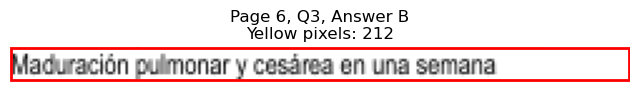

Page 6, Q3 - C: Detected box: x0=68.8, y0=266.1, x1=196.2, y1=278.7
Page 6, Q3, C: Yellow pixels: 0
Page 6, Q3, C: Total non-white pixels: 623
Page 6, Q3, C: Yellow percentage: 0.0%


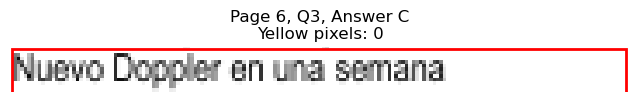

Page 6, Q3 - D: Detected box: x0=327.5, y0=240.9, x1=513.1, y1=253.5
Page 6, Q3, D: Yellow pixels: 0
Page 6, Q3, D: Total non-white pixels: 898
Page 6, Q3, D: Yellow percentage: 0.0%


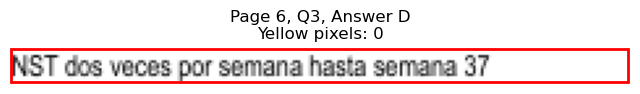

Page 6, Q3 - E: Detected box: x0=327.0, y0=253.5, x1=476.0, y1=266.1
Page 6, Q3, E: Yellow pixels: 0
Page 6, Q3, E: Total non-white pixels: 728
Page 6, Q3, E: Yellow percentage: 0.0%


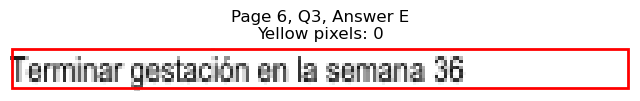


Page 6, Q3 - Selected Answer: A (based on yellow pixel count)




Page 6, Q4 - A: Detected box: x0=68.3, y0=304.0, x1=130.5, y1=316.7
Page 6, Q4, A: Yellow pixels: 0
Page 6, Q4, A: Total non-white pixels: 302
Page 6, Q4, A: Yellow percentage: 0.0%


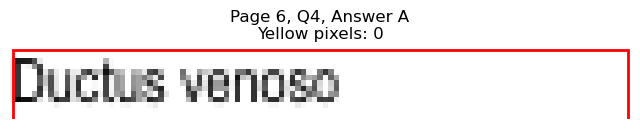

Page 6, Q4 - B: Detected box: x0=68.3, y0=316.6, x1=141.5, y1=329.3
Page 6, Q4, B: Yellow pixels: 0
Page 6, Q4, B: Total non-white pixels: 346
Page 6, Q4, B: Yellow percentage: 0.0%


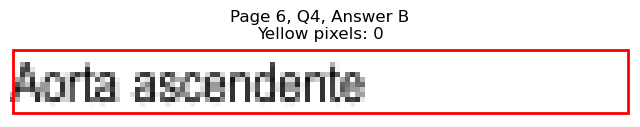

Page 6, Q4 - C: Detected box: x0=68.8, y0=329.2, x1=147.0, y1=341.9
Page 6, Q4, C: Yellow pixels: 0
Page 6, Q4, C: Total non-white pixels: 407
Page 6, Q4, C: Yellow percentage: 0.0%


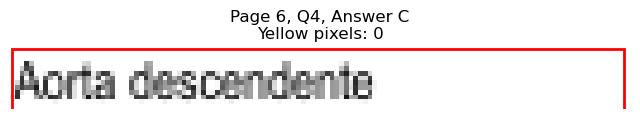

Page 6, Q4 - D: Detected box: x0=327.5, y0=304.0, x1=388.7, y1=316.7
Page 6, Q4, D: Yellow pixels: 1234
Page 6, Q4, D: Total non-white pixels: 1456
Page 6, Q4, D: Yellow percentage: 84.8%


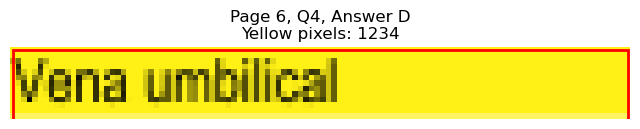

Page 6, Q4 - E: Detected box: x0=327.0, y0=316.6, x1=409.3, y1=329.3
Page 6, Q4, E: Yellow pixels: 133
Page 6, Q4, E: Total non-white pixels: 554
Page 6, Q4, E: Yellow percentage: 24.0%


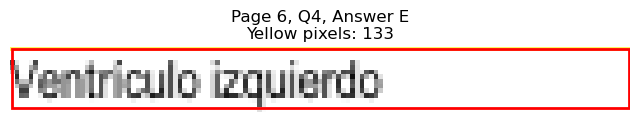


Page 6, Q4 - Selected Answer: D (based on yellow pixel count)




Page 6, Q5 - A: Detected box: x0=68.3, y0=392.3, x1=104.4, y1=405.0
Page 6, Q5, A: Yellow pixels: 0
Page 6, Q5, A: Total non-white pixels: 287
Page 6, Q5, A: Yellow percentage: 0.0%


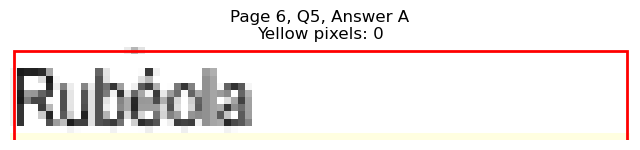

Page 6, Q5 - B: Detected box: x0=68.3, y0=404.9, x1=135.5, y1=417.6
Page 6, Q5, B: Yellow pixels: 1260
Page 6, Q5, B: Total non-white pixels: 1652
Page 6, Q5, B: Yellow percentage: 76.3%


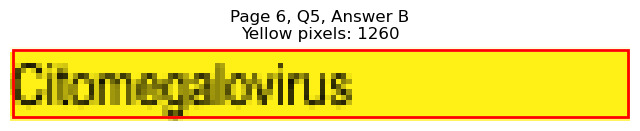

Page 6, Q5 - C: Detected box: x0=68.8, y0=417.6, x1=103.9, y1=430.3
Page 6, Q5, C: Yellow pixels: 85
Page 6, Q5, C: Total non-white pixels: 256
Page 6, Q5, C: Yellow percentage: 33.2%


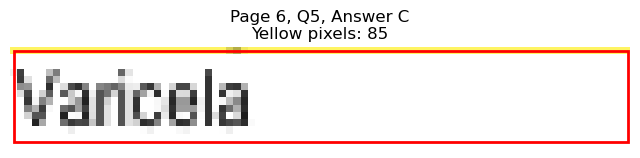

Page 6, Q5 - D: Detected box: x0=327.5, y0=392.3, x1=390.2, y1=405.0
Page 6, Q5, D: Yellow pixels: 0
Page 6, Q5, D: Total non-white pixels: 326
Page 6, Q5, D: Yellow percentage: 0.0%


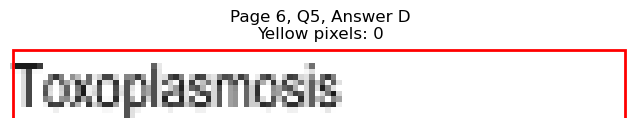

Page 6, Q5 - E: Detected box: x0=327.0, y0=404.9, x1=351.2, y1=417.6
Page 6, Q5, E: Yellow pixels: 0
Page 6, Q5, E: Total non-white pixels: 146
Page 6, Q5, E: Yellow percentage: 0.0%


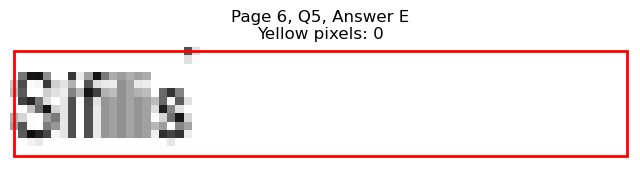


Page 6, Q5 - Selected Answer: B (based on yellow pixel count)




Page 6, Q6 - A: Detected box: x0=68.3, y0=468.1, x1=241.8, y1=480.7
Page 6, Q6, A: Yellow pixels: 2155
Page 6, Q6, A: Total non-white pixels: 2782
Page 6, Q6, A: Yellow percentage: 77.5%


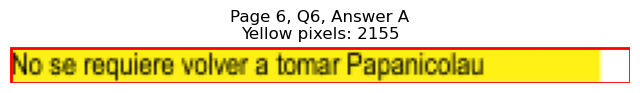

Page 6, Q6 - B: Detected box: x0=68.3, y0=480.8, x1=210.3, y1=493.4
Page 6, Q6, B: Yellow pixels: 193
Page 6, Q6, B: Total non-white pixels: 866
Page 6, Q6, B: Yellow percentage: 22.3%


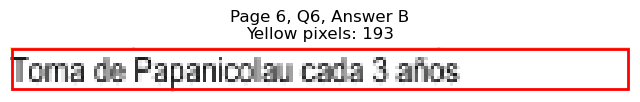

Page 6, Q6 - C: Detected box: x0=68.8, y0=493.4, x1=201.6, y1=506.0
Page 6, Q6, C: Yellow pixels: 0
Page 6, Q6, C: Total non-white pixels: 647
Page 6, Q6, C: Yellow percentage: 0.0%


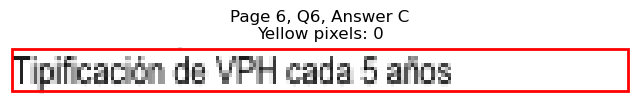

Page 6, Q6 - D: Detected box: x0=327.5, y0=468.1, x1=380.3, y1=480.7
Page 6, Q6, D: Yellow pixels: 0
Page 6, Q6, D: Total non-white pixels: 275
Page 6, Q6, D: Yellow percentage: 0.0%


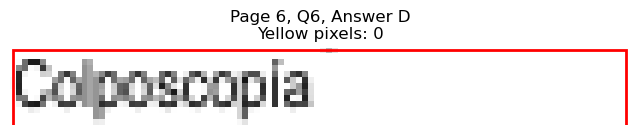

Page 6, Q6 - E: Detected box: x0=327.0, y0=480.8, x1=457.0, y1=493.4
Page 6, Q6, E: Yellow pixels: 0
Page 6, Q6, E: Total non-white pixels: 641
Page 6, Q6, E: Yellow percentage: 0.0%


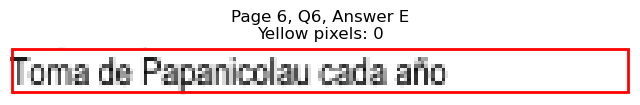


Page 6, Q6 - Selected Answer: A (based on yellow pixel count)




Page 6, Q7 - A: Detected box: x0=68.3, y0=543.8, x1=181.1, y1=556.4
Page 6, Q7, A: Yellow pixels: 0
Page 6, Q7, A: Total non-white pixels: 577
Page 6, Q7, A: Yellow percentage: 0.0%


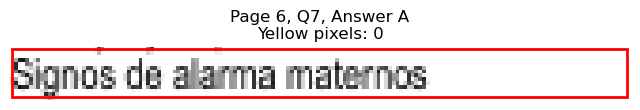

Page 6, Q7 - B: Detected box: x0=68.3, y0=556.5, x1=183.1, y1=569.2
Page 6, Q7, B: Yellow pixels: 1666
Page 6, Q7, B: Total non-white pixels: 2324
Page 6, Q7, B: Yellow percentage: 71.7%


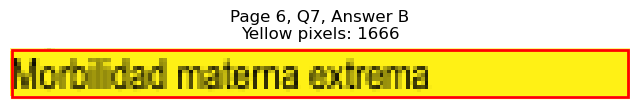

Page 6, Q7 - C: Detected box: x0=68.8, y0=569.1, x1=155.5, y1=581.8
Page 6, Q7, C: Yellow pixels: 0
Page 6, Q7, C: Total non-white pixels: 587
Page 6, Q7, C: Yellow percentage: 0.0%


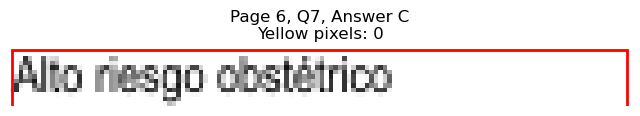

Page 6, Q7 - D: Detected box: x0=327.5, y0=543.8, x1=450.9, y1=556.4
Page 6, Q7, D: Yellow pixels: 0
Page 6, Q7, D: Total non-white pixels: 638
Page 6, Q7, D: Yellow percentage: 0.0%


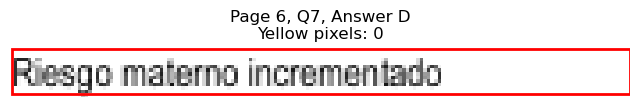

Page 6, Q7 - E: Detected box: x0=327.0, y0=556.5, x1=407.3, y1=569.2
Page 6, Q7, E: Yellow pixels: 0
Page 6, Q7, E: Total non-white pixels: 412
Page 6, Q7, E: Yellow percentage: 0.0%


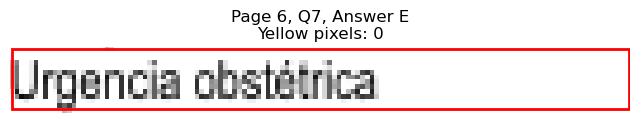


Page 6, Q7 - Selected Answer: B (based on yellow pixel count)




Page 6, Q8 - A: Detected box: x0=68.3, y0=619.6, x1=199.7, y1=632.3
Page 6, Q8, A: Yellow pixels: 1660
Page 6, Q8, A: Total non-white pixels: 2548
Page 6, Q8, A: Yellow percentage: 65.1%


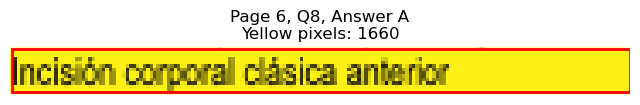

Page 6, Q8 - B: Detected box: x0=68.3, y0=632.2, x1=109.5, y1=644.9
Page 6, Q8, B: Yellow pixels: 0
Page 6, Q8, B: Total non-white pixels: 324
Page 6, Q8, B: Yellow percentage: 0.0%


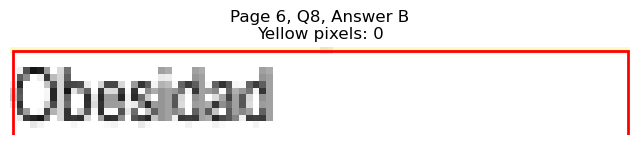

Page 6, Q8 - C: Detected box: x0=68.8, y0=644.9, x1=119.9, y1=657.5
Page 6, Q8, C: Yellow pixels: 0
Page 6, Q8, C: Total non-white pixels: 233
Page 6, Q8, C: Yellow percentage: 0.0%


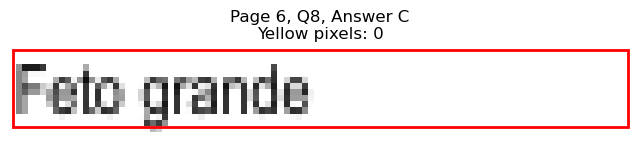

Page 6, Q8 - D: Detected box: x0=327.5, y0=619.6, x1=439.9, y1=632.3
Page 6, Q8, D: Yellow pixels: 0
Page 6, Q8, D: Total non-white pixels: 562
Page 6, Q8, D: Yellow percentage: 0.0%


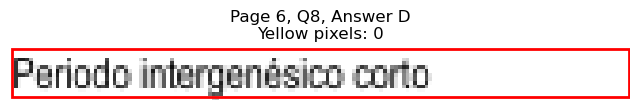

Page 6, Q8 - E: Detected box: x0=327.0, y0=632.2, x1=427.9, y1=644.9
Page 6, Q8, E: Yellow pixels: 0
Page 6, Q8, E: Total non-white pixels: 501
Page 6, Q8, E: Yellow percentage: 0.0%


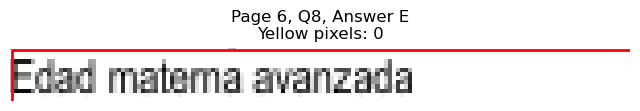


Page 6, Q8 - Selected Answer: A (based on yellow pixel count)




Page 6, Q9 - A: Detected box: x0=68.3, y0=682.7, x1=118.9, y1=695.3
Page 6, Q9, A: Yellow pixels: 0
Page 6, Q9, A: Total non-white pixels: 277
Page 6, Q9, A: Yellow percentage: 0.0%


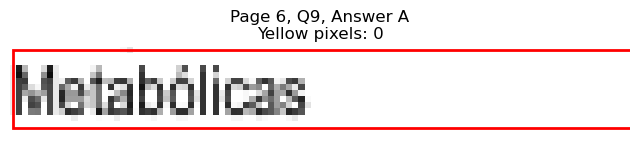

Page 6, Q9 - B: Detected box: x0=68.3, y0=695.4, x1=130.5, y1=708.0
Page 6, Q9, B: Yellow pixels: 113
Page 6, Q9, B: Total non-white pixels: 564
Page 6, Q9, B: Yellow percentage: 20.0%


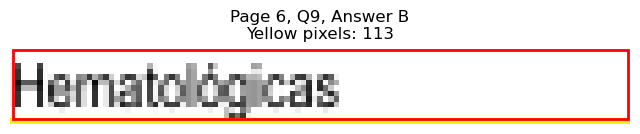

Page 6, Q9 - C: Detected box: x0=68.8, y0=708.0, x1=141.0, y1=720.6
Page 6, Q9, C: Yellow pixels: 1301
Page 6, Q9, C: Total non-white pixels: 1736
Page 6, Q9, C: Yellow percentage: 74.9%


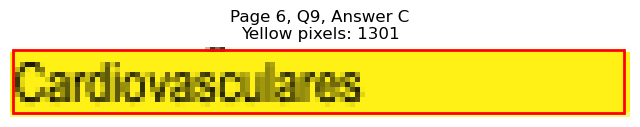

Page 6, Q9 - D: Detected box: x0=327.5, y0=682.7, x1=375.2, y1=695.3
Page 6, Q9, D: Yellow pixels: 0
Page 6, Q9, D: Total non-white pixels: 251
Page 6, Q9, D: Yellow percentage: 0.0%


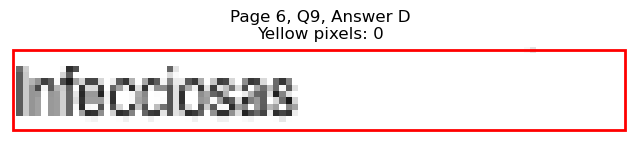

Page 6, Q9 - E: Detected box: x0=327.0, y0=695.4, x1=363.2, y1=708.0
Page 6, Q9, E: Yellow pixels: 0
Page 6, Q9, E: Total non-white pixels: 174
Page 6, Q9, E: Yellow percentage: 0.0%


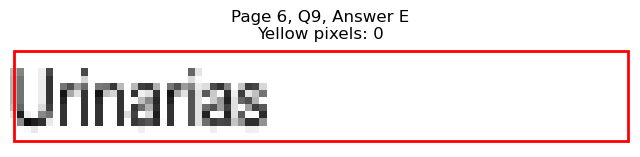


Page 6, Q9 - Selected Answer: C (based on yellow pixel count)





Page 7: Found 8 questions
Page 7, Q1 - A: Detected box: x0=68.3, y0=114.6, x1=132.0, y1=127.3
Page 7, Q1, A: Yellow pixels: 115
Page 7, Q1, A: Total non-white pixels: 405
Page 7, Q1, A: Yellow percentage: 28.4%


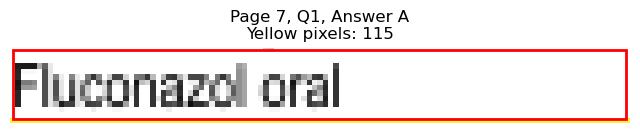

Page 7, Q1 - B: Detected box: x0=68.3, y0=127.2, x1=140.1, y1=139.9
Page 7, Q1, B: Yellow pixels: 1335
Page 7, Q1, B: Total non-white pixels: 1599
Page 7, Q1, B: Yellow percentage: 83.5%


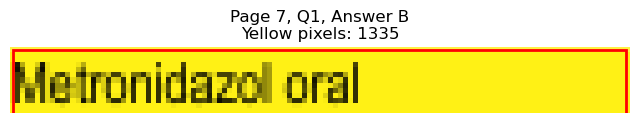

Page 7, Q1 - C: Detected box: x0=68.8, y0=139.9, x1=147.5, y1=152.6
Page 7, Q1, C: Yellow pixels: 130
Page 7, Q1, C: Total non-white pixels: 519
Page 7, Q1, C: Yellow percentage: 25.0%


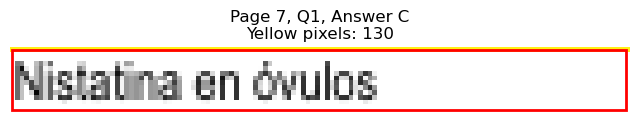

Page 7, Q1 - D: Detected box: x0=327.5, y0=114.6, x1=396.8, y1=127.3
Page 7, Q1, D: Yellow pixels: 0
Page 7, Q1, D: Total non-white pixels: 343
Page 7, Q1, D: Yellow percentage: 0.0%


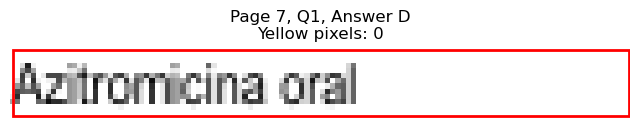

Page 7, Q1 - E: Detected box: x0=327.0, y0=127.2, x1=403.3, y1=139.9
Page 7, Q1, E: Yellow pixels: 0
Page 7, Q1, E: Total non-white pixels: 382
Page 7, Q1, E: Yellow percentage: 0.0%


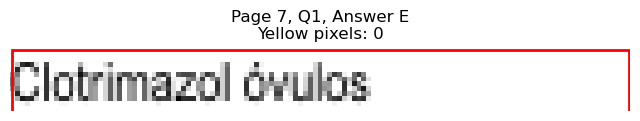


Page 7, Q1 - Selected Answer: B (based on yellow pixel count)




Page 7, Q2 - A: Detected box: x0=68.3, y0=202.9, x1=133.0, y1=215.6
Page 7, Q2, A: Yellow pixels: 0
Page 7, Q2, A: Total non-white pixels: 342
Page 7, Q2, A: Yellow percentage: 0.0%


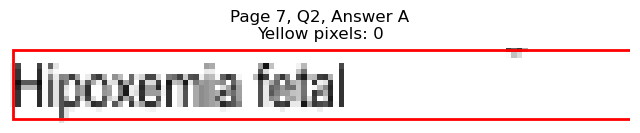

Page 7, Q2 - B: Detected box: x0=68.3, y0=215.7, x1=190.2, y1=228.3
Page 7, Q2, B: Yellow pixels: 0
Page 7, Q2, B: Total non-white pixels: 599
Page 7, Q2, B: Yellow percentage: 0.0%


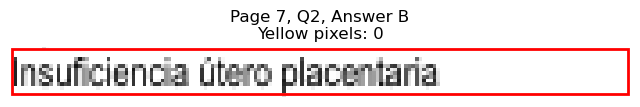

Page 7, Q2 - C: Detected box: x0=68.8, y0=228.3, x1=221.8, y1=240.9
Page 7, Q2, C: Yellow pixels: 0
Page 7, Q2, C: Total non-white pixels: 747
Page 7, Q2, C: Yellow percentage: 0.0%


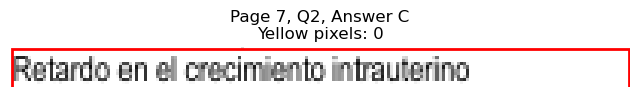

Page 7, Q2 - D: Detected box: x0=327.5, y0=202.9, x1=460.5, y1=215.6
Page 7, Q2, D: Yellow pixels: 1892
Page 7, Q2, D: Total non-white pixels: 2576
Page 7, Q2, D: Yellow percentage: 73.4%


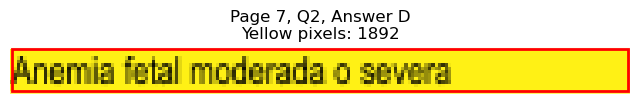

Page 7, Q2 - E: Detected box: x0=327.0, y0=215.7, x1=422.3, y1=228.3
Page 7, Q2, E: Yellow pixels: 146
Page 7, Q2, E: Total non-white pixels: 634
Page 7, Q2, E: Yellow percentage: 23.0%


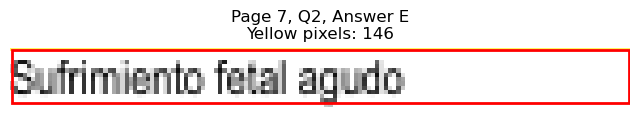


Page 7, Q2 - Selected Answer: D (based on yellow pixel count)




Page 7, Q3 - A: Detected box: x0=68.3, y0=291.4, x1=112.5, y1=304.1
Page 7, Q3, A: Yellow pixels: 0
Page 7, Q3, A: Total non-white pixels: 412
Page 7, Q3, A: Yellow percentage: 0.0%


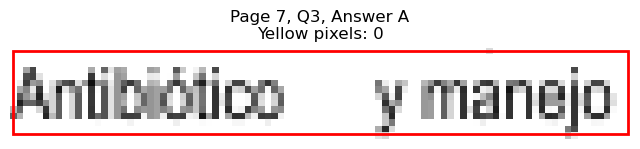

Page 7, Q3 - B: Detected box: x0=68.3, y0=316.6, x1=238.8, y1=329.3
Page 7, Q3, B: Yellow pixels: 1884
Page 7, Q3, B: Total non-white pixels: 2996
Page 7, Q3, B: Yellow percentage: 62.9%


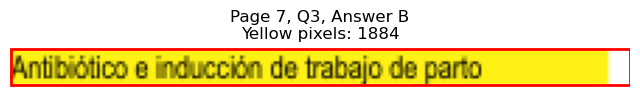

Page 7, Q3 - C: Detected box: x0=68.8, y0=329.2, x1=158.1, y1=341.9
Page 7, Q3, C: Yellow pixels: 0
Page 7, Q3, C: Total non-white pixels: 584
Page 7, Q3, C: Yellow percentage: 0.0%


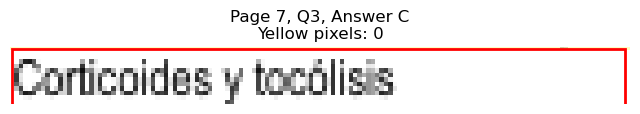

Page 7, Q3 - D: Detected box: x0=327.5, y0=291.4, x1=478.5, y1=304.1
Page 7, Q3, D: Yellow pixels: 0
Page 7, Q3, D: Total non-white pixels: 797
Page 7, Q3, D: Yellow percentage: 0.0%


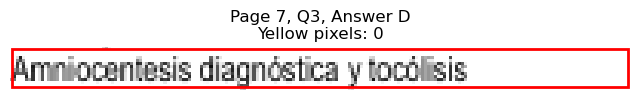

Page 7, Q3 - E: Detected box: x0=327.0, y0=304.0, x1=478.7, y1=316.7
Page 7, Q3, E: Yellow pixels: 0
Page 7, Q3, E: Total non-white pixels: 759
Page 7, Q3, E: Yellow percentage: 0.0%


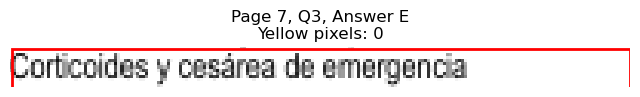


Page 7, Q3 - Selected Answer: B (based on yellow pixel count)




Page 7, Q4 - A: Detected box: x0=68.3, y0=379.7, x1=90.9, y1=392.4
Page 7, Q4, A: Yellow pixels: 0
Page 7, Q4, A: Total non-white pixels: 76
Page 7, Q4, A: Yellow percentage: 0.0%


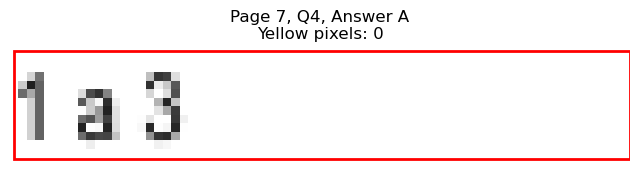

Page 7, Q4 - B: Detected box: x0=68.3, y0=392.3, x1=100.9, y1=405.0
Page 7, Q4, B: Yellow pixels: 0
Page 7, Q4, B: Total non-white pixels: 202
Page 7, Q4, B: Yellow percentage: 0.0%


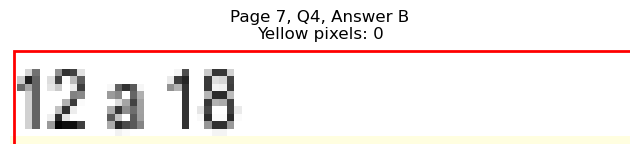

Page 7, Q4 - C: Detected box: x0=68.8, y0=404.9, x1=96.5, y1=417.6
Page 7, Q4, C: Yellow pixels: 943
Page 7, Q4, C: Total non-white pixels: 1106
Page 7, Q4, C: Yellow percentage: 85.3%


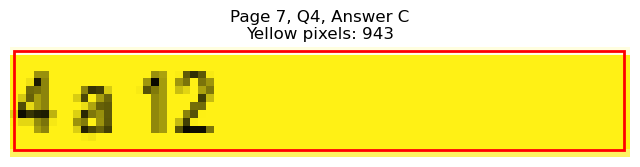

Page 7, Q4 - D: Detected box: x0=327.5, y0=379.7, x1=360.2, y1=392.4
Page 7, Q4, D: Yellow pixels: 0
Page 7, Q4, D: Total non-white pixels: 129
Page 7, Q4, D: Yellow percentage: 0.0%


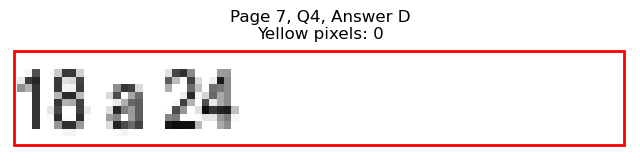

Page 7, Q4 - E: Detected box: x0=327.0, y0=392.3, x1=359.7, y1=405.0
Page 7, Q4, E: Yellow pixels: 0
Page 7, Q4, E: Total non-white pixels: 141
Page 7, Q4, E: Yellow percentage: 0.0%


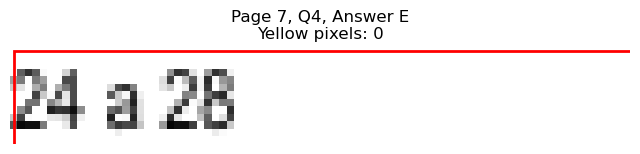


Page 7, Q4 - Selected Answer: C (based on yellow pixel count)




Page 7, Q5 - A: Detected box: x0=68.3, y0=468.1, x1=151.6, y1=480.7
Page 7, Q5, A: Yellow pixels: 0
Page 7, Q5, A: Total non-white pixels: 403
Page 7, Q5, A: Yellow percentage: 0.0%


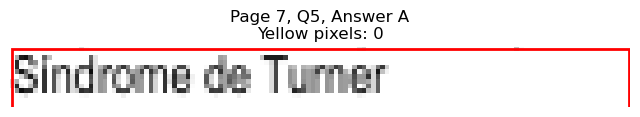

Page 7, Q5 - B: Detected box: x0=68.3, y0=480.8, x1=250.8, y1=493.4
Page 7, Q5, B: Yellow pixels: 0
Page 7, Q5, B: Total non-white pixels: 894
Page 7, Q5, B: Yellow percentage: 0.0%


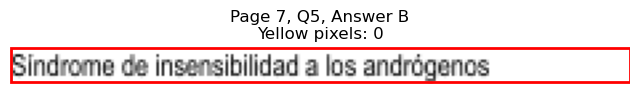

Page 7, Q5 - C: Detected box: x0=68.8, y0=493.4, x1=163.1, y1=506.0
Page 7, Q5, C: Yellow pixels: 0
Page 7, Q5, C: Total non-white pixels: 456
Page 7, Q5, C: Yellow percentage: 0.0%


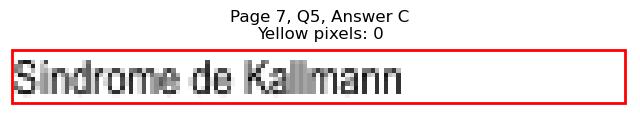

Page 7, Q5 - D: Detected box: x0=327.5, y0=468.1, x1=429.9, y1=480.7
Page 7, Q5, D: Yellow pixels: 1590
Page 7, Q5, D: Total non-white pixels: 1989
Page 7, Q5, D: Yellow percentage: 79.9%


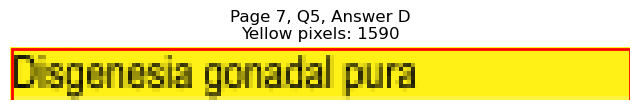

Page 7, Q5 - E: Detected box: x0=482.1, y0=480.8, x1=524.8, y1=493.4
Page 7, Q5, E: Yellow pixels: 58
Page 7, Q5, E: Total non-white pixels: 347
Page 7, Q5, E: Yellow percentage: 16.7%


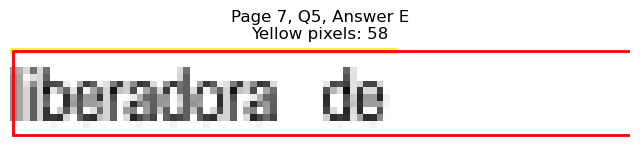


Page 7, Q5 - Selected Answer: D (based on yellow pixel count)




Page 7, Q6 - A: Detected box: x0=68.3, y0=543.8, x1=96.9, y1=556.4
Page 7, Q6, A: Yellow pixels: 916
Page 7, Q6, A: Total non-white pixels: 1106
Page 7, Q6, A: Yellow percentage: 82.8%


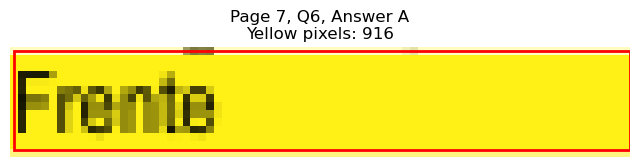

Page 7, Q6 - B: Detected box: x0=68.3, y0=556.5, x1=90.4, y1=569.2
Page 7, Q6, B: Yellow pixels: 73
Page 7, Q6, B: Total non-white pixels: 176
Page 7, Q6, B: Yellow percentage: 41.5%


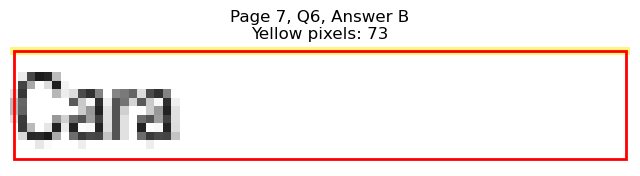

Page 7, Q6 - C: Detected box: x0=68.8, y0=569.1, x1=116.9, y1=581.8
Page 7, Q6, C: Yellow pixels: 0
Page 7, Q6, C: Total non-white pixels: 261
Page 7, Q6, C: Yellow percentage: 0.0%


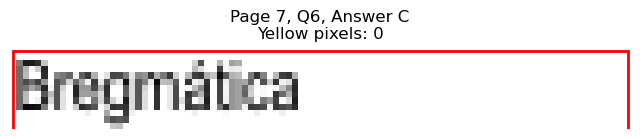

Page 7, Q6 - D: Detected box: x0=327.5, y0=543.8, x1=358.1, y1=556.4
Page 7, Q6, D: Yellow pixels: 0
Page 7, Q6, D: Total non-white pixels: 165
Page 7, Q6, D: Yellow percentage: 0.0%


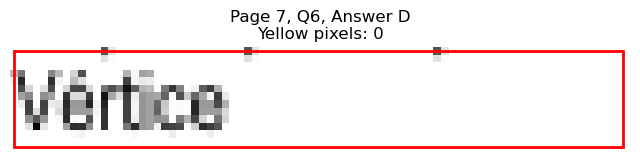

Page 7, Q6 - E: Detected box: x0=327.0, y0=556.5, x1=359.7, y1=569.2
Page 7, Q6, E: Yellow pixels: 0
Page 7, Q6, E: Total non-white pixels: 165
Page 7, Q6, E: Yellow percentage: 0.0%


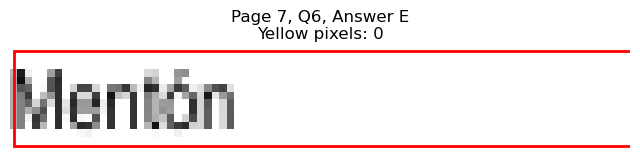


Page 7, Q6 - Selected Answer: A (based on yellow pixel count)




Page 7, Q7 - A: Detected box: x0=68.3, y0=606.9, x1=185.3, y1=619.6
Page 7, Q7, A: Yellow pixels: 0
Page 7, Q7, A: Total non-white pixels: 632
Page 7, Q7, A: Yellow percentage: 0.0%


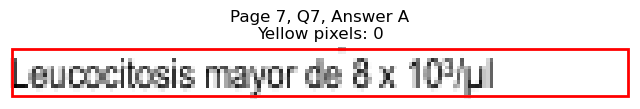

Page 7, Q7 - B: Detected box: x0=68.3, y0=619.6, x1=195.7, y1=632.3
Page 7, Q7, B: Yellow pixels: 0
Page 7, Q7, B: Total non-white pixels: 651
Page 7, Q7, B: Yellow percentage: 0.0%


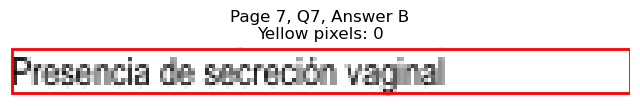

Page 7, Q7 - C: Detected box: x0=68.8, y0=632.2, x1=177.1, y1=644.9
Page 7, Q7, C: Yellow pixels: 0
Page 7, Q7, C: Total non-white pixels: 603
Page 7, Q7, C: Yellow percentage: 0.0%


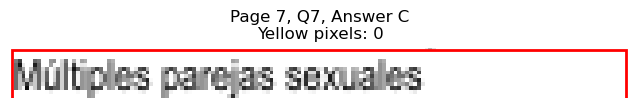

Page 7, Q7 - D: Detected box: x0=327.5, y0=606.9, x1=468.1, y1=619.6
Page 7, Q7, D: Yellow pixels: 0
Page 7, Q7, D: Total non-white pixels: 689
Page 7, Q7, D: Yellow percentage: 0.0%


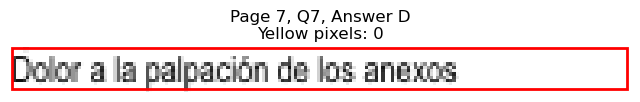

Page 7, Q7 - E: Detected box: x0=327.0, y0=619.6, x1=383.2, y1=632.3
Page 7, Q7, E: Yellow pixels: 1053
Page 7, Q7, E: Total non-white pixels: 1498
Page 7, Q7, E: Yellow percentage: 70.3%


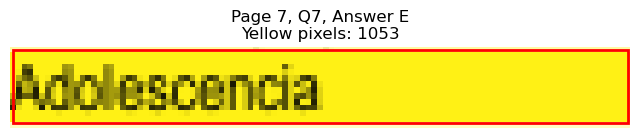


Page 7, Q7 - Selected Answer: E (based on yellow pixel count)




Page 7, Q8 - A: Detected box: x0=68.3, y0=708.0, x1=162.6, y1=720.6
Page 7, Q8, A: Yellow pixels: 0
Page 7, Q8, A: Total non-white pixels: 495
Page 7, Q8, A: Yellow percentage: 0.0%


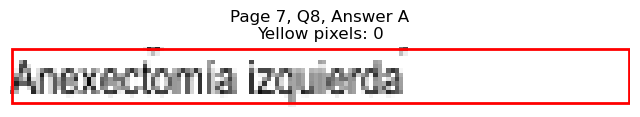

Page 7, Q8 - B: Detected box: x0=68.3, y0=720.6, x1=219.9, y1=733.2
Page 7, Q8, B: Yellow pixels: 202
Page 7, Q8, B: Total non-white pixels: 958
Page 7, Q8, B: Yellow percentage: 21.1%


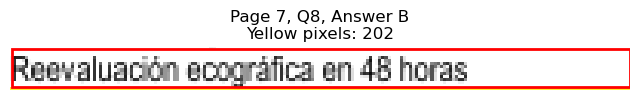

Page 7, Q8 - C: Detected box: x0=68.8, y0=733.2, x1=254.0, y1=745.8
Page 7, Q8, C: Yellow pixels: 2037
Page 7, Q8, C: Total non-white pixels: 2782
Page 7, Q8, C: Yellow percentage: 73.2%


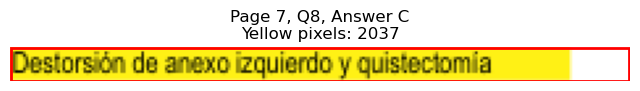

Page 7, Q8 - D: Detected box: x0=327.5, y0=708.0, x1=435.9, y1=720.6
Page 7, Q8, D: Yellow pixels: 0
Page 7, Q8, D: Total non-white pixels: 561
Page 7, Q8, D: Yellow percentage: 0.0%


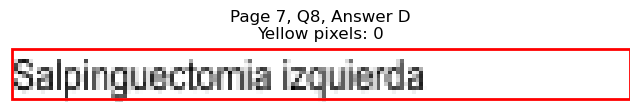

Page 7, Q8 - E: Detected box: x0=327.0, y0=720.6, x1=504.2, y1=733.2
Page 7, Q8, E: Yellow pixels: 0
Page 7, Q8, E: Total non-white pixels: 925
Page 7, Q8, E: Yellow percentage: 0.0%


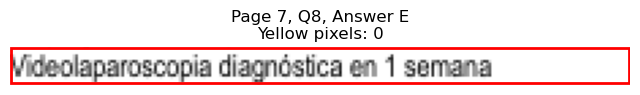


Page 7, Q8 - Selected Answer: C (based on yellow pixel count)





Page 8: Found 8 questions
Page 8, Q1 - A: Detected box: x0=68.3, y0=102.0, x1=140.1, y1=114.7
Page 8, Q1, A: Yellow pixels: 0
Page 8, Q1, A: Total non-white pixels: 352
Page 8, Q1, A: Yellow percentage: 0.0%


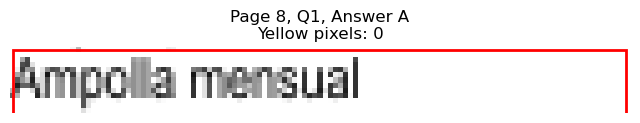

Page 8, Q1 - B: Detected box: x0=68.3, y0=114.6, x1=212.2, y1=127.3
Page 8, Q1, B: Yellow pixels: 195
Page 8, Q1, B: Total non-white pixels: 925
Page 8, Q1, B: Yellow percentage: 21.1%


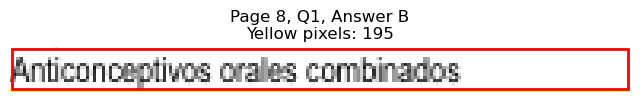

Page 8, Q1 - C: Detected box: x0=68.8, y0=127.2, x1=143.5, y1=139.9
Page 8, Q1, C: Yellow pixels: 1337
Page 8, Q1, C: Total non-white pixels: 1638
Page 8, Q1, C: Yellow percentage: 81.6%


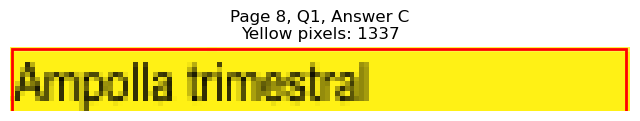

Page 8, Q1 - D: Detected box: x0=327.5, y0=102.0, x1=383.2, y1=114.7
Page 8, Q1, D: Yellow pixels: 0
Page 8, Q1, D: Total non-white pixels: 263
Page 8, Q1, D: Yellow percentage: 0.0%


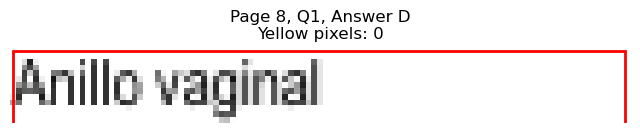

Page 8, Q1 - E: Detected box: x0=327.0, y0=114.6, x1=373.1, y1=127.3
Page 8, Q1, E: Yellow pixels: 0
Page 8, Q1, E: Total non-white pixels: 256
Page 8, Q1, E: Yellow percentage: 0.0%


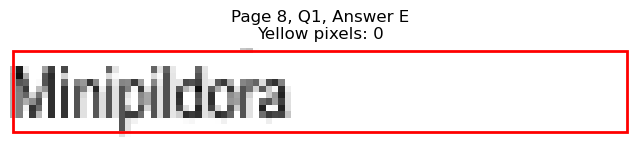


Page 8, Q1 - Selected Answer: C (based on yellow pixel count)




Page 8, Q2 - A: Detected box: x0=68.3, y0=190.3, x1=133.0, y1=203.0
Page 8, Q2, A: Yellow pixels: 0
Page 8, Q2, A: Total non-white pixels: 425
Page 8, Q2, A: Yellow percentage: 0.0%


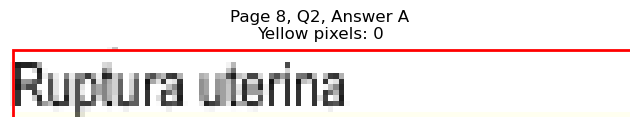

Page 8, Q2 - B: Detected box: x0=68.3, y0=202.9, x1=231.8, y1=215.6
Page 8, Q2, B: Yellow pixels: 2108
Page 8, Q2, B: Total non-white pixels: 2996
Page 8, Q2, B: Yellow percentage: 70.4%


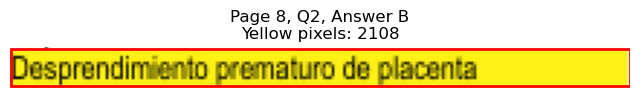

Page 8, Q2 - C: Detected box: x0=68.8, y0=215.7, x1=118.9, y1=228.3
Page 8, Q2, C: Yellow pixels: 101
Page 8, Q2, C: Total non-white pixels: 354
Page 8, Q2, C: Yellow percentage: 28.5%


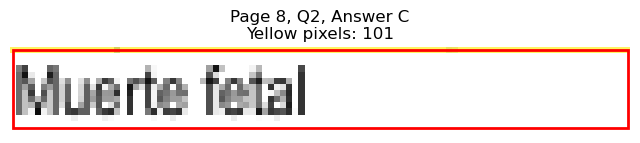

Page 8, Q2 - D: Detected box: x0=327.5, y0=190.3, x1=468.5, y1=203.0
Page 8, Q2, D: Yellow pixels: 0
Page 8, Q2, D: Total non-white pixels: 685
Page 8, Q2, D: Yellow percentage: 0.0%


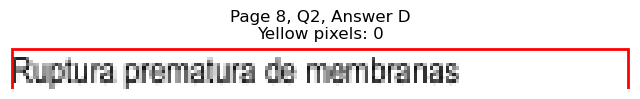

Page 8, Q2 - E: Detected box: x0=327.0, y0=202.9, x1=404.3, y1=215.6
Page 8, Q2, E: Yellow pixels: 0
Page 8, Q2, E: Total non-white pixels: 389
Page 8, Q2, E: Yellow percentage: 0.0%


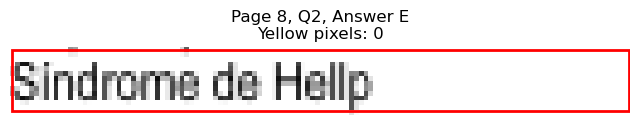


Page 8, Q2 - Selected Answer: B (based on yellow pixel count)




Page 8, Q3 - A: Detected box: x0=68.3, y0=266.1, x1=125.1, y1=278.7
Page 8, Q3, A: Yellow pixels: 0
Page 8, Q3, A: Total non-white pixels: 297
Page 8, Q3, A: Yellow percentage: 0.0%


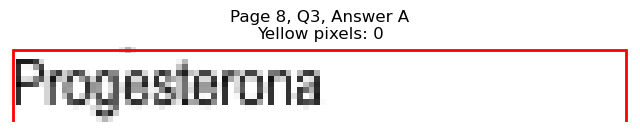

Page 8, Q3 - B: Detected box: x0=68.3, y0=278.8, x1=168.1, y1=291.5
Page 8, Q3, B: Yellow pixels: 1566
Page 8, Q3, B: Total non-white pixels: 2114
Page 8, Q3, B: Yellow percentage: 74.1%


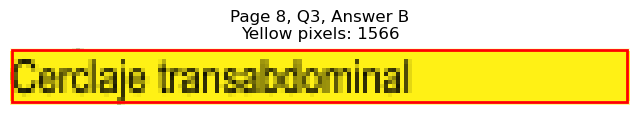

Page 8, Q3 - C: Detected box: x0=68.8, y0=291.4, x1=171.6, y1=304.1
Page 8, Q3, C: Yellow pixels: 153
Page 8, Q3, C: Total non-white pixels: 672
Page 8, Q3, C: Yellow percentage: 22.8%


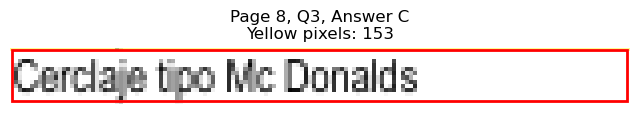

Page 8, Q3 - D: Detected box: x0=327.5, y0=266.1, x1=421.3, y1=278.7
Page 8, Q3, D: Yellow pixels: 0
Page 8, Q3, D: Total non-white pixels: 495
Page 8, Q3, D: Yellow percentage: 0.0%


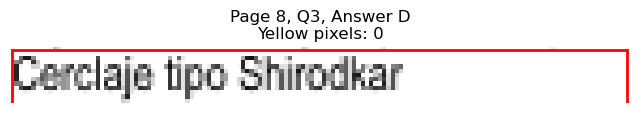

Page 8, Q3 - E: Detected box: x0=327.0, y0=278.8, x1=385.3, y1=291.5
Page 8, Q3, E: Yellow pixels: 0
Page 8, Q3, E: Total non-white pixels: 290
Page 8, Q3, E: Yellow percentage: 0.0%


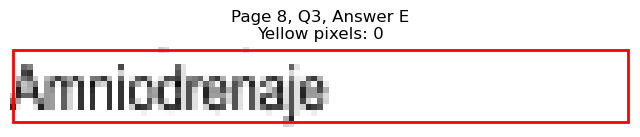


Page 8, Q3 - Selected Answer: B (based on yellow pixel count)




Page 8, Q4 - A: Detected box: x0=56.6, y0=354.5, x1=65.2, y1=367.2
Page 8, Q4, A: Yellow pixels: 0
Page 8, Q4, A: Total non-white pixels: 59
Page 8, Q4, A: Yellow percentage: 0.0%


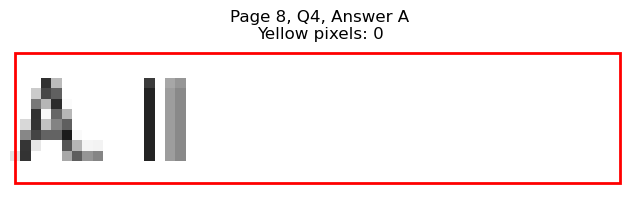

Page 8, Q4 - B: Detected box: x0=68.3, y0=367.1, x1=78.4, y1=379.8
Page 8, Q4, B: Yellow pixels: 0
Page 8, Q4, B: Total non-white pixels: 93
Page 8, Q4, B: Yellow percentage: 0.0%


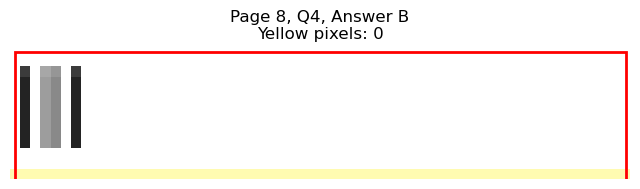

Page 8, Q4 - C: Detected box: x0=56.6, y0=379.7, x1=65.6, y1=392.4
Page 8, Q4, C: Yellow pixels: 678
Page 8, Q4, C: Total non-white pixels: 840
Page 8, Q4, C: Yellow percentage: 80.7%


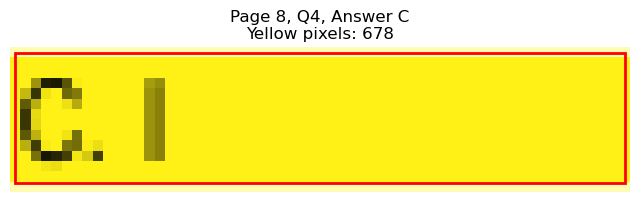

Page 8, Q4 - D: Detected box: x0=327.5, y0=354.5, x1=338.6, y1=367.2
Page 8, Q4, D: Yellow pixels: 0
Page 8, Q4, D: Total non-white pixels: 42
Page 8, Q4, D: Yellow percentage: 0.0%


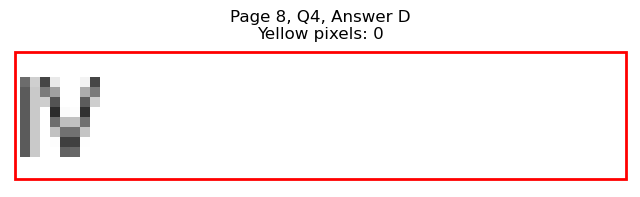

Page 8, Q4 - E: Detected box: x0=327.0, y0=367.1, x1=335.6, y1=379.8
Page 8, Q4, E: Yellow pixels: 0
Page 8, Q4, E: Total non-white pixels: 26
Page 8, Q4, E: Yellow percentage: 0.0%


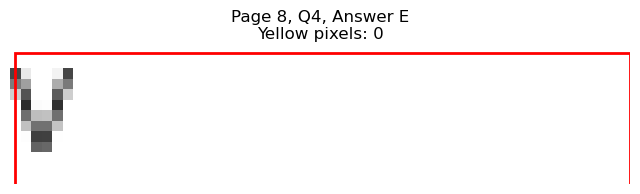


Page 8, Q4 - Selected Answer: C (based on yellow pixel count)




Page 8, Q5 - A: Detected box: x0=68.3, y0=442.8, x1=141.5, y1=455.5
Page 8, Q5, A: Yellow pixels: 0
Page 8, Q5, A: Total non-white pixels: 380
Page 8, Q5, A: Yellow percentage: 0.0%


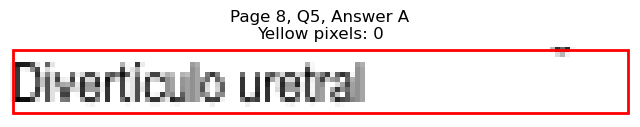

Page 8, Q5 - B: Detected box: x0=68.3, y0=455.5, x1=152.5, y1=468.1
Page 8, Q5, B: Yellow pixels: 0
Page 8, Q5, B: Total non-white pixels: 436
Page 8, Q5, B: Yellow percentage: 0.0%


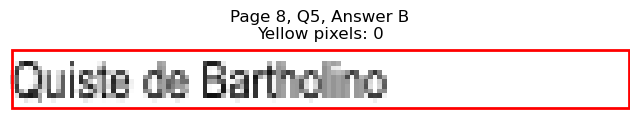

Page 8, Q5 - C: Detected box: x0=68.8, y0=468.1, x1=135.0, y1=480.7
Page 8, Q5, C: Yellow pixels: 0
Page 8, Q5, C: Total non-white pixels: 328
Page 8, Q5, C: Yellow percentage: 0.0%


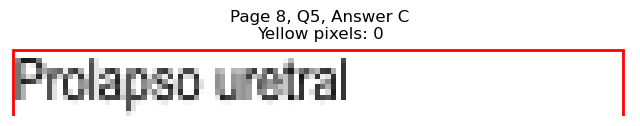

Page 8, Q5 - D: Detected box: x0=327.5, y0=442.8, x1=464.5, y1=455.5
Page 8, Q5, D: Yellow pixels: 188
Page 8, Q5, D: Total non-white pixels: 881
Page 8, Q5, D: Yellow percentage: 21.3%


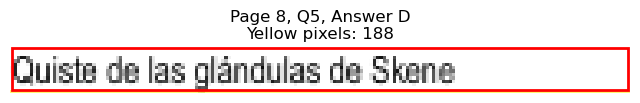

Page 8, Q5 - E: Detected box: x0=327.0, y0=455.5, x1=401.3, y1=468.1
Page 8, Q5, E: Yellow pixels: 1330
Page 8, Q5, E: Total non-white pixels: 1750
Page 8, Q5, E: Yellow percentage: 76.0%


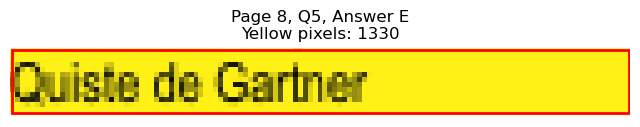


Page 8, Q5 - Selected Answer: E (based on yellow pixel count)




Page 8, Q6 - A: Detected box: x0=68.3, y0=518.6, x1=121.0, y1=531.2
Page 8, Q6, A: Yellow pixels: 0
Page 8, Q6, A: Total non-white pixels: 272
Page 8, Q6, A: Yellow percentage: 0.0%


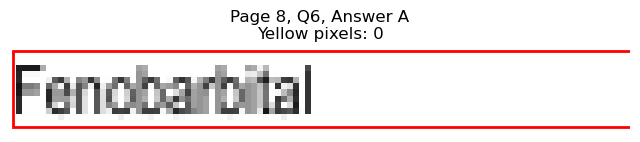

Page 8, Q6 - B: Detected box: x0=68.3, y0=531.2, x1=134.5, y1=543.8
Page 8, Q6, B: Yellow pixels: 0
Page 8, Q6, B: Total non-white pixels: 339
Page 8, Q6, B: Yellow percentage: 0.0%


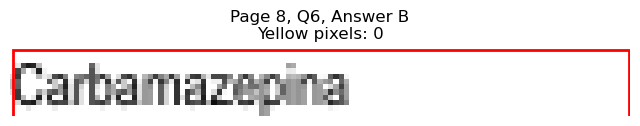

Page 8, Q6 - C: Detected box: x0=68.8, y0=543.8, x1=108.4, y1=556.4
Page 8, Q6, C: Yellow pixels: 0
Page 8, Q6, C: Total non-white pixels: 208
Page 8, Q6, C: Yellow percentage: 0.0%


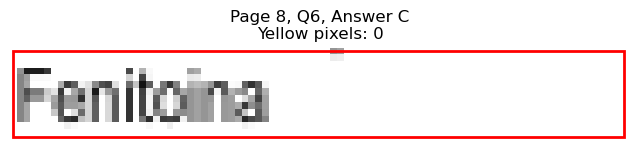

Page 8, Q6 - D: Detected box: x0=327.5, y0=518.6, x1=381.8, y1=531.2
Page 8, Q6, D: Yellow pixels: 105
Page 8, Q6, D: Total non-white pixels: 395
Page 8, Q6, D: Yellow percentage: 26.6%


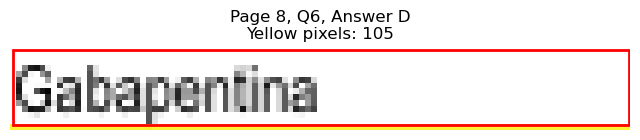

Page 8, Q6 - E: Detected box: x0=327.0, y0=531.2, x1=390.8, y1=543.8
Page 8, Q6, E: Yellow pixels: 1246
Page 8, Q6, E: Total non-white pixels: 1482
Page 8, Q6, E: Yellow percentage: 84.1%


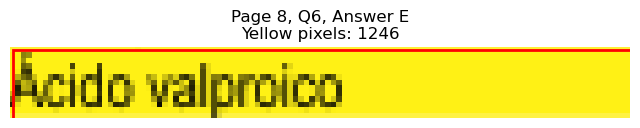


Page 8, Q6 - Selected Answer: E (based on yellow pixel count)




Page 8, Q7 - A: Detected box: x0=56.6, y0=594.3, x1=65.2, y1=607.0
Page 8, Q7, A: Yellow pixels: 0
Page 8, Q7, A: Total non-white pixels: 44
Page 8, Q7, A: Yellow percentage: 0.0%


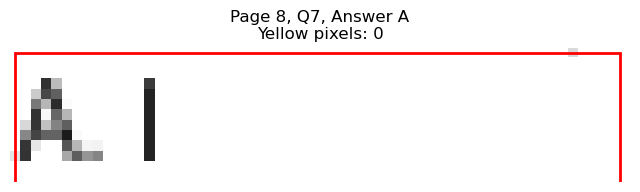

Page 8, Q7 - B: Detected box: x0=68.3, y0=367.1, x1=78.4, y1=379.8
Page 8, Q7, B: Yellow pixels: 0
Page 8, Q7, B: Total non-white pixels: 93
Page 8, Q7, B: Yellow percentage: 0.0%


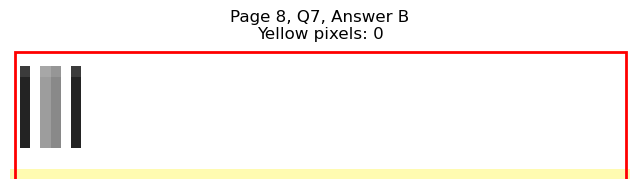

Page 8, Q7 - C: Detected box: x0=56.6, y0=619.6, x1=65.6, y1=632.3
Page 8, Q7, C: Yellow pixels: 670
Page 8, Q7, C: Total non-white pixels: 840
Page 8, Q7, C: Yellow percentage: 79.8%


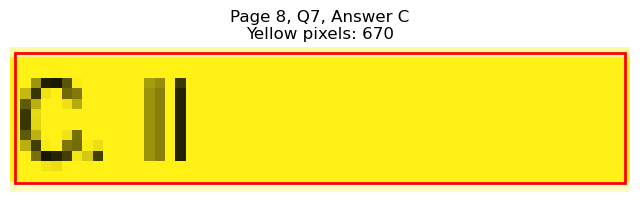

Page 8, Q7 - D: Detected box: x0=327.5, y0=354.5, x1=338.6, y1=367.2
Page 8, Q7, D: Yellow pixels: 0
Page 8, Q7, D: Total non-white pixels: 42
Page 8, Q7, D: Yellow percentage: 0.0%


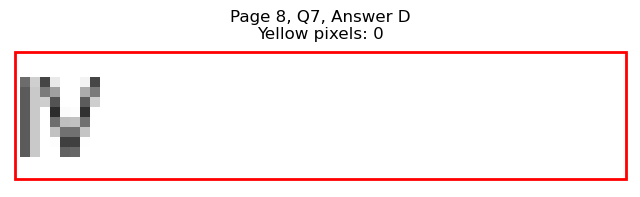

Page 8, Q7 - E: Detected box: x0=327.0, y0=367.1, x1=335.6, y1=379.8
Page 8, Q7, E: Yellow pixels: 0
Page 8, Q7, E: Total non-white pixels: 26
Page 8, Q7, E: Yellow percentage: 0.0%


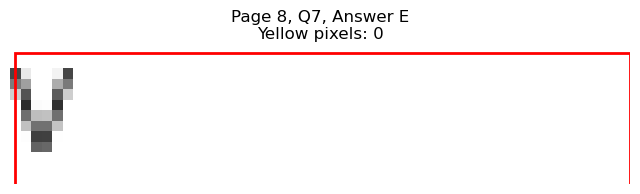


Page 8, Q7 - Selected Answer: C (based on yellow pixel count)




Page 8, Q8 - A: Detected box: x0=68.3, y0=670.1, x1=131.5, y1=682.7
Page 8, Q8, A: Yellow pixels: 0
Page 8, Q8, A: Total non-white pixels: 319
Page 8, Q8, A: Yellow percentage: 0.0%


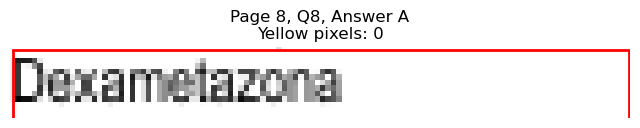

Page 8, Q8 - B: Detected box: x0=68.3, y0=682.7, x1=126.5, y1=695.3
Page 8, Q8, B: Yellow pixels: 0
Page 8, Q8, B: Total non-white pixels: 298
Page 8, Q8, B: Yellow percentage: 0.0%


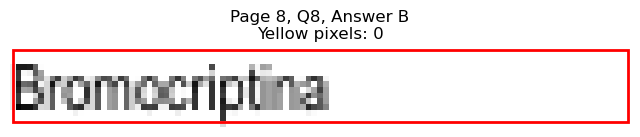

Page 8, Q8 - C: Detected box: x0=68.8, y0=695.4, x1=116.4, y1=708.0
Page 8, Q8, C: Yellow pixels: 0
Page 8, Q8, C: Total non-white pixels: 250
Page 8, Q8, C: Yellow percentage: 0.0%


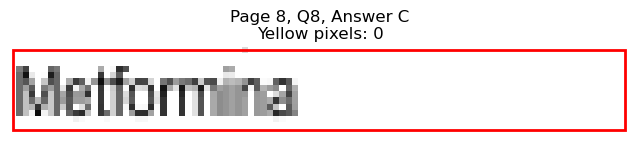

Page 8, Q8 - D: Detected box: x0=327.5, y0=670.1, x1=410.3, y1=682.7
Page 8, Q8, D: Yellow pixels: 1439
Page 8, Q8, D: Total non-white pixels: 1742
Page 8, Q8, D: Yellow percentage: 82.6%


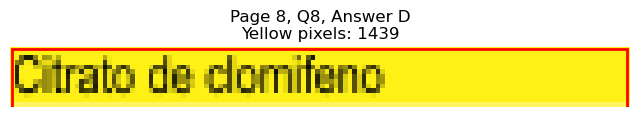

Page 8, Q8 - E: Detected box: x0=327.0, y0=682.7, x1=465.0, y1=695.3
Page 8, Q8, E: Yellow pixels: 188
Page 8, Q8, E: Total non-white pixels: 933
Page 8, Q8, E: Yellow percentage: 20.2%


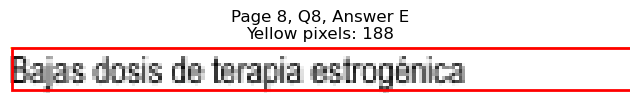


Page 8, Q8 - Selected Answer: D (based on yellow pixel count)





Page 9: Found 7 questions
Page 9, Q1 - A: Detected box: x0=68.3, y0=127.2, x1=138.5, y1=139.9
Page 9, Q1, A: Yellow pixels: 0
Page 9, Q1, A: Total non-white pixels: 351
Page 9, Q1, A: Yellow percentage: 0.0%


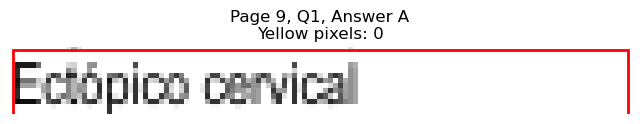

Page 9, Q1 - B: Detected box: x0=68.3, y0=139.9, x1=134.5, y1=152.6
Page 9, Q1, B: Yellow pixels: 0
Page 9, Q1, B: Total non-white pixels: 292
Page 9, Q1, B: Yellow percentage: 0.0%


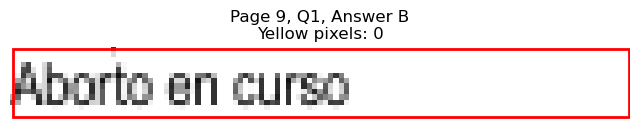

Page 9, Q1 - C: Detected box: x0=68.8, y0=152.5, x1=181.1, y1=165.2
Page 9, Q1, C: Yellow pixels: 0
Page 9, Q1, C: Total non-white pixels: 551
Page 9, Q1, C: Yellow percentage: 0.0%


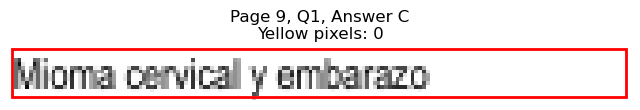

Page 9, Q1 - D: Detected box: x0=327.5, y0=127.2, x1=461.5, y1=139.9
Page 9, Q1, D: Yellow pixels: 1888
Page 9, Q1, D: Total non-white pixels: 2405
Page 9, Q1, D: Yellow percentage: 78.5%


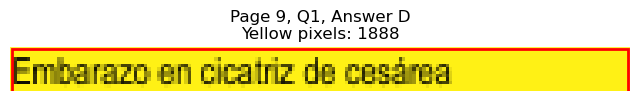

Page 9, Q1 - E: Detected box: x0=327.0, y0=139.9, x1=408.3, y1=152.6
Page 9, Q1, E: Yellow pixels: 132
Page 9, Q1, E: Total non-white pixels: 501
Page 9, Q1, E: Yellow percentage: 26.3%


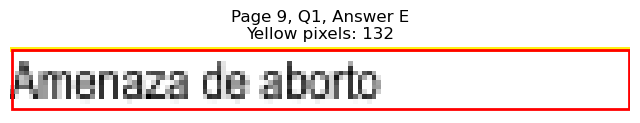


Page 9, Q1 - Selected Answer: D (based on yellow pixel count)




Page 9, Q2 - A: Detected box: x0=68.3, y0=215.7, x1=134.1, y1=228.3
Page 9, Q2, A: Yellow pixels: 0
Page 9, Q2, A: Total non-white pixels: 313
Page 9, Q2, A: Yellow percentage: 0.0%


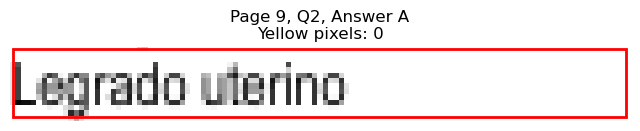

Page 9, Q2 - B: Detected box: x0=68.3, y0=228.3, x1=161.1, y1=240.9
Page 9, Q2, B: Yellow pixels: 0
Page 9, Q2, B: Total non-white pixels: 451
Page 9, Q2, B: Yellow percentage: 0.0%


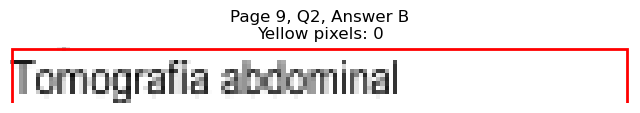

Page 9, Q2 - C: Detected box: x0=68.8, y0=240.9, x1=127.9, y1=253.5
Page 9, Q2, C: Yellow pixels: 0
Page 9, Q2, C: Total non-white pixels: 328
Page 9, Q2, C: Yellow percentage: 0.0%


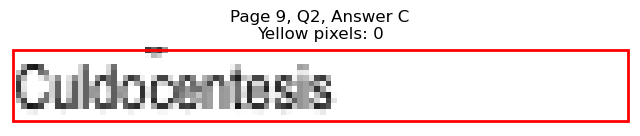

Page 9, Q2 - D: Detected box: x0=327.5, y0=215.7, x1=455.5, y1=228.3
Page 9, Q2, D: Yellow pixels: 179
Page 9, Q2, D: Total non-white pixels: 830
Page 9, Q2, D: Yellow percentage: 21.6%


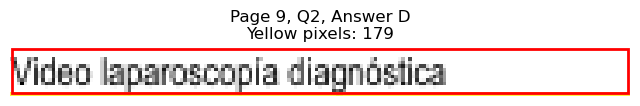

Page 9, Q2 - E: Detected box: x0=327.0, y0=228.3, x1=431.5, y1=240.9
Page 9, Q2, E: Yellow pixels: 1597
Page 9, Q2, E: Total non-white pixels: 2015
Page 9, Q2, E: Yellow percentage: 79.3%


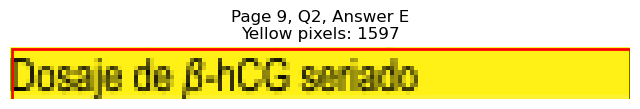


Page 9, Q2 - Selected Answer: E (based on yellow pixel count)




Page 9, Q3 - A: Detected box: x0=68.3, y0=316.6, x1=118.6, y1=329.3
Page 9, Q3, A: Yellow pixels: 1010
Page 9, Q3, A: Total non-white pixels: 1414
Page 9, Q3, A: Yellow percentage: 71.4%


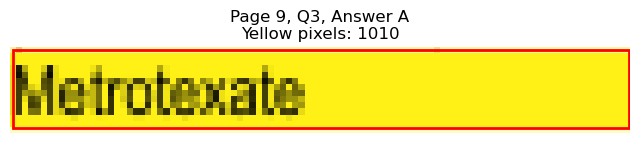

Page 9, Q3 - B: Detected box: x0=68.3, y0=329.2, x1=191.2, y1=341.9
Page 9, Q3, B: Yellow pixels: 0
Page 9, Q3, B: Total non-white pixels: 830
Page 9, Q3, B: Yellow percentage: 0.0%


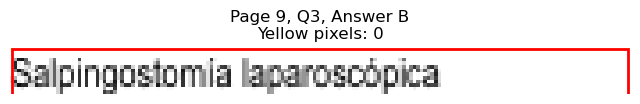

Page 9, Q3 - C: Detected box: x0=68.8, y0=341.9, x1=196.7, y1=354.6
Page 9, Q3, C: Yellow pixels: 0
Page 9, Q3, C: Total non-white pixels: 694
Page 9, Q3, C: Yellow percentage: 0.0%


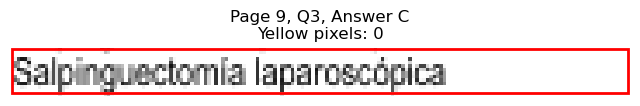

Page 9, Q3 - D: Detected box: x0=327.5, y0=316.6, x1=412.9, y1=329.3
Page 9, Q3, D: Yellow pixels: 0
Page 9, Q3, D: Total non-white pixels: 446
Page 9, Q3, D: Yellow percentage: 0.0%


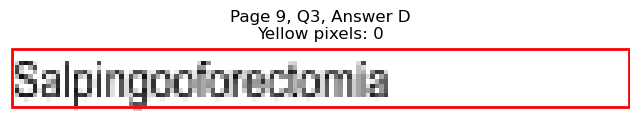

Page 9, Q3 - E: Detected box: x0=327.0, y0=329.2, x1=429.9, y1=341.9
Page 9, Q3, E: Yellow pixels: 0
Page 9, Q3, E: Total non-white pixels: 508
Page 9, Q3, E: Yellow percentage: 0.0%


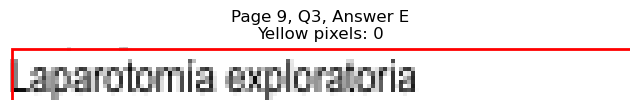


Page 9, Q3 - Selected Answer: A (based on yellow pixel count)




Page 9, Q4 - A: Detected box: x0=68.3, y0=379.7, x1=92.9, y1=392.4
Page 9, Q4, A: Yellow pixels: 0
Page 9, Q4, A: Total non-white pixels: 113
Page 9, Q4, A: Yellow percentage: 0.0%


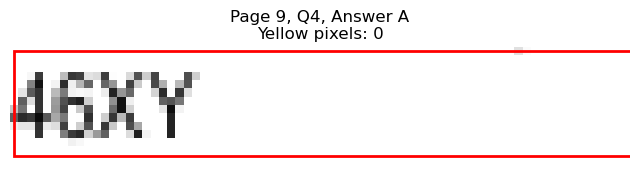

Page 9, Q4 - B: Detected box: x0=68.3, y0=392.3, x1=92.9, y1=405.0
Page 9, Q4, B: Yellow pixels: 0
Page 9, Q4, B: Total non-white pixels: 105
Page 9, Q4, B: Yellow percentage: 0.0%


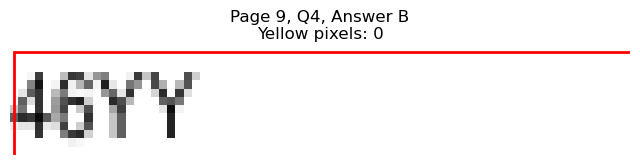

Page 9, Q4 - C: Detected box: x0=68.8, y0=404.9, x1=101.9, y1=417.6
Page 9, Q4, C: Yellow pixels: 0
Page 9, Q4, C: Total non-white pixels: 149
Page 9, Q4, C: Yellow percentage: 0.0%


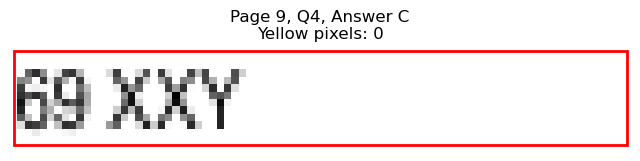

Page 9, Q4 - D: Detected box: x0=327.5, y0=379.7, x1=358.1, y1=392.4
Page 9, Q4, D: Yellow pixels: 82
Page 9, Q4, D: Total non-white pixels: 229
Page 9, Q4, D: Yellow percentage: 35.8%


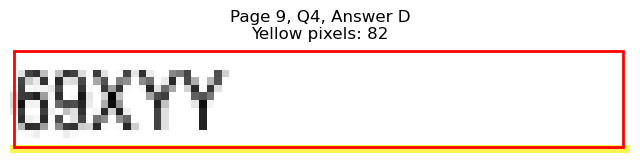

Page 9, Q4 - E: Detected box: x0=327.0, y0=392.3, x1=351.7, y1=405.0
Page 9, Q4, E: Yellow pixels: 877
Page 9, Q4, E: Total non-white pixels: 975
Page 9, Q4, E: Yellow percentage: 89.9%


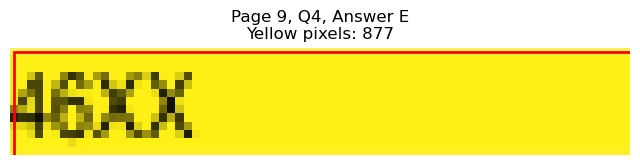


Page 9, Q4 - Selected Answer: E (based on yellow pixel count)




Page 9, Q5 - A: Detected box: x0=68.3, y0=480.8, x1=282.3, y1=493.4
Page 9, Q5, A: Yellow pixels: 0
Page 9, Q5, A: Total non-white pixels: 986
Page 9, Q5, A: Yellow percentage: 0.0%


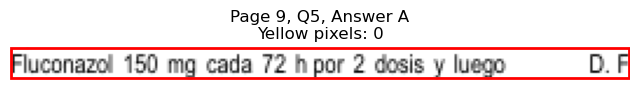

Page 9, Q5 - B: Detected box: x0=68.3, y0=506.0, x1=282.3, y1=518.6
Page 9, Q5, B: Yellow pixels: 0
Page 9, Q5, B: Total non-white pixels: 1134
Page 9, Q5, B: Yellow percentage: 0.0%


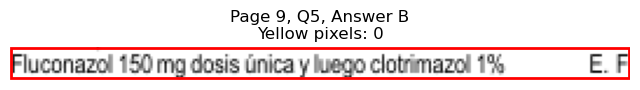

Page 9, Q5 - C: Detected box: x0=68.8, y0=531.2, x1=282.3, y1=543.8
Page 9, Q5, C: Yellow pixels: 2017
Page 9, Q5, C: Total non-white pixels: 2782
Page 9, Q5, C: Yellow percentage: 72.5%


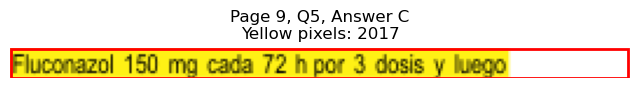

Page 9, Q5 - D: Detected box: x0=327.5, y0=480.8, x1=541.0, y1=493.4
Page 9, Q5, D: Yellow pixels: 0
Page 9, Q5, D: Total non-white pixels: 1026
Page 9, Q5, D: Yellow percentage: 0.0%


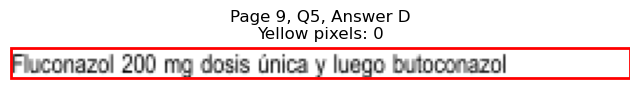

Page 9, Q5 - E: Detected box: x0=327.0, y0=506.0, x1=541.1, y1=518.6
Page 9, Q5, E: Yellow pixels: 0
Page 9, Q5, E: Total non-white pixels: 1085
Page 9, Q5, E: Yellow percentage: 0.0%


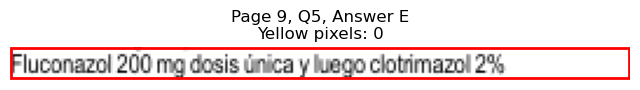


Page 9, Q5 - Selected Answer: C (based on yellow pixel count)




Page 9, Q6 - A: Detected box: x0=56.6, y0=606.9, x1=65.2, y1=619.6
Page 9, Q6, A: Yellow pixels: 0
Page 9, Q6, A: Total non-white pixels: 71
Page 9, Q6, A: Yellow percentage: 0.0%


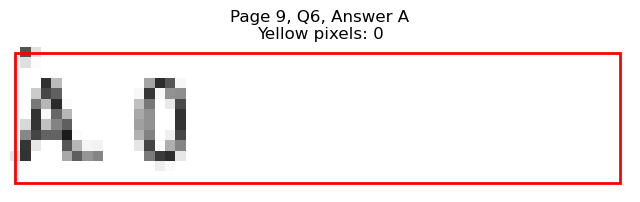

Page 9, Q6 - B: Detected box: x0=56.6, y0=619.6, x1=65.2, y1=632.3
Page 9, Q6, B: Yellow pixels: 0
Page 9, Q6, B: Total non-white pixels: 50
Page 9, Q6, B: Yellow percentage: 0.0%


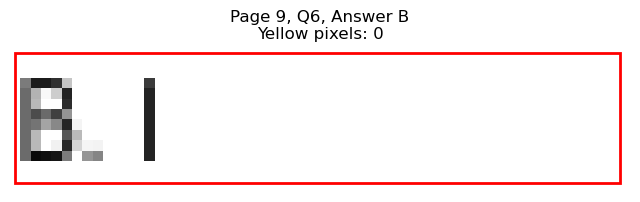

Page 9, Q6 - C: Detected box: x0=68.8, y0=632.2, x1=78.9, y1=644.9
Page 9, Q6, C: Yellow pixels: 0
Page 9, Q6, C: Total non-white pixels: 40
Page 9, Q6, C: Yellow percentage: 0.0%


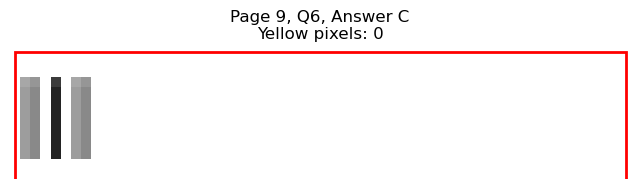

Page 9, Q6 - D: Detected box: x0=315.4, y0=606.9, x1=324.4, y1=619.6
Page 9, Q6, D: Yellow pixels: 726
Page 9, Q6, D: Total non-white pixels: 840
Page 9, Q6, D: Yellow percentage: 86.4%


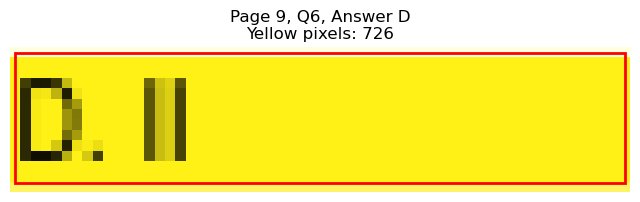

Page 9, Q6 - E: Detected box: x0=327.0, y0=619.6, x1=338.1, y1=632.3
Page 9, Q6, E: Yellow pixels: 62
Page 9, Q6, E: Total non-white pixels: 107
Page 9, Q6, E: Yellow percentage: 57.9%


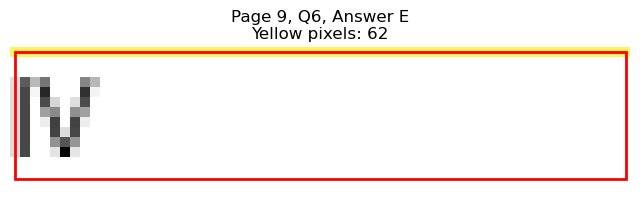


Page 9, Q6 - Selected Answer: D (based on yellow pixel count)




Page 9, Q7 - A: Detected box: x0=68.3, y0=682.7, x1=188.7, y1=695.3
Page 9, Q7, A: Yellow pixels: 0
Page 9, Q7, A: Total non-white pixels: 637
Page 9, Q7, A: Yellow percentage: 0.0%


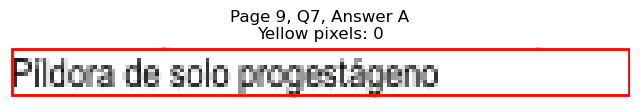

Page 9, Q7 - B: Detected box: x0=68.3, y0=695.4, x1=151.1, y1=708.0
Page 9, Q7, B: Yellow pixels: 134
Page 9, Q7, B: Total non-white pixels: 685
Page 9, Q7, B: Yellow percentage: 19.6%


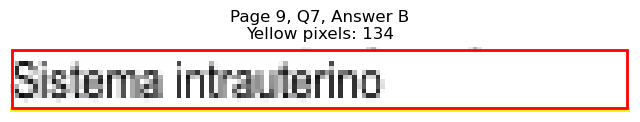

Page 9, Q7 - C: Detected box: x0=68.8, y0=708.0, x1=157.1, y1=720.6
Page 9, Q7, C: Yellow pixels: 1471
Page 9, Q7, C: Total non-white pixels: 1960
Page 9, Q7, C: Yellow percentage: 75.1%


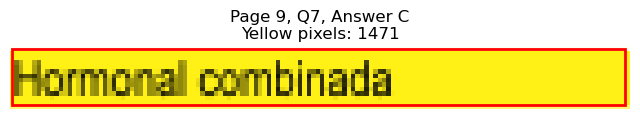

Page 9, Q7 - D: Detected box: x0=327.5, y0=682.7, x1=436.4, y1=695.3
Page 9, Q7, D: Yellow pixels: 0
Page 9, Q7, D: Total non-white pixels: 560
Page 9, Q7, D: Yellow percentage: 0.0%


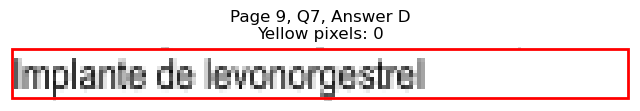

Page 9, Q7 - E: Detected box: x0=327.0, y0=695.4, x1=382.7, y1=708.0
Page 9, Q7, E: Yellow pixels: 0
Page 9, Q7, E: Total non-white pixels: 268
Page 9, Q7, E: Yellow percentage: 0.0%


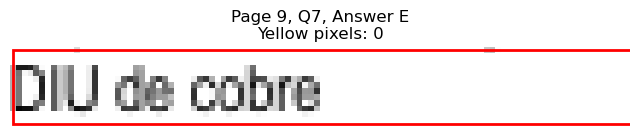


Page 9, Q7 - Selected Answer: C (based on yellow pixel count)





Page 10: Found 9 questions
Page 10, Q1 - A: Detected box: x0=68.3, y0=114.6, x1=167.1, y1=127.3
Page 10, Q1, A: Yellow pixels: 150
Page 10, Q1, A: Total non-white pixels: 649
Page 10, Q1, A: Yellow percentage: 23.1%


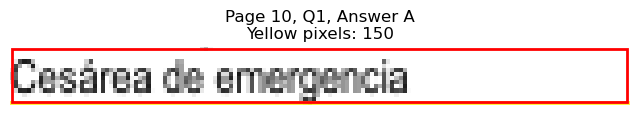

Page 10, Q1 - B: Detected box: x0=68.3, y0=127.2, x1=156.0, y1=139.9
Page 10, Q1, B: Yellow pixels: 1461
Page 10, Q1, B: Total non-white pixels: 1807
Page 10, Q1, B: Yellow percentage: 80.9%


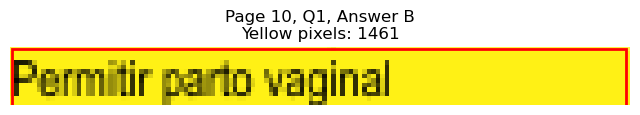

Page 10, Q1 - C: Detected box: x0=68.8, y0=139.9, x1=199.7, y1=152.6
Page 10, Q1, C: Yellow pixels: 176
Page 10, Q1, C: Total non-white pixels: 864
Page 10, Q1, C: Yellow percentage: 20.4%


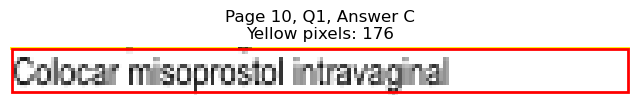

Page 10, Q1 - D: Detected box: x0=327.5, y0=114.6, x1=421.3, y1=127.3
Page 10, Q1, D: Yellow pixels: 0
Page 10, Q1, D: Total non-white pixels: 500
Page 10, Q1, D: Yellow percentage: 0.0%


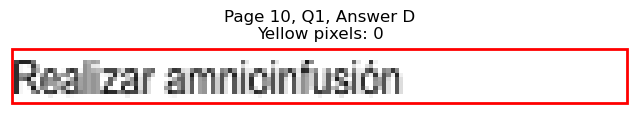

Page 10, Q1 - E: Detected box: x0=327.0, y0=127.2, x1=512.3, y1=139.9
Page 10, Q1, E: Yellow pixels: 0
Page 10, Q1, E: Total non-white pixels: 937
Page 10, Q1, E: Yellow percentage: 0.0%


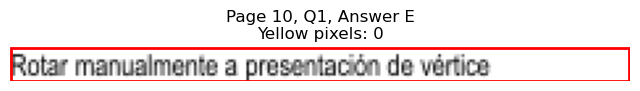


Page 10, Q1 - Selected Answer: B (based on yellow pixel count)




Page 10, Q2 - A: Detected box: x0=68.3, y0=177.7, x1=130.5, y1=190.4
Page 10, Q2, A: Yellow pixels: 113
Page 10, Q2, A: Total non-white pixels: 443
Page 10, Q2, A: Yellow percentage: 25.5%


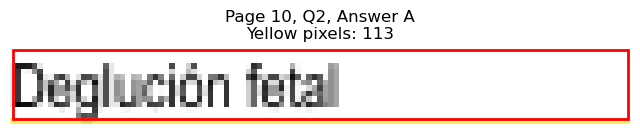

Page 10, Q2 - B: Detected box: x0=68.3, y0=190.3, x1=121.0, y1=203.0
Page 10, Q2, B: Yellow pixels: 1128
Page 10, Q2, B: Total non-white pixels: 1339
Page 10, Q2, B: Yellow percentage: 84.2%


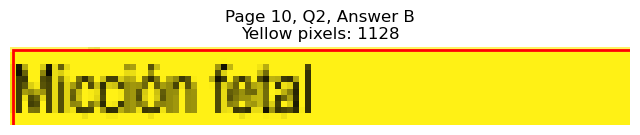

Page 10, Q2 - C: Detected box: x0=68.8, y0=202.9, x1=171.1, y1=215.6
Page 10, Q2, C: Yellow pixels: 154
Page 10, Q2, C: Total non-white pixels: 663
Page 10, Q2, C: Yellow percentage: 23.2%


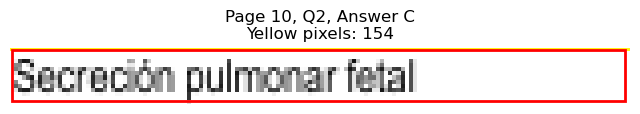

Page 10, Q2 - D: Detected box: x0=327.5, y0=177.7, x1=493.1, y1=190.4
Page 10, Q2, D: Yellow pixels: 0
Page 10, Q2, D: Total non-white pixels: 791
Page 10, Q2, D: Yellow percentage: 0.0%


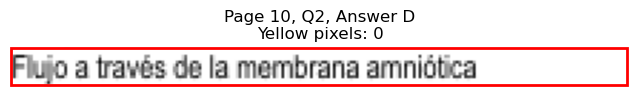

Page 10, Q2 - E: Detected box: x0=327.0, y0=190.3, x1=487.5, y1=203.0
Page 10, Q2, E: Yellow pixels: 0
Page 10, Q2, E: Total non-white pixels: 753
Page 10, Q2, E: Yellow percentage: 0.0%


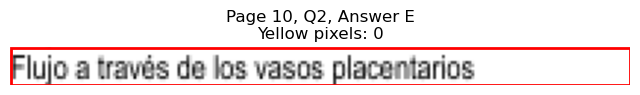


Page 10, Q2 - Selected Answer: B (based on yellow pixel count)




Page 10, Q3 - A: Detected box: x0=68.3, y0=253.5, x1=141.0, y1=266.1
Page 10, Q3, A: Yellow pixels: 0
Page 10, Q3, A: Total non-white pixels: 338
Page 10, Q3, A: Yellow percentage: 0.0%


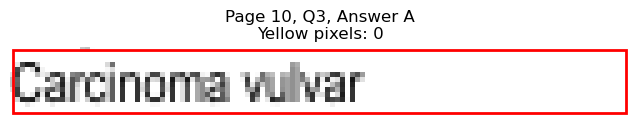

Page 10, Q3 - B: Detected box: x0=68.3, y0=266.1, x1=133.9, y1=278.7
Page 10, Q3, B: Yellow pixels: 0
Page 10, Q3, B: Total non-white pixels: 370
Page 10, Q3, B: Yellow percentage: 0.0%


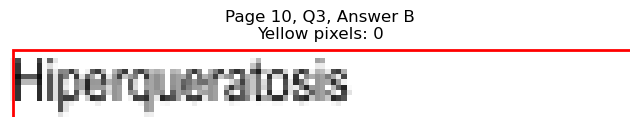

Page 10, Q3 - C: Detected box: x0=68.8, y0=278.8, x1=124.9, y1=291.5
Page 10, Q3, C: Yellow pixels: 0
Page 10, Q3, C: Total non-white pixels: 265
Page 10, Q3, C: Yellow percentage: 0.0%


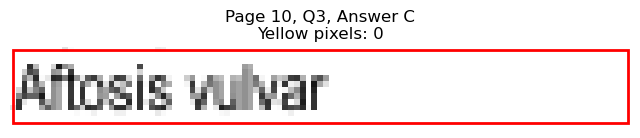

Page 10, Q3 - D: Detected box: x0=327.5, y0=253.5, x1=418.3, y1=266.1
Page 10, Q3, D: Yellow pixels: 142
Page 10, Q3, D: Total non-white pixels: 615
Page 10, Q3, D: Yellow percentage: 23.1%


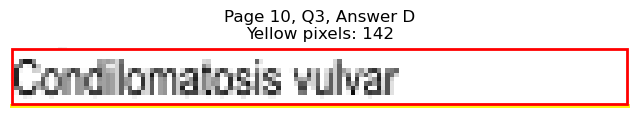

Page 10, Q3 - E: Detected box: x0=327.0, y0=266.1, x1=397.7, y1=278.7
Page 10, Q3, E: Yellow pixels: 1294
Page 10, Q3, E: Total non-white pixels: 1573
Page 10, Q3, E: Yellow percentage: 82.3%


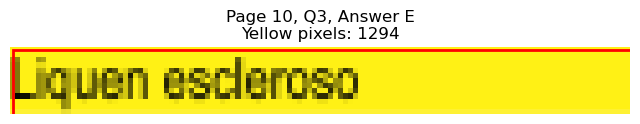


Page 10, Q3 - Selected Answer: E (based on yellow pixel count)




Page 10, Q4 - A: Detected box: x0=68.3, y0=329.2, x1=232.8, y1=341.9
Page 10, Q4, A: Yellow pixels: 0
Page 10, Q4, A: Total non-white pixels: 803
Page 10, Q4, A: Yellow percentage: 0.0%


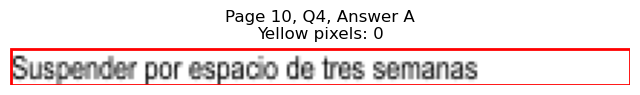

Page 10, Q4 - B: Detected box: x0=68.3, y0=341.9, x1=236.3, y1=354.6
Page 10, Q4, B: Yellow pixels: 0
Page 10, Q4, B: Total non-white pixels: 835
Page 10, Q4, B: Yellow percentage: 0.0%


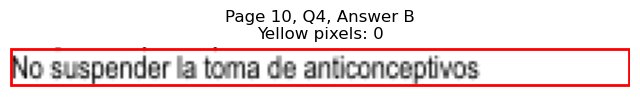

Page 10, Q4 - C: Detected box: x0=68.8, y0=354.5, x1=213.6, y1=367.2
Page 10, Q4, C: Yellow pixels: 0
Page 10, Q4, C: Total non-white pixels: 718
Page 10, Q4, C: Yellow percentage: 0.0%


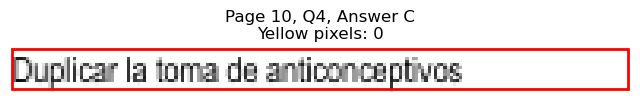

Page 10, Q4 - D: Detected box: x0=327.5, y0=329.2, x1=502.2, y1=341.9
Page 10, Q4, D: Yellow pixels: 2080
Page 10, Q4, D: Total non-white pixels: 2782
Page 10, Q4, D: Yellow percentage: 74.8%


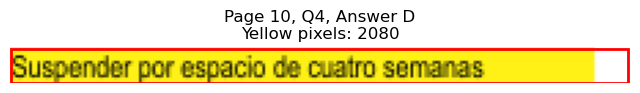

Page 10, Q4 - E: Detected box: x0=327.0, y0=341.9, x1=449.9, y1=354.6
Page 10, Q4, E: Yellow pixels: 169
Page 10, Q4, E: Total non-white pixels: 787
Page 10, Q4, E: Yellow percentage: 21.5%


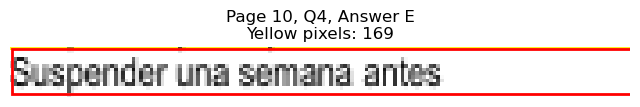


Page 10, Q4 - Selected Answer: D (based on yellow pixel count)




Page 10, Q5 - A: Detected box: x0=68.3, y0=404.9, x1=167.1, y1=417.6
Page 10, Q5, A: Yellow pixels: 0
Page 10, Q5, A: Total non-white pixels: 525
Page 10, Q5, A: Yellow percentage: 0.0%


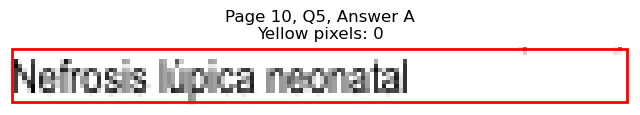

Page 10, Q5 - B: Detected box: x0=68.3, y0=417.6, x1=247.8, y1=430.3
Page 10, Q5, B: Yellow pixels: 1888
Page 10, Q5, B: Total non-white pixels: 2996
Page 10, Q5, B: Yellow percentage: 63.0%


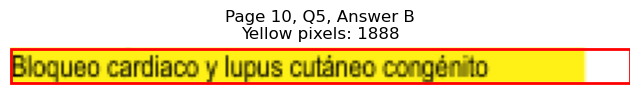

Page 10, Q5 - C: Detected box: x0=68.8, y0=430.2, x1=140.5, y1=442.9
Page 10, Q5, C: Yellow pixels: 0
Page 10, Q5, C: Total non-white pixels: 500
Page 10, Q5, C: Yellow percentage: 0.0%


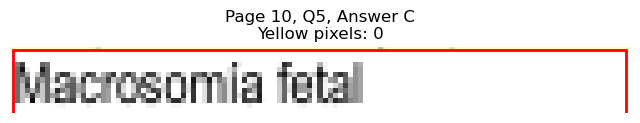

Page 10, Q5 - D: Detected box: x0=327.5, y0=404.9, x1=397.7, y1=417.6
Page 10, Q5, D: Yellow pixels: 0
Page 10, Q5, D: Total non-white pixels: 391
Page 10, Q5, D: Yellow percentage: 0.0%


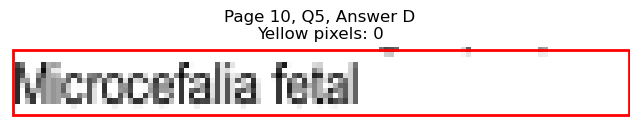

Page 10, Q5 - E: Detected box: x0=327.0, y0=417.6, x1=401.9, y1=430.3
Page 10, Q5, E: Yellow pixels: 0
Page 10, Q5, E: Total non-white pixels: 405
Page 10, Q5, E: Yellow percentage: 0.0%


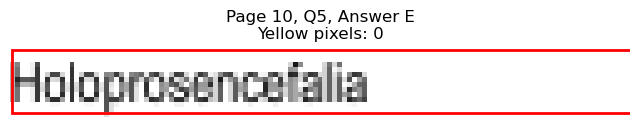


Page 10, Q5 - Selected Answer: B (based on yellow pixel count)




Page 10, Q6 - A: Detected box: x0=68.3, y0=468.1, x1=183.1, y1=480.7
Page 10, Q6, A: Yellow pixels: 0
Page 10, Q6, A: Total non-white pixels: 545
Page 10, Q6, A: Yellow percentage: 0.0%


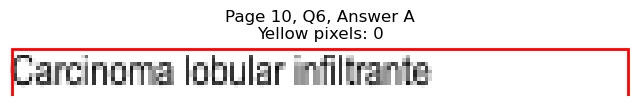

Page 10, Q6 - B: Detected box: x0=68.3, y0=480.8, x1=158.5, y1=493.4
Page 10, Q6, B: Yellow pixels: 0
Page 10, Q6, B: Total non-white pixels: 453
Page 10, Q6, B: Yellow percentage: 0.0%


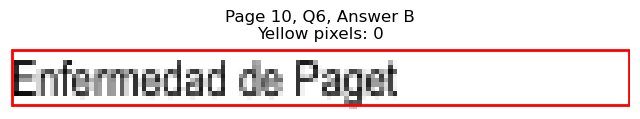

Page 10, Q6 - C: Detected box: x0=68.8, y0=493.4, x1=157.1, y1=506.0
Page 10, Q6, C: Yellow pixels: 0
Page 10, Q6, C: Total non-white pixels: 410
Page 10, Q6, C: Yellow percentage: 0.0%


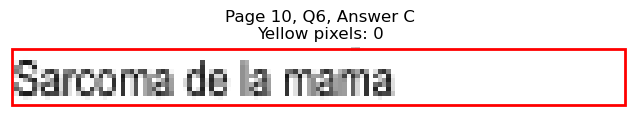

Page 10, Q6 - D: Detected box: x0=327.5, y0=468.1, x1=445.9, y1=480.7
Page 10, Q6, D: Yellow pixels: 0
Page 10, Q6, D: Total non-white pixels: 601
Page 10, Q6, D: Yellow percentage: 0.0%


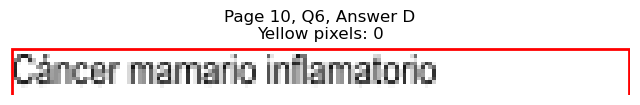

Page 10, Q6 - E: Detected box: x0=327.0, y0=480.8, x1=438.9, y1=493.4
Page 10, Q6, E: Yellow pixels: 1495
Page 10, Q6, E: Total non-white pixels: 2268
Page 10, Q6, E: Yellow percentage: 65.9%


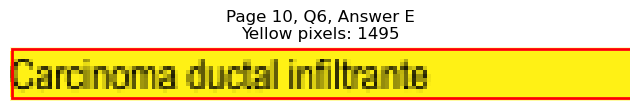


Page 10, Q6 - Selected Answer: E (based on yellow pixel count)




Page 10, Q7 - A: Detected box: x0=68.3, y0=556.5, x1=157.1, y1=569.2
Page 10, Q7, A: Yellow pixels: 0
Page 10, Q7, A: Total non-white pixels: 416
Page 10, Q7, A: Yellow percentage: 0.0%


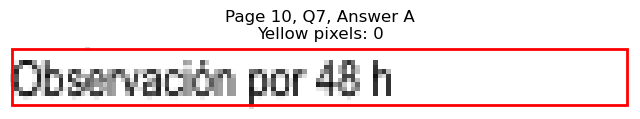

Page 10, Q7 - B: Detected box: x0=68.3, y0=569.1, x1=228.4, y1=581.8
Page 10, Q7, B: Yellow pixels: 0
Page 10, Q7, B: Total non-white pixels: 825
Page 10, Q7, B: Yellow percentage: 0.0%


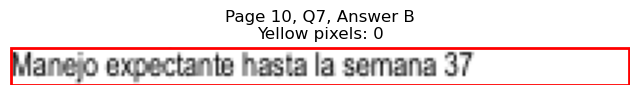

Page 10, Q7 - C: Detected box: x0=68.8, y0=581.7, x1=230.3, y1=594.4
Page 10, Q7, C: Yellow pixels: 0
Page 10, Q7, C: Total non-white pixels: 789
Page 10, Q7, C: Yellow percentage: 0.0%


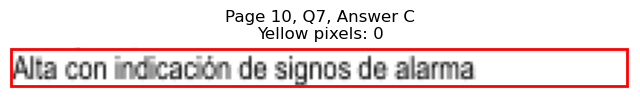

Page 10, Q7 - D: Detected box: x0=327.5, y0=556.5, x1=426.3, y1=569.2
Page 10, Q7, D: Yellow pixels: 1579
Page 10, Q7, D: Total non-white pixels: 2100
Page 10, Q7, D: Yellow percentage: 75.2%


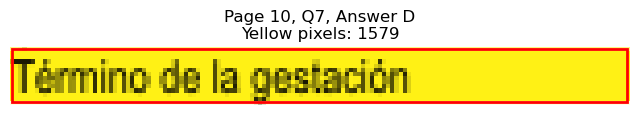

Page 10, Q7 - E: Detected box: x0=327.0, y0=569.1, x1=487.2, y1=581.8
Page 10, Q7, E: Yellow pixels: 0
Page 10, Q7, E: Total non-white pixels: 1003
Page 10, Q7, E: Yellow percentage: 0.0%


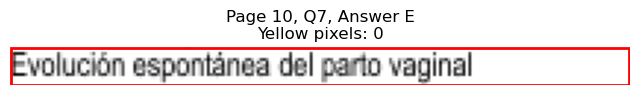


Page 10, Q7 - Selected Answer: D (based on yellow pixel count)




Page 10, Q8 - A: Detected box: x0=68.3, y0=632.2, x1=165.6, y1=644.9
Page 10, Q8, A: Yellow pixels: 0
Page 10, Q8, A: Total non-white pixels: 497
Page 10, Q8, A: Yellow percentage: 0.0%


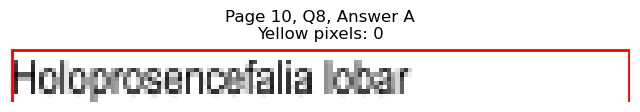

Page 10, Q8 - B: Detected box: x0=68.3, y0=644.9, x1=126.0, y1=657.5
Page 10, Q8, B: Yellow pixels: 0
Page 10, Q8, B: Total non-white pixels: 284
Page 10, Q8, B: Yellow percentage: 0.0%


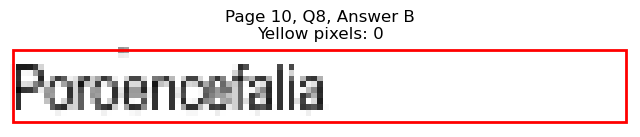

Page 10, Q8 - C: Detected box: x0=68.8, y0=657.5, x1=139.5, y1=670.1
Page 10, Q8, C: Yellow pixels: 0
Page 10, Q8, C: Total non-white pixels: 377
Page 10, Q8, C: Yellow percentage: 0.0%


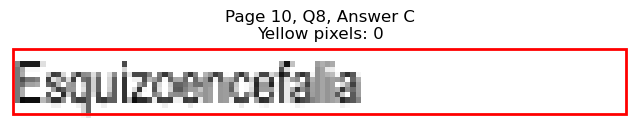

Page 10, Q8 - D: Detected box: x0=327.5, y0=632.2, x1=455.9, y1=644.9
Page 10, Q8, D: Yellow pixels: 1804
Page 10, Q8, D: Total non-white pixels: 2327
Page 10, Q8, D: Yellow percentage: 77.5%


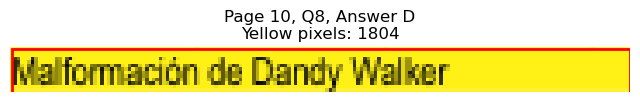

Page 10, Q8 - E: Detected box: x0=327.0, y0=644.9, x1=397.3, y1=657.5
Page 10, Q8, E: Yellow pixels: 0
Page 10, Q8, E: Total non-white pixels: 361
Page 10, Q8, E: Yellow percentage: 0.0%


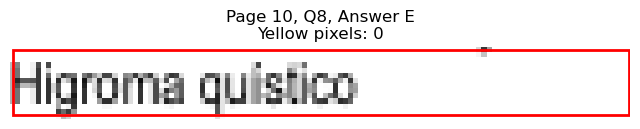


Page 10, Q8 - Selected Answer: D (based on yellow pixel count)




Page 10, Q9 - A: Detected box: x0=68.3, y0=720.6, x1=133.0, y1=733.2
Page 10, Q9, A: Yellow pixels: 0
Page 10, Q9, A: Total non-white pixels: 331
Page 10, Q9, A: Yellow percentage: 0.0%


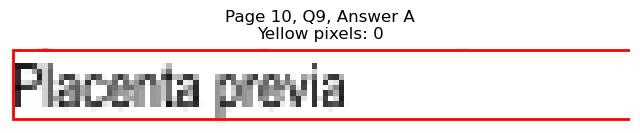

Page 10, Q9 - B: Detected box: x0=68.3, y0=733.2, x1=231.8, y1=745.8
Page 10, Q9, B: Yellow pixels: 0
Page 10, Q9, B: Total non-white pixels: 1038
Page 10, Q9, B: Yellow percentage: 0.0%


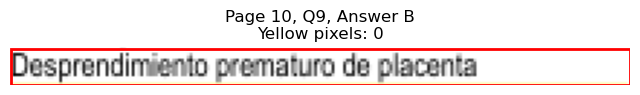

Page 10, Q9 - C: Detected box: x0=68.8, y0=745.8, x1=126.0, y1=758.4
Page 10, Q9, C: Yellow pixels: 1207
Page 10, Q9, C: Total non-white pixels: 1526
Page 10, Q9, C: Yellow percentage: 79.1%


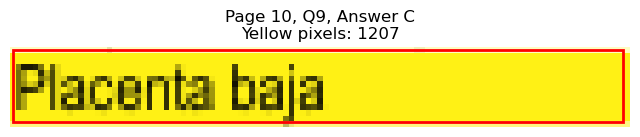

Page 10, Q9 - D: Detected box: x0=327.5, y0=720.6, x1=377.7, y1=733.2
Page 10, Q9, D: Yellow pixels: 0
Page 10, Q9, D: Total non-white pixels: 248
Page 10, Q9, D: Yellow percentage: 0.0%


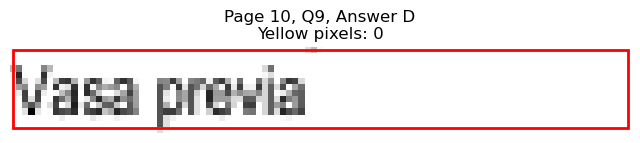

Page 10, Q9 - E: Detected box: x0=327.0, y0=733.2, x1=420.9, y1=745.8
Page 10, Q9, E: Yellow pixels: 0
Page 10, Q9, E: Total non-white pixels: 489
Page 10, Q9, E: Yellow percentage: 0.0%


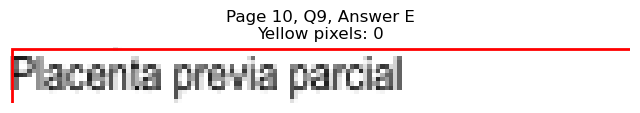


Page 10, Q9 - Selected Answer: C (based on yellow pixel count)





Page 11: Found 9 questions
Page 11, Q1 - A: Detected box: x0=68.3, y0=114.6, x1=145.6, y1=127.3
Page 11, Q1, A: Yellow pixels: 128
Page 11, Q1, A: Total non-white pixels: 520
Page 11, Q1, A: Yellow percentage: 24.6%


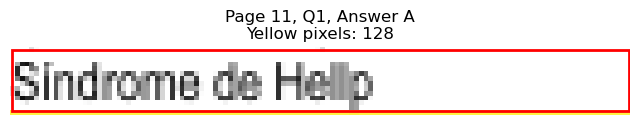

Page 11, Q1 - B: Detected box: x0=68.3, y0=127.2, x1=227.8, y1=139.9
Page 11, Q1, B: Yellow pixels: 2131
Page 11, Q1, B: Total non-white pixels: 2730
Page 11, Q1, B: Yellow percentage: 78.1%


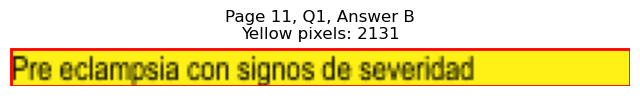

Page 11, Q1 - C: Detected box: x0=68.8, y0=139.9, x1=182.7, y1=152.6
Page 11, Q1, C: Yellow pixels: 159
Page 11, Q1, C: Total non-white pixels: 716
Page 11, Q1, C: Yellow percentage: 22.2%


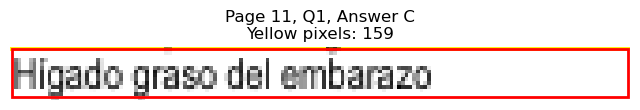

Page 11, Q1 - D: Detected box: x0=327.5, y0=114.6, x1=481.5, y1=127.3
Page 11, Q1, D: Yellow pixels: 0
Page 11, Q1, D: Total non-white pixels: 814
Page 11, Q1, D: Yellow percentage: 0.0%


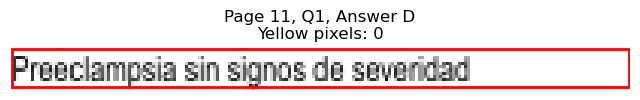

Page 11, Q1 - E: Detected box: x0=327.0, y0=127.2, x1=428.3, y1=139.9
Page 11, Q1, E: Yellow pixels: 0
Page 11, Q1, E: Total non-white pixels: 516
Page 11, Q1, E: Yellow percentage: 0.0%


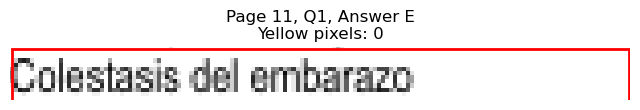


Page 11, Q1 - Selected Answer: B (based on yellow pixel count)




Page 11, Q2 - A: Detected box: x0=68.3, y0=202.9, x1=178.1, y1=215.6
Page 11, Q2, A: Yellow pixels: 0
Page 11, Q2, A: Total non-white pixels: 538
Page 11, Q2, A: Yellow percentage: 0.0%


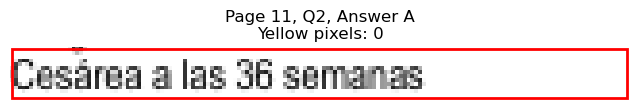

Page 11, Q2 - B: Detected box: x0=68.3, y0=215.7, x1=222.9, y1=228.3
Page 11, Q2, B: Yellow pixels: 0
Page 11, Q2, B: Total non-white pixels: 791
Page 11, Q2, B: Yellow percentage: 0.0%


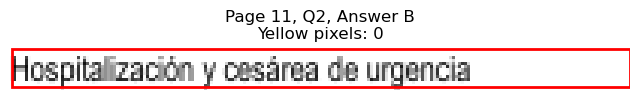

Page 11, Q2 - C: Detected box: x0=68.8, y0=228.3, x1=147.0, y1=240.9
Page 11, Q2, C: Yellow pixels: 0
Page 11, Q2, C: Total non-white pixels: 371
Page 11, Q2, C: Yellow percentage: 0.0%


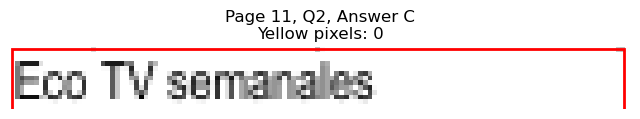

Page 11, Q2 - D: Detected box: x0=327.5, y0=202.9, x1=490.1, y1=215.6
Page 11, Q2, D: Yellow pixels: 0
Page 11, Q2, D: Total non-white pixels: 807
Page 11, Q2, D: Yellow percentage: 0.0%


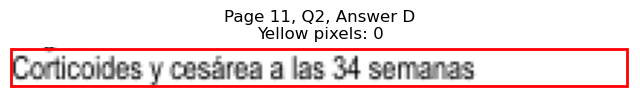

Page 11, Q2 - E: Detected box: x0=327.0, y0=215.7, x1=432.4, y1=228.3
Page 11, Q2, E: Yellow pixels: 1501
Page 11, Q2, E: Total non-white pixels: 2184
Page 11, Q2, E: Yellow percentage: 68.7%


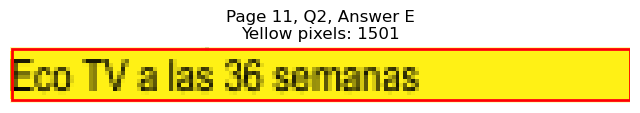


Page 11, Q2 - Selected Answer: E (based on yellow pixel count)




Page 11, Q3 - A: Detected box: x0=68.3, y0=278.8, x1=78.4, y1=291.5
Page 11, Q3, A: Yellow pixels: 761
Page 11, Q3, A: Total non-white pixels: 854
Page 11, Q3, A: Yellow percentage: 89.1%


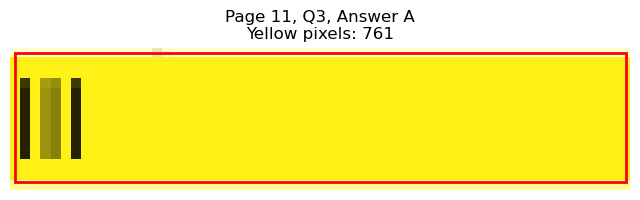

Page 11, Q3 - B: Detected box: x0=56.6, y0=291.4, x1=65.2, y1=304.1
Page 11, Q3, B: Yellow pixels: 60
Page 11, Q3, B: Total non-white pixels: 110
Page 11, Q3, B: Yellow percentage: 54.5%


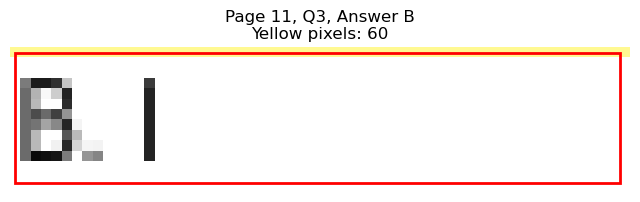

Page 11, Q3 - C: Detected box: x0=56.6, y0=304.0, x1=65.6, y1=316.7
Page 11, Q3, C: Yellow pixels: 0
Page 11, Q3, C: Total non-white pixels: 61
Page 11, Q3, C: Yellow percentage: 0.0%


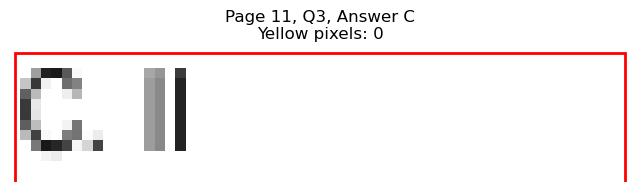

Page 11, Q3 - D: Detected box: x0=327.5, y0=278.8, x1=338.6, y1=291.5
Page 11, Q3, D: Yellow pixels: 0
Page 11, Q3, D: Total non-white pixels: 42
Page 11, Q3, D: Yellow percentage: 0.0%


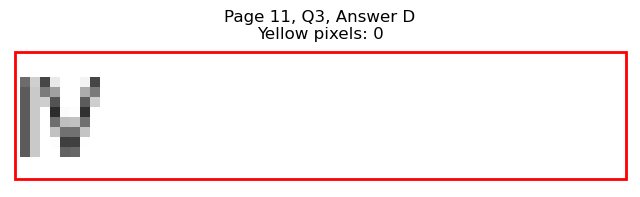

Page 11, Q3 - E: Detected box: x0=327.0, y0=291.4, x1=335.6, y1=304.1
Page 11, Q3, E: Yellow pixels: 0
Page 11, Q3, E: Total non-white pixels: 26
Page 11, Q3, E: Yellow percentage: 0.0%


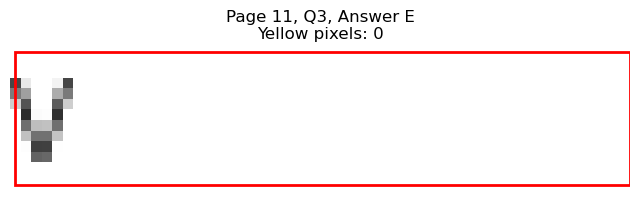


Page 11, Q3 - Selected Answer: A (based on yellow pixel count)




Page 11, Q4 - A: Detected box: x0=68.3, y0=354.5, x1=272.4, y1=367.2
Page 11, Q4, A: Yellow pixels: 9
Page 11, Q4, A: Total non-white pixels: 1049
Page 11, Q4, A: Yellow percentage: 0.9%


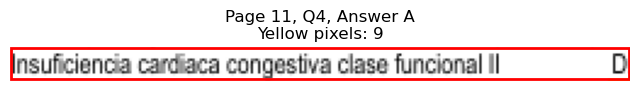

Page 11, Q4 - B: Detected box: x0=68.3, y0=367.1, x1=160.1, y1=379.8
Page 11, Q4, B: Yellow pixels: 0
Page 11, Q4, B: Total non-white pixels: 502
Page 11, Q4, B: Yellow percentage: 0.0%


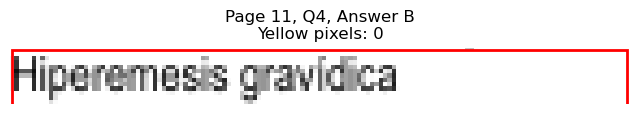

Page 11, Q4 - C: Detected box: x0=68.8, y0=379.7, x1=139.9, y1=392.4
Page 11, Q4, C: Yellow pixels: 0
Page 11, Q4, C: Total non-white pixels: 374
Page 11, Q4, C: Yellow percentage: 0.0%


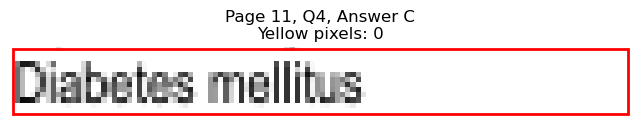

Page 11, Q4 - D: Detected box: x0=327.5, y0=354.5, x1=442.4, y1=367.2
Page 11, Q4, D: Yellow pixels: 166
Page 11, Q4, D: Total non-white pixels: 763
Page 11, Q4, D: Yellow percentage: 21.8%


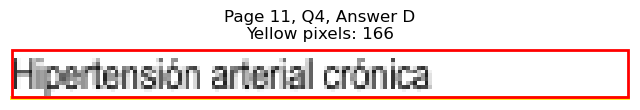

Page 11, Q4 - E: Detected box: x0=327.0, y0=367.1, x1=535.7, y1=379.8
Page 11, Q4, E: Yellow pixels: 1967
Page 11, Q4, E: Total non-white pixels: 2782
Page 11, Q4, E: Yellow percentage: 70.7%


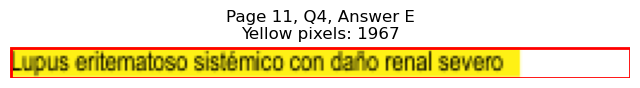


Page 11, Q4 - Selected Answer: E (based on yellow pixel count)




Page 11, Q5 - A: Detected box: x0=68.3, y0=430.2, x1=116.4, y1=442.9
Page 11, Q5, A: Yellow pixels: 0
Page 11, Q5, A: Total non-white pixels: 254
Page 11, Q5, A: Yellow percentage: 0.0%


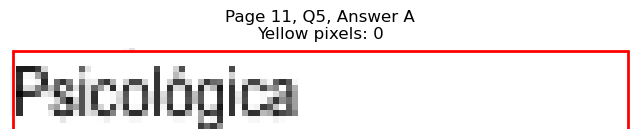

Page 11, Q5 - B: Detected box: x0=68.3, y0=442.8, x1=98.4, y1=455.5
Page 11, Q5, B: Yellow pixels: 0
Page 11, Q5, B: Total non-white pixels: 163
Page 11, Q5, B: Yellow percentage: 0.0%


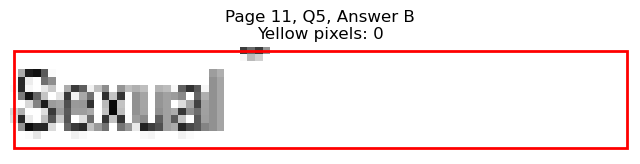

Page 11, Q5 - C: Detected box: x0=68.8, y0=455.5, x1=116.4, y1=468.1
Page 11, Q5, C: Yellow pixels: 0
Page 11, Q5, C: Total non-white pixels: 258
Page 11, Q5, C: Yellow percentage: 0.0%


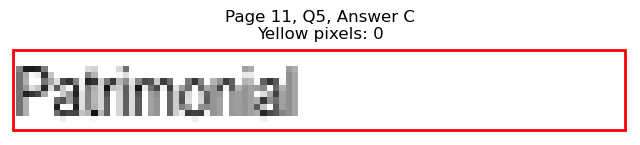

Page 11, Q5 - D: Detected box: x0=327.5, y0=430.2, x1=353.6, y1=442.9
Page 11, Q5, D: Yellow pixels: 904
Page 11, Q5, D: Total non-white pixels: 1001
Page 11, Q5, D: Yellow percentage: 90.3%


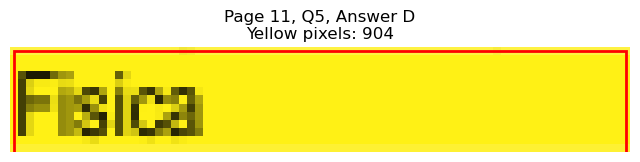

Page 11, Q5 - E: Detected box: x0=327.0, y0=442.8, x1=374.2, y1=455.5
Page 11, Q5, E: Yellow pixels: 98
Page 11, Q5, E: Total non-white pixels: 335
Page 11, Q5, E: Yellow percentage: 29.3%


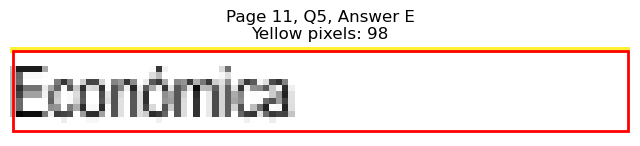


Page 11, Q5 - Selected Answer: D (based on yellow pixel count)




Page 11, Q6 - A: Detected box: x0=68.3, y0=506.0, x1=148.0, y1=518.6
Page 11, Q6, A: Yellow pixels: 0
Page 11, Q6, A: Total non-white pixels: 382
Page 11, Q6, A: Yellow percentage: 0.0%


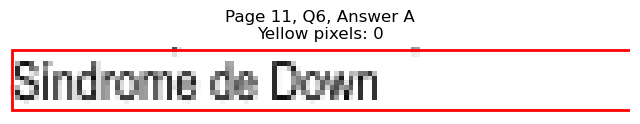

Page 11, Q6 - B: Detected box: x0=68.3, y0=518.6, x1=118.0, y1=531.2
Page 11, Q6, B: Yellow pixels: 100
Page 11, Q6, B: Total non-white pixels: 328
Page 11, Q6, B: Yellow percentage: 30.5%


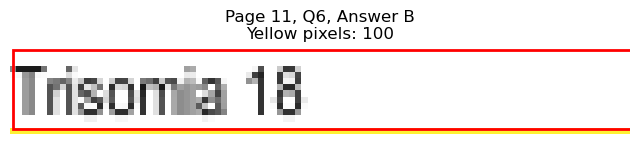

Page 11, Q6 - C: Detected box: x0=68.8, y0=531.2, x1=152.1, y1=543.8
Page 11, Q6, C: Yellow pixels: 1456
Page 11, Q6, C: Total non-white pixels: 1755
Page 11, Q6, C: Yellow percentage: 83.0%


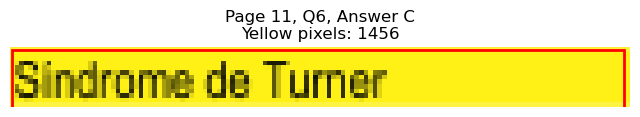

Page 11, Q6 - D: Detected box: x0=327.5, y0=506.0, x1=377.2, y1=518.6
Page 11, Q6, D: Yellow pixels: 0
Page 11, Q6, D: Total non-white pixels: 230
Page 11, Q6, D: Yellow percentage: 0.0%


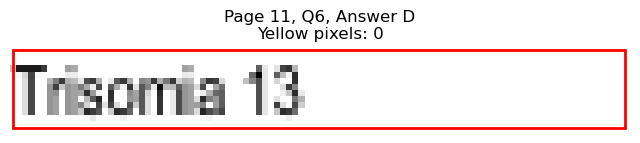

Page 11, Q6 - E: Detected box: x0=327.0, y0=518.6, x1=423.9, y1=531.2
Page 11, Q6, E: Yellow pixels: 0
Page 11, Q6, E: Total non-white pixels: 489
Page 11, Q6, E: Yellow percentage: 0.0%


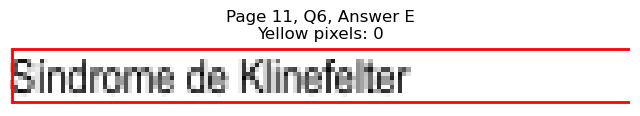


Page 11, Q6 - Selected Answer: C (based on yellow pixel count)




Page 11, Q7 - A: Detected box: x0=68.3, y0=569.1, x1=239.8, y1=581.8
Page 11, Q7, A: Yellow pixels: 0
Page 11, Q7, A: Total non-white pixels: 854
Page 11, Q7, A: Yellow percentage: 0.0%


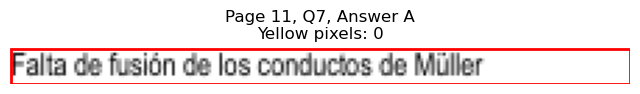

Page 11, Q7 - B: Detected box: x0=68.3, y0=581.7, x1=252.9, y1=594.4
Page 11, Q7, B: Yellow pixels: 0
Page 11, Q7, B: Total non-white pixels: 913
Page 11, Q7, B: Yellow percentage: 0.0%


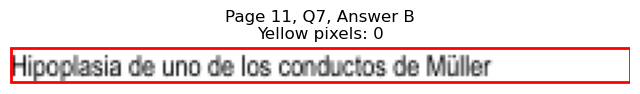

Page 11, Q7 - C: Detected box: x0=68.8, y0=594.3, x1=226.4, y1=607.0
Page 11, Q7, C: Yellow pixels: 0
Page 11, Q7, C: Total non-white pixels: 775
Page 11, Q7, C: Yellow percentage: 0.0%


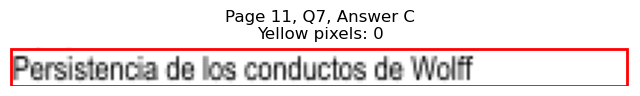

Page 11, Q7 - D: Detected box: x0=327.5, y0=569.1, x1=477.6, y1=581.8
Page 11, Q7, D: Yellow pixels: 2028
Page 11, Q7, D: Total non-white pixels: 2613
Page 11, Q7, D: Yellow percentage: 77.6%


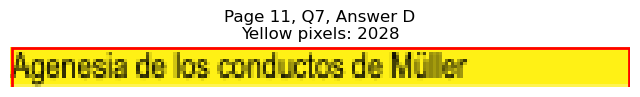

Page 11, Q7 - E: Detected box: x0=327.0, y0=581.7, x1=494.6, y1=594.4
Page 11, Q7, E: Yellow pixels: 211
Page 11, Q7, E: Total non-white pixels: 1042
Page 11, Q7, E: Yellow percentage: 20.2%


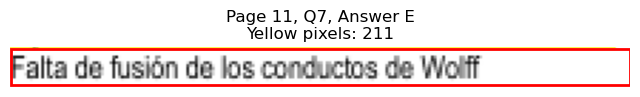


Page 11, Q7 - Selected Answer: D (based on yellow pixel count)




Page 11, Q8 - A: Detected box: x0=68.3, y0=644.9, x1=133.0, y1=657.5
Page 11, Q8, A: Yellow pixels: 115
Page 11, Q8, A: Total non-white pixels: 437
Page 11, Q8, A: Yellow percentage: 26.3%


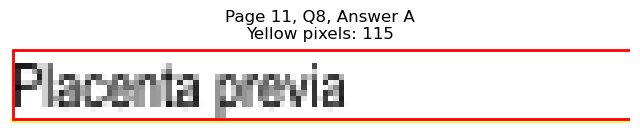

Page 11, Q8 - B: Detected box: x0=68.3, y0=657.5, x1=125.4, y1=670.1
Page 11, Q8, B: Yellow pixels: 1162
Page 11, Q8, B: Total non-white pixels: 1512
Page 11, Q8, B: Yellow percentage: 76.9%


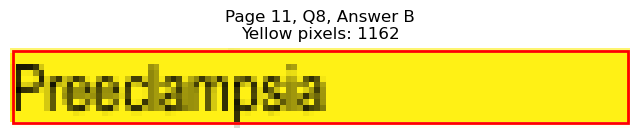

Page 11, Q8 - C: Detected box: x0=68.8, y0=670.1, x1=232.2, y1=682.7
Page 11, Q8, C: Yellow pixels: 0
Page 11, Q8, C: Total non-white pixels: 1036
Page 11, Q8, C: Yellow percentage: 0.0%


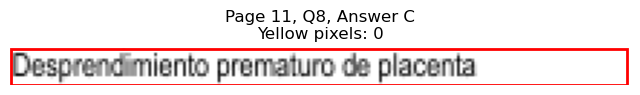

Page 11, Q8 - D: Detected box: x0=327.5, y0=644.9, x1=413.8, y1=657.5
Page 11, Q8, D: Yellow pixels: 0
Page 11, Q8, D: Total non-white pixels: 460
Page 11, Q8, D: Yellow percentage: 0.0%


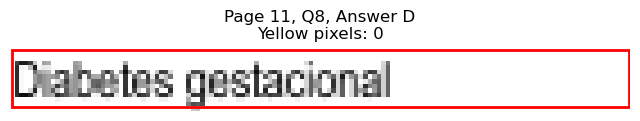

Page 11, Q8 - E: Detected box: x0=327.0, y0=657.5, x1=408.8, y1=670.1
Page 11, Q8, E: Yellow pixels: 0
Page 11, Q8, E: Total non-white pixels: 455
Page 11, Q8, E: Yellow percentage: 0.0%


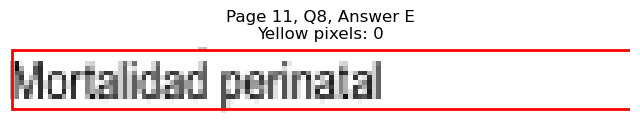


Page 11, Q8 - Selected Answer: B (based on yellow pixel count)




Page 11, Q9 - A: Detected box: x0=68.3, y0=733.2, x1=142.6, y1=745.8
Page 11, Q9, A: Yellow pixels: 0
Page 11, Q9, A: Total non-white pixels: 380
Page 11, Q9, A: Yellow percentage: 0.0%


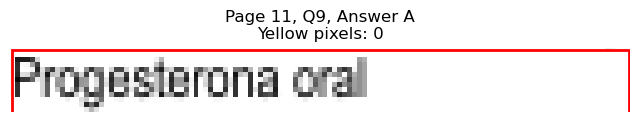

Page 11, Q9 - B: Detected box: x0=68.3, y0=745.8, x1=156.0, y1=758.4
Page 11, Q9, B: Yellow pixels: 0
Page 11, Q9, B: Total non-white pixels: 434
Page 11, Q9, B: Yellow percentage: 0.0%


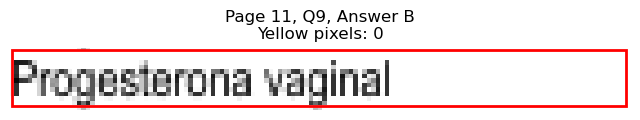

Page 11, Q9 - C: Detected box: x0=68.8, y0=758.5, x1=125.5, y1=771.2
Page 11, Q9, C: Yellow pixels: 0
Page 11, Q9, C: Total non-white pixels: 300
Page 11, Q9, C: Yellow percentage: 0.0%


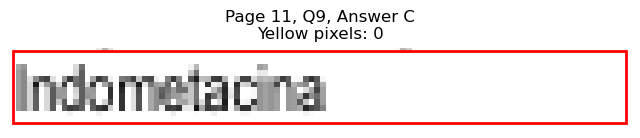

Page 11, Q9 - D: Detected box: x0=327.5, y0=733.2, x1=380.7, y1=745.8
Page 11, Q9, D: Yellow pixels: 1150
Page 11, Q9, D: Total non-white pixels: 1352
Page 11, Q9, D: Yellow percentage: 85.1%


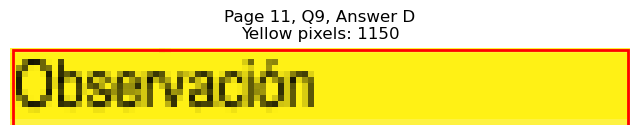

Page 11, Q9 - E: Detected box: x0=327.0, y0=745.8, x1=393.2, y1=758.4
Page 11, Q9, E: Yellow pixels: 117
Page 11, Q9, E: Total non-white pixels: 472
Page 11, Q9, E: Yellow percentage: 24.8%


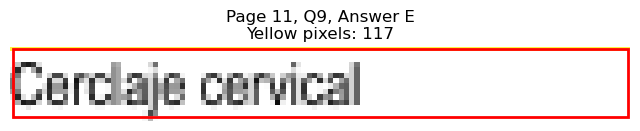


Page 11, Q9 - Selected Answer: D (based on yellow pixel count)





Page 12: Found 8 questions
Page 12, Q1 - A: Detected box: x0=68.3, y0=102.0, x1=141.0, y1=114.7
Page 12, Q1, A: Yellow pixels: 0
Page 12, Q1, A: Total non-white pixels: 348
Page 12, Q1, A: Yellow percentage: 0.0%


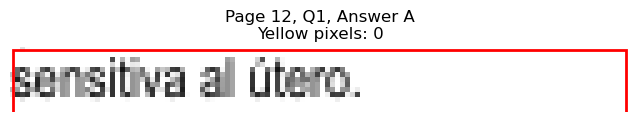

Page 12, Q1 - B: Detected box: x0=68.3, y0=114.6, x1=144.5, y1=127.3
Page 12, Q1, B: Yellow pixels: 127
Page 12, Q1, B: Total non-white pixels: 463
Page 12, Q1, B: Yellow percentage: 27.4%


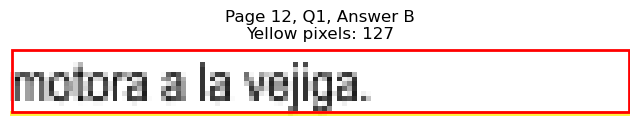

Page 12, Q1 - C: Detected box: x0=68.8, y0=127.2, x1=227.8, y1=139.9
Page 12, Q1, C: Yellow pixels: 2127
Page 12, Q1, C: Total non-white pixels: 2730
Page 12, Q1, C: Yellow percentage: 77.9%


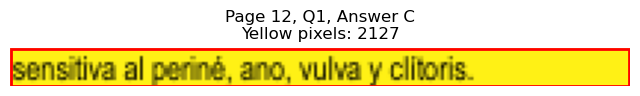

Page 12, Q1 - D: Detected box: x0=327.5, y0=102.0, x1=475.5, y1=114.7
Page 12, Q1, D: Yellow pixels: 0
Page 12, Q1, D: Total non-white pixels: 692
Page 12, Q1, D: Yellow percentage: 0.0%


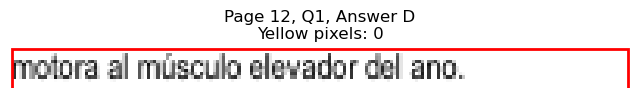

Page 12, Q1 - E: Detected box: x0=327.0, y0=114.6, x1=477.1, y1=127.3
Page 12, Q1, E: Yellow pixels: 0
Page 12, Q1, E: Total non-white pixels: 717
Page 12, Q1, E: Yellow percentage: 0.0%


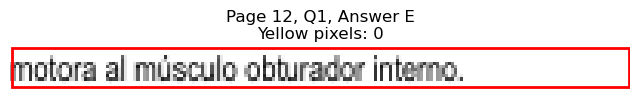


Page 12, Q1 - Selected Answer: C (based on yellow pixel count)




Page 12, Q2 - A: Detected box: x0=68.3, y0=190.3, x1=177.6, y1=203.0
Page 12, Q2, A: Yellow pixels: 0
Page 12, Q2, A: Total non-white pixels: 557
Page 12, Q2, A: Yellow percentage: 0.0%


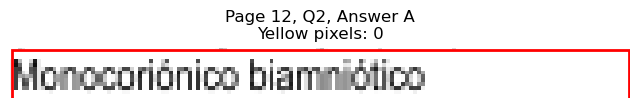

Page 12, Q2 - B: Detected box: x0=68.3, y0=202.9, x1=193.2, y1=215.6
Page 12, Q2, B: Yellow pixels: 0
Page 12, Q2, B: Total non-white pixels: 611
Page 12, Q2, B: Yellow percentage: 0.0%


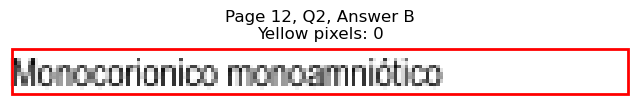

Page 12, Q2 - C: Detected box: x0=68.8, y0=215.7, x1=163.6, y1=228.3
Page 12, Q2, C: Yellow pixels: 1389
Page 12, Q2, C: Total non-white pixels: 2044
Page 12, Q2, C: Yellow percentage: 68.0%


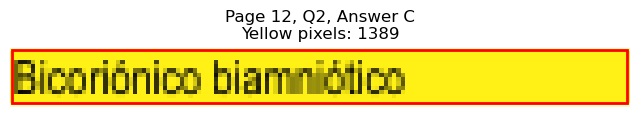

Page 12, Q2 - D: Detected box: x0=327.5, y0=190.3, x1=437.8, y1=203.0
Page 12, Q2, D: Yellow pixels: 0
Page 12, Q2, D: Total non-white pixels: 558
Page 12, Q2, D: Yellow percentage: 0.0%


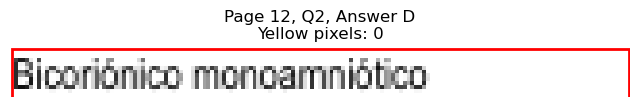

Page 12, Q2 - E: Detected box: x0=327.0, y0=202.9, x1=406.3, y1=215.6
Page 12, Q2, E: Yellow pixels: 0
Page 12, Q2, E: Total non-white pixels: 414
Page 12, Q2, E: Yellow percentage: 0.0%


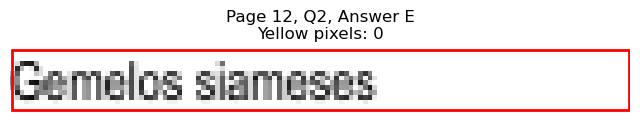


Page 12, Q2 - Selected Answer: C (based on yellow pixel count)




Page 12, Q3 - A: Detected box: x0=68.3, y0=253.5, x1=122.4, y1=266.1
Page 12, Q3, A: Yellow pixels: 0
Page 12, Q3, A: Total non-white pixels: 248
Page 12, Q3, A: Yellow percentage: 0.0%


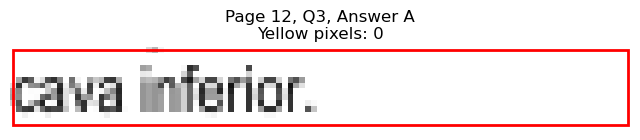

Page 12, Q3 - B: Detected box: x0=68.3, y0=266.1, x1=100.9, y1=278.7
Page 12, Q3, B: Yellow pixels: 0
Page 12, Q3, B: Total non-white pixels: 151
Page 12, Q3, B: Yellow percentage: 0.0%


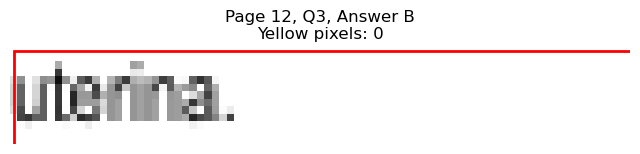

Page 12, Q3 - C: Detected box: x0=68.8, y0=278.8, x1=127.0, y1=291.5
Page 12, Q3, C: Yellow pixels: 0
Page 12, Q3, C: Total non-white pixels: 287
Page 12, Q3, C: Yellow percentage: 0.0%


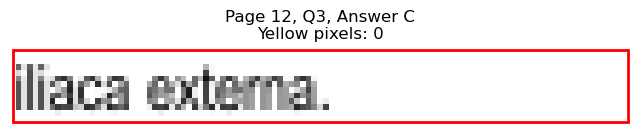

Page 12, Q3 - D: Detected box: x0=327.5, y0=253.5, x1=391.7, y1=266.1
Page 12, Q3, D: Yellow pixels: 1282
Page 12, Q3, D: Total non-white pixels: 1610
Page 12, Q3, D: Yellow percentage: 79.6%


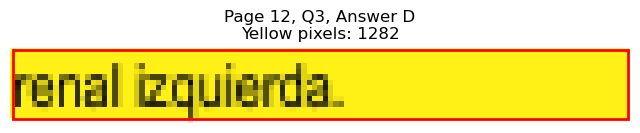

Page 12, Q3 - E: Detected box: x0=327.0, y0=266.1, x1=382.7, y1=278.7
Page 12, Q3, E: Yellow pixels: 0
Page 12, Q3, E: Total non-white pixels: 385
Page 12, Q3, E: Yellow percentage: 0.0%


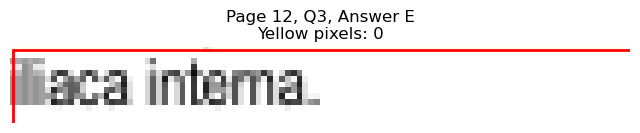


Page 12, Q3 - Selected Answer: D (based on yellow pixel count)




Page 12, Q4 - A: Detected box: x0=68.3, y0=341.9, x1=143.5, y1=354.6
Page 12, Q4, A: Yellow pixels: 0
Page 12, Q4, A: Total non-white pixels: 392
Page 12, Q4, A: Yellow percentage: 0.0%


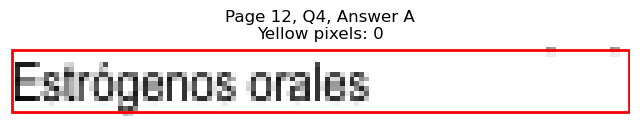

Page 12, Q4 - B: Detected box: x0=68.3, y0=354.5, x1=184.7, y1=367.2
Page 12, Q4, B: Yellow pixels: 0
Page 12, Q4, B: Total non-white pixels: 566
Page 12, Q4, B: Yellow percentage: 0.0%


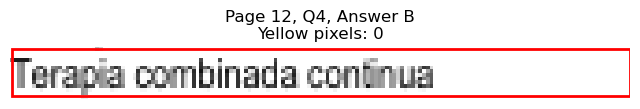

Page 12, Q4 - C: Detected box: x0=68.8, y0=367.1, x1=158.1, y1=379.8
Page 12, Q4, C: Yellow pixels: 0
Page 12, Q4, C: Total non-white pixels: 477
Page 12, Q4, C: Yellow percentage: 0.0%


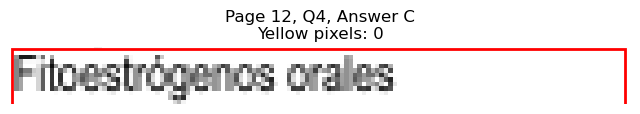

Page 12, Q4 - D: Detected box: x0=327.5, y0=341.9, x1=406.7, y1=354.6
Page 12, Q4, D: Yellow pixels: 1374
Page 12, Q4, D: Total non-white pixels: 1820
Page 12, Q4, D: Yellow percentage: 75.5%


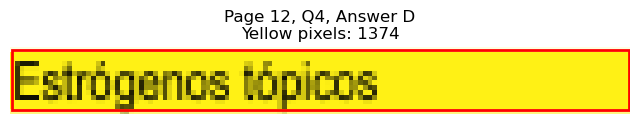

Page 12, Q4 - E: Detected box: x0=327.0, y0=354.5, x1=452.0, y1=367.2
Page 12, Q4, E: Yellow pixels: 173
Page 12, Q4, E: Total non-white pixels: 795
Page 12, Q4, E: Yellow percentage: 21.8%


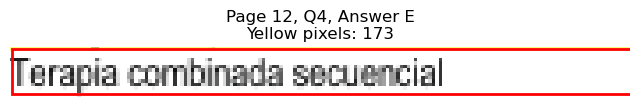


Page 12, Q4 - Selected Answer: D (based on yellow pixel count)




Page 12, Q5 - A: Detected box: x0=68.3, y0=430.2, x1=151.6, y1=442.9
Page 12, Q5, A: Yellow pixels: 0
Page 12, Q5, A: Total non-white pixels: 362
Page 12, Q5, A: Yellow percentage: 0.0%


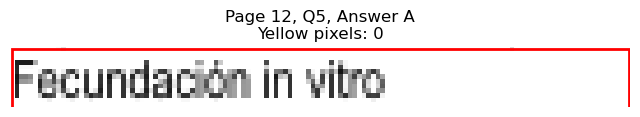

Page 12, Q5 - B: Detected box: x0=68.3, y0=442.8, x1=212.2, y1=455.5
Page 12, Q5, B: Yellow pixels: 195
Page 12, Q5, B: Total non-white pixels: 924
Page 12, Q5, B: Yellow percentage: 21.1%


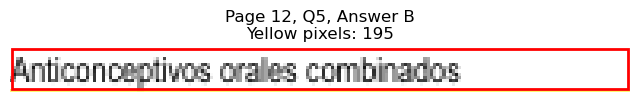

Page 12, Q5 - C: Detected box: x0=68.8, y0=455.5, x1=127.0, y1=468.1
Page 12, Q5, C: Yellow pixels: 1192
Page 12, Q5, C: Total non-white pixels: 1526
Page 12, Q5, C: Yellow percentage: 78.1%


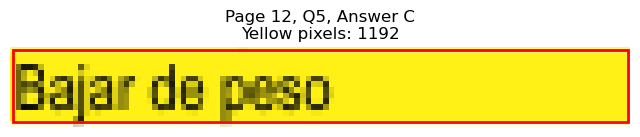

Page 12, Q5 - D: Detected box: x0=327.5, y0=430.2, x1=420.8, y1=442.9
Page 12, Q5, D: Yellow pixels: 0
Page 12, Q5, D: Total non-white pixels: 480
Page 12, Q5, D: Yellow percentage: 0.0%


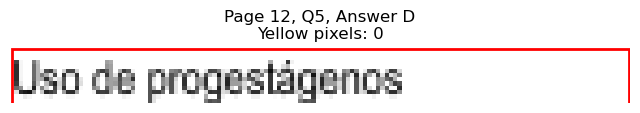

Page 12, Q5 - E: Detected box: x0=327.0, y0=442.8, x1=415.9, y1=455.5
Page 12, Q5, E: Yellow pixels: 0
Page 12, Q5, E: Total non-white pixels: 482
Page 12, Q5, E: Yellow percentage: 0.0%


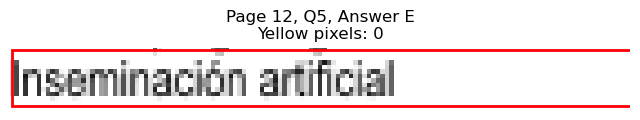


Page 12, Q5 - Selected Answer: C (based on yellow pixel count)




Page 12, Q6 - A: Detected box: x0=56.6, y0=531.2, x1=65.2, y1=543.8
Page 12, Q6, A: Yellow pixels: 0
Page 12, Q6, A: Total non-white pixels: 46
Page 12, Q6, A: Yellow percentage: 0.0%


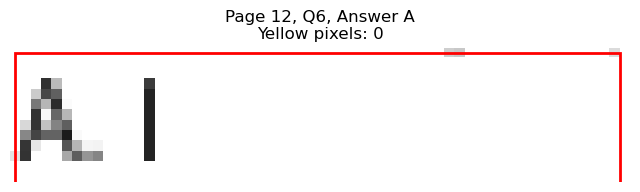

Page 12, Q6 - B: Detected box: x0=68.3, y0=543.8, x1=78.4, y1=556.4
Page 12, Q6, B: Yellow pixels: 0
Page 12, Q6, B: Total non-white pixels: 32
Page 12, Q6, B: Yellow percentage: 0.0%


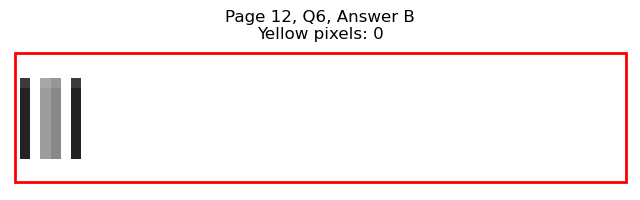

Page 12, Q6 - C: Detected box: x0=68.8, y0=556.5, x1=79.8, y1=569.2
Page 12, Q6, C: Yellow pixels: 0
Page 12, Q6, C: Total non-white pixels: 44
Page 12, Q6, C: Yellow percentage: 0.0%


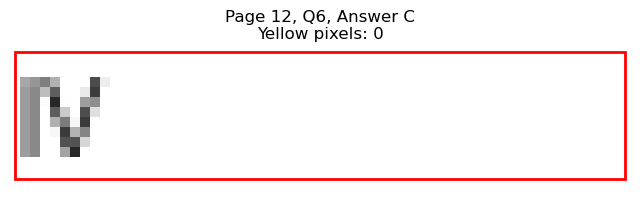

Page 12, Q6 - D: Detected box: x0=315.4, y0=531.2, x1=324.4, y1=543.8
Page 12, Q6, D: Yellow pixels: 0
Page 12, Q6, D: Total non-white pixels: 129
Page 12, Q6, D: Yellow percentage: 0.0%


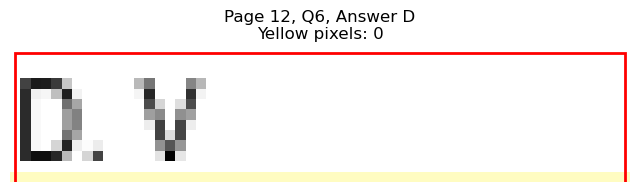

Page 12, Q6 - E: Detected box: x0=315.4, y0=543.8, x1=323.9, y1=556.4
Page 12, Q6, E: Yellow pixels: 717
Page 12, Q6, E: Total non-white pixels: 826
Page 12, Q6, E: Yellow percentage: 86.8%


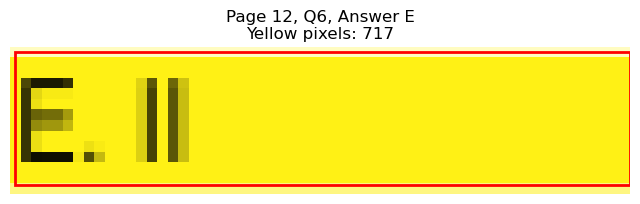


Page 12, Q6 - Selected Answer: E (based on yellow pixel count)




Page 12, Q7 - A: Detected box: x0=68.3, y0=619.6, x1=149.5, y1=632.3
Page 12, Q7, A: Yellow pixels: 0
Page 12, Q7, A: Total non-white pixels: 417
Page 12, Q7, A: Yellow percentage: 0.0%


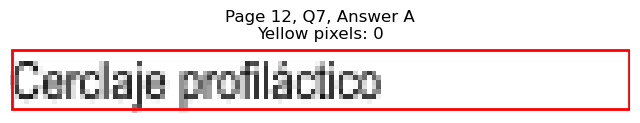

Page 12, Q7 - B: Detected box: x0=68.3, y0=632.2, x1=138.5, y1=644.9
Page 12, Q7, B: Yellow pixels: 0
Page 12, Q7, B: Total non-white pixels: 357
Page 12, Q7, B: Yellow percentage: 0.0%


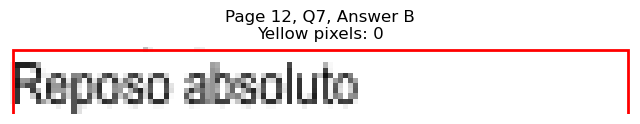

Page 12, Q7 - C: Detected box: x0=68.8, y0=644.9, x1=169.1, y1=657.5
Page 12, Q7, C: Yellow pixels: 0
Page 12, Q7, C: Total non-white pixels: 490
Page 12, Q7, C: Yellow percentage: 0.0%


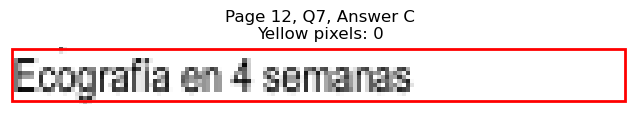

Page 12, Q7 - D: Detected box: x0=327.5, y0=619.6, x1=414.3, y1=632.3
Page 12, Q7, D: Yellow pixels: 1330
Page 12, Q7, D: Total non-white pixels: 1932
Page 12, Q7, D: Yellow percentage: 68.8%


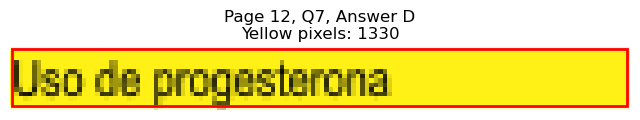

Page 12, Q7 - E: Detected box: x0=327.0, y0=632.2, x1=399.3, y1=644.9
Page 12, Q7, E: Yellow pixels: 0
Page 12, Q7, E: Total non-white pixels: 493
Page 12, Q7, E: Yellow percentage: 0.0%


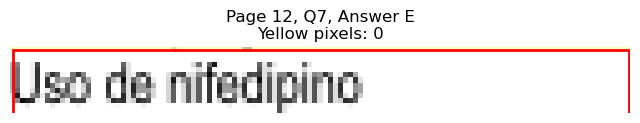


Page 12, Q7 - Selected Answer: D (based on yellow pixel count)




Page 12, Q8 - A: Detected box: x0=68.3, y0=720.6, x1=185.2, y1=733.2
Page 12, Q8, A: Yellow pixels: 0
Page 12, Q8, A: Total non-white pixels: 576
Page 12, Q8, A: Yellow percentage: 0.0%


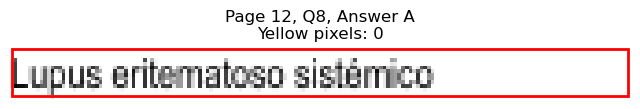

Page 12, Q8 - B: Detected box: x0=68.3, y0=733.2, x1=149.5, y1=745.8
Page 12, Q8, B: Yellow pixels: 0
Page 12, Q8, B: Total non-white pixels: 412
Page 12, Q8, B: Yellow percentage: 0.0%


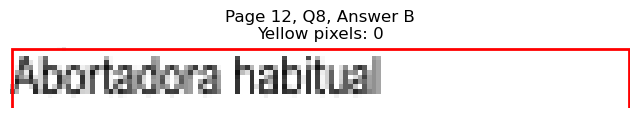

Page 12, Q8 - C: Detected box: x0=68.8, y0=745.8, x1=189.6, y1=758.4
Page 12, Q8, C: Yellow pixels: 0
Page 12, Q8, C: Total non-white pixels: 614
Page 12, Q8, C: Yellow percentage: 0.0%


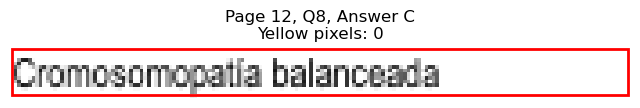

Page 12, Q8 - D: Detected box: x0=327.5, y0=720.6, x1=421.9, y1=733.2
Page 12, Q8, D: Yellow pixels: 145
Page 12, Q8, D: Total non-white pixels: 617
Page 12, Q8, D: Yellow percentage: 23.5%


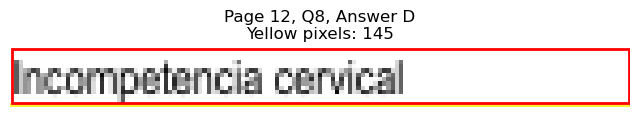

Page 12, Q8 - E: Detected box: x0=327.0, y0=733.2, x1=430.9, y1=745.8
Page 12, Q8, E: Yellow pixels: 1588
Page 12, Q8, E: Total non-white pixels: 2002
Page 12, Q8, E: Yellow percentage: 79.3%


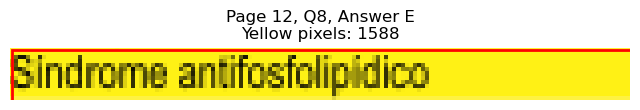


Page 12, Q8 - Selected Answer: E (based on yellow pixel count)






In [6]:
questions_df = extract_questions(pdf_path = pdf_file)
answers_df = extract_answers(pdf_path = pdf_file)
correct_answers_df = extract_correct_answers(pdf_path = pdf_file)

In [7]:
questions_df

,question
0,"Gestante de 22 semanas, en la ecografía morfol..."
1,"Gestante de 16 semanas en control prenatal, as..."
2,¿Cuál es el factor de riesgo endógeno más impo...
3,Mujer de 23 años con tumoración de 2 cm en el ...
4,"Tercigesta de 33 semanas, con sangrado vaginal..."
...,...
95,"Mujer de 51 años, con sequedad vaginal y dispa..."
96,"Mujer de 31 años con IMC 34 Kg/m2, acude a con..."
97,Gestante de 32 semanas con embarazo gemelar mo...
98,"Mujer 25 años, G2 P1001, acude a consulta por ..."


In [8]:
answers_df

,option_A,option_B,option_C,option_D,option_E
0,Megavejiga asociada a aneuploidia,Divertículo uretral,Válvulas uretrales posteriores,Agenesia uretral,Estenosis del meato uretral
1,Tratamiento supresivo por el resto del embarazo,Observación,Hospitalización y antibióticos parenterales,Ecografía renal,Tratamiento antibiótico VO
2,Menarquia temprana,Obesidad,Menopausia tardía,Nuliparidad,Antecedente de infertilidad
3,Absceso mamario,Ectasia conductos mamarios,Carcinoma,Necrosis grasa,Fibroadenoma
4,Acretismo placentario,Desprendimiento prematuro de placenta,Infartos placentarios,Vasa previa,Hematomas placentarios
...,...,...,...,...,...
95,Estrógenos orales,Terapia combinada continua,Fitoestrógenos orales,Estrógenos tópicos,Terapia combinada secuencial
96,Fecundación in vitro,Anticonceptivos orales combinados,Bajar de peso,Uso de progestágenos,Inseminación artificial
97,I,III,IV,V,II
98,Cerclaje profiláctico,Reposo absoluto,Ecografía en 4 semanas,Uso de progesterona,Uso de nifedipino


In [9]:
correct_answers_df

,correct_answer
0,C
1,E
2,B
3,E
4,A
...,...
95,D
96,C
97,E
98,D


In [10]:
total_df = pd.concat([questions_df, answers_df, correct_answers_df], ignore_index = True, axis = 1)
total_df.columns = ["questions", "option_A", "option_B", "option_C", "option_D", "option_E", "correct_answer"]
total_df

,questions,option_A,option_B,option_C,option_D,option_E,correct_answer
0,"Gestante de 22 semanas, en la ecografía morfol...",Megavejiga asociada a aneuploidia,Divertículo uretral,Válvulas uretrales posteriores,Agenesia uretral,Estenosis del meato uretral,C
1,"Gestante de 16 semanas en control prenatal, as...",Tratamiento supresivo por el resto del embarazo,Observación,Hospitalización y antibióticos parenterales,Ecografía renal,Tratamiento antibiótico VO,E
2,¿Cuál es el factor de riesgo endógeno más impo...,Menarquia temprana,Obesidad,Menopausia tardía,Nuliparidad,Antecedente de infertilidad,B
3,Mujer de 23 años con tumoración de 2 cm en el ...,Absceso mamario,Ectasia conductos mamarios,Carcinoma,Necrosis grasa,Fibroadenoma,E
4,"Tercigesta de 33 semanas, con sangrado vaginal...",Acretismo placentario,Desprendimiento prematuro de placenta,Infartos placentarios,Vasa previa,Hematomas placentarios,A
...,...,...,...,...,...,...,...
95,"Mujer de 51 años, con sequedad vaginal y dispa...",Estrógenos orales,Terapia combinada continua,Fitoestrógenos orales,Estrógenos tópicos,Terapia combinada secuencial,D
96,"Mujer de 31 años con IMC 34 Kg/m2, acude a con...",Fecundación in vitro,Anticonceptivos orales combinados,Bajar de peso,Uso de progestágenos,Inseminación artificial,C
97,Gestante de 32 semanas con embarazo gemelar mo...,I,III,IV,V,II,E
98,"Mujer 25 años, G2 P1001, acude a consulta por ...",Cerclaje profiláctico,Reposo absoluto,Ecografía en 4 semanas,Uso de progesterona,Uso de nifedipino,D


In [11]:
# Extract folder path
folder_path = os.path.dirname(pdf_file)  # Gets the directory path

# Extract filename without extension
file_name = os.path.splitext(os.path.basename(pdf_file))[0]  # Removes the .pdf extension

# Create CSV file path
csv_file = os.path.join(folder_path, f"{file_name}.csv")

# Save a sample DataFrame
total_df.to_csv(csv_file, index=False, encoding="utf-8-sig")
print(f"CSV saved at: {csv_file}")


CSV saved at: /Users/rodrigocarrillo/Library/CloudStorage/OneDrive-EmoryUniversity/Natural Language Processing Projects/Examen Residentado Peru/CONAREME/Year2022/Ginecología y Obstetricia.csv
